# Clustering integral de artistas musicales — workflow completo
**"Streaming, redes sociales y conciertos: construcción empírica del éxito de un artista musical"**  
Autora: Silvana Contreras — Mayo 2026

**Métodos:** K-Medoids (PAM)  ·  GMM (full & tied)  ·  Spectral Clustering (kNN)  ·  RF Feature Importance  
**Visualización:** UMAP 2D (no lineal)  
**Datasets:** 7 000 artistas para clustering · 4 913 con dato de shows para interpretación

# conjuntos

In [1]:
# # ============================================================
# # Paso 2. Agrupación conceptual de variables
# # ============================================================

# id_cols = [
#     "chartmetric_id",
#     "artist_name"
# ]

# metadata_cols = [
#     "country",
#     "country_short",
#     "pronoun_title",
#     "pronoun_short",
#     "record_label",
#     "major_record_label",
#     "primary_genre",
#     "genre_short",
#     "band",
#     "muerto_disuelto"
# ]

# streaming_cols = [
#     "sp_followers",
#     "sp_monthly_listeners",
#     "sp_popularity",
#     "deezer_fans",
#     "shazam_count",
#     "pandora_lifetime_streams",
#     "pandora_lifetime_stations_added"
# ]

# playlist_cols = [
#     "sp_playlist_total_reach",
#     "num_sp_editorial_playlists",
#     "num_sp_playlists",
#     "sp_editorial_playlist_total_reach",
#     "num_am_editorial_playlists",
#     "num_am_playlists",
#     "num_de_editorial_playlists",
#     "num_de_playlists",
#     "de_playlist_total_reach",
#     "de_editorial_playlist_total_reach",
#     "num_az_editorial_playlists",
#     "num_az_playlists",
#     "num_yt_editorial_playlists",
#     "num_yt_playlists",
#     "yt_playlist_total_reach"
# ]

# social_cols = [
#     "ins_followers",
#     "twitter_followers",
#     "tiktok_followers",
#     "tiktok_likes",
#     "tiktok_top_video_views",
#     "tiktok_top_video_comments",
#     "tiktok_track_posts"
# ]

# youtube_cols = [
#     "ycs_subscribers",
#     "ycs_views",
#     "youtube_daily_video_views",
#     "youtube_monthly_video_views"
# ]

# live_cols = [
#     "n_shows_24_25",
#     "n_shows_with_capacity_24_25",
#     "capacity_24_25",
#     "avg_venue_capacity_24_25",
#     "n_cities_24_25",
#     "n_countries_24_25",
#     "shows_per_country_24_25",
#     "off_cycle"
# ]

# # Diccionario de dimensiones
# column_groups = {
#     "identificacion": id_cols,
#     "metadata": metadata_cols,
#     "streaming": streaming_cols,
#     "playlists": playlist_cols,
#     "redes_sociales": social_cols,
#     "youtube": youtube_cols,
#     "live_events": live_cols
# }

# # Control de cobertura de columnas
# grouped_cols = [col for cols in column_groups.values() for col in cols]

# cols_in_groups_not_in_df = sorted(set(grouped_cols) - set(df.columns))
# cols_in_df_not_in_groups = sorted(set(df.columns) - set(grouped_cols))

# print("Columnas del df:", df.shape[1])
# print("Columnas agrupadas:", len(grouped_cols))
# print("Columnas agrupadas que no están en df:", cols_in_groups_not_in_df)
# print("Columnas del df no agrupadas:", cols_in_df_not_in_groups)

# # Resumen por dimensión
# for group_name, cols in column_groups.items():
#     print(f"{group_name}: {len(cols)} variables")

# paleta dimensiones

In [2]:
# palette_dimension = {
#     "streaming": "#636EFA",
#     "playlists": "#EF553B",
#     "redes sociales": "#06D49D",
#     "youtube": "#AB63FA",
#     "metadata": "#7F7F7F",
#     "ratios entre plataformas": "#FAF440",
# }

# colors_dimension = [
#     palette_dimension.get(dim, "#333333")
#     for dim in df_plot_dimension["dimension"]
# ]

In [3]:
# import sys
# !{sys.executable} -m pip install umap-learn -q

In [4]:
# Si umap-learn no está instalado, descomentar:
#! pip install umap-learn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import SpectralClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (silhouette_score,
                              davies_bouldin_score,
                              calinski_harabasz_score)
import warnings
warnings.filterwarnings('ignore')

try:
    import umap
    UMAP_OK = True
    print('umap-learn OK')
except ImportError:
    UMAP_OK = False
    print('umap-learn no disponible — descomenta !pip install umap-learn y reinicia kernel')

plt.rcParams['figure.dpi'] = 110
SEED = 42
print('Imports OK')

umap-learn OK
Imports OK


In [5]:
from pathlib import Path

# ============================================================
# Directorio único de guardado de gráficos y tablas del proyecto
# ============================================================

directorio_salidas_proyecto = Path(
    r"C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos"
)

directorio_salidas_proyecto.mkdir(
    parents=True,
    exist_ok=True
)

print("Directorio de salida:", directorio_salidas_proyecto)
print("Existe:", directorio_salidas_proyecto.exists())


# ejemplo uso
# ruta_grafico_ranking_editorial = (
#     directorio_salidas_proyecto /
#     "ranking_editorial_lifts_top_bottom_trios.png"
# )

# plt.savefig(
#     ruta_grafico_ranking_editorial,
#     dpi=300,
#     bbox_inches="tight"
# )

Directorio de salida: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos
Existe: True


# Carga de datos

In [6]:
df = pd.read_csv('dataset_7000_53.csv')
print(f'Shape: {df.shape}')
print(f"n_shows_24_25 — con dato: {df['n_shows_24_25'].notna().sum()}  "
      f"sin dato: {df['n_shows_24_25'].isna().sum()}")
df[['artist_name','sp_monthly_listeners','ins_followers','n_shows_24_25']].head(3)

Shape: (7000, 53)
n_shows_24_25 — con dato: 4913  sin dato: 2087


In [7]:
df.columns


Index(['chartmetric_id', 'artist_name', 'country', 'pronoun_title',
       'record_label', 'primary_genre', 'sp_followers', 'sp_monthly_listeners',
       'sp_popularity', 'sp_playlist_total_reach', 'ins_followers',
       'twitter_followers', 'tiktok_followers', 'tiktok_likes',
       'ycs_subscribers', 'ycs_views', 'youtube_daily_video_views',
       'youtube_monthly_video_views', 'deezer_fans', 'shazam_count',
       'pandora_lifetime_streams', 'pandora_lifetime_stations_added', 'band',
       'num_sp_editorial_playlists', 'num_sp_playlists',
       'sp_editorial_playlist_total_reach', 'num_am_editorial_playlists',
       'num_am_playlists', 'num_de_editorial_playlists', 'num_de_playlists',
       'de_playlist_total_reach', 'de_editorial_playlist_total_reach',
       'num_az_editorial_playlists', 'num_az_playlists',
       'num_yt_editorial_playlists', 'num_yt_playlists',
       'yt_playlist_total_reach', 'tiktok_top_video_views',
       'tiktok_top_video_comments', 'tiktok_track_po

# Selección de variables

**Criterios de exclusión**
- Nulos > 25 %: `tiktok_followers`, `twitter_followers`, `youtube_daily/monthly_video_views`
- Alta multicolinealidad (r > 0.80 en log1p): `sp_followers` (r=0.76 con sp_monthly_listeners),
  `num_sp_playlists` (r=0.80), `shazam_count` (r=0.90), `num_am_playlists` (r=0.81)

Se conserva una variable por dimensión conceptual.
Pares que quedan con r 0.70–0.78 representan dimensiones distintas y se aceptan.

In [8]:
BASE_VARS = {
    'sp_monthly_listeners':  'sp_monthly_listeners',
    'sp_editorial_playlist_total_reach': 'sp_editorial_playlist_total_reach',
    'num_az_playlists':    'num_az_playlists',
    'num_yt_editorial_playlists':   'num_yt_editorial_playlists',
    'pandora_lifetime_streams':  'pandora_lifetime_streams',
    'deezer_fans':   'deezer_fans',
    'ins_followers':   'ins_followers',
    'ycs_views':      'ycs_views',
    'tiktok_top_video_comments':  'tiktok_top_video_comments',
}
BASE_COLS = list(BASE_VARS.values())

rows = []
for dim, col in BASE_VARS.items():
    null_pct = df[col].isna().mean() * 100
    corr_shows = (
        np.log1p(df[col].fillna(0))
          .corr(np.log1p(df['n_shows_24_25'].fillna(0)))
    )
    rows.append({'dimension': dim, 'variable': col,
                 'null_%': round(null_pct, 1),
                 'corr_log1p_shows': round(corr_shows, 3)})

print(pd.DataFrame(rows).to_string(index=False))

                        dimension                          variable  null_%  corr_log1p_shows
             sp_monthly_listeners              sp_monthly_listeners     0.3             0.259
sp_editorial_playlist_total_reach sp_editorial_playlist_total_reach     0.2             0.299
                 num_az_playlists                  num_az_playlists    11.4             0.390
       num_yt_editorial_playlists        num_yt_editorial_playlists     6.2             0.374
         pandora_lifetime_streams          pandora_lifetime_streams     6.7             0.393
                      deezer_fans                       deezer_fans     2.8             0.173
                    ins_followers                     ins_followers     8.7             0.259
                        ycs_views                         ycs_views     8.8             0.288
        tiktok_top_video_comments         tiktok_top_video_comments     0.9             0.212


# Imputación de nulos

| Estrategia | Variables | Criterio |
|---|---|---|
| **0** | playlist counts, pandora, deezer, tiktok_engagement | ausencia de presencia en plataforma |
| **mediana** | sp_monthly_listeners, ins_followers, ycs_views | dato faltante por cobertura incompleta |

In [9]:
IMPUTE_ZERO = [
    'sp_editorial_playlist_total_reach', 'num_az_playlists',
    'num_yt_editorial_playlists', 'pandora_lifetime_streams',
    'deezer_fans', 'tiktok_top_video_comments',
]
IMPUTE_MED = ['sp_monthly_listeners', 'ins_followers', 'ycs_views']

df_imp = df.copy()
for col in IMPUTE_ZERO:
    df_imp[col] = df_imp[col].fillna(0)
for col in IMPUTE_MED:
    df_imp[col] = df_imp[col].fillna(df_imp[col].median())

remaining = df_imp[BASE_COLS].isnull().sum()
print('Nulos restantes tras imputación:')
print(remaining[remaining > 0] if remaining.any() else 'Ninguno — matriz limpia')

Nulos restantes tras imputación:
Ninguno — matriz limpia


# RATIOS Y ESCALADO

In [10]:
# Log1p sobre variables base
df_log = df_imp[BASE_COLS].apply(np.log1p).copy()



# Ratios como diferencia de logs, log(a/b) = log(a) - log(b), invariante a escala
# Construccion unificada con la etapa supervisada
df_log['log_ins_sp_ratio']     = df_log['ins_followers']             - df_log['sp_monthly_listeners']
df_log['log_tiktok_sp_ratio']  = df_log['tiktok_top_video_comments'] - df_log['sp_monthly_listeners']

RATIO_COLS = ['log_ins_sp_ratio', 'log_tiktok_sp_ratio']
ALL_FEATS = BASE_COLS + RATIO_COLS

# Standard scaling
scaler = StandardScaler()
X_arr = scaler.fit_transform(df_log[ALL_FEATS])
X_sc  = pd.DataFrame(X_arr, columns=ALL_FEATS, index=df.index)

print(f'Feature matrix: {X_sc.shape}')
print(f'Features: {ALL_FEATS}')
X_sc.describe().round(2)

Feature matrix: (7000, 11)
Features: ['sp_monthly_listeners', 'sp_editorial_playlist_total_reach', 'num_az_playlists', 'num_yt_editorial_playlists', 'pandora_lifetime_streams', 'deezer_fans', 'ins_followers', 'ycs_views', 'tiktok_top_video_comments', 'log_ins_sp_ratio', 'log_tiktok_sp_ratio']


,sp_monthly_listeners,sp_editorial_playlist_total_reach,num_az_playlists,num_yt_editorial_playlists,pandora_lifetime_streams,deezer_fans,ins_followers,ycs_views,tiktok_top_video_comments,log_ins_sp_ratio,log_tiktok_sp_ratio
count,7000.00,7000.00,7000.00,7000.00,7000.00,7000.00,7000.00,7000.00,7000.00,7000.00,7000.00
mean,-0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-7.69,-4.30,-2.06,-1.52,-2.56,-2.05,-5.00,-6.54,-5.12,-4.27,-7.38
25%,-0.26,-0.10,-0.42,-0.91,-0.40,-0.82,-0.53,-0.24,-0.36,-0.54,-0.45
50%,0.12,0.22,0.22,0.06,0.28,0.21,0.08,0.17,0.13,-0.02,0.05
75%,0.50,0.48,0.66,0.68,0.73,0.80,0.62,0.51,0.60,0.44,0.54
max,2.17,1.39,2.34,3.19,1.51,2.10,3.16,2.34,2.50,7.20,7.84


In [11]:
df_log[['ins_followers', 'ycs_views']].corr()


,ins_followers,ycs_views
ins_followers,1.000000,0.353049
ycs_views,0.353049,1.000000


In [12]:
df_log[['ins_followers', 'ycs_views', 'sp_monthly_listeners']].corr()


,ins_followers,ycs_views,sp_monthly_listeners
ins_followers,1.000000,0.353049,0.138709
ycs_views,0.353049,1.000000,0.220253
sp_monthly_listeners,0.138709,0.220253,1.000000


In [13]:
# Ratios actuales de la celda de escalado (diferencia de logs)
df_log[['log_ins_sp_ratio', 'log_tiktok_sp_ratio']].corr()

,log_ins_sp_ratio,log_tiktok_sp_ratio
log_ins_sp_ratio,1.000000,0.220595
log_tiktok_sp_ratio,0.220595,1.000000


# acá retoma código previo


In [14]:
# Verificar multicolinealidad en el set final
corr_mat = X_sc[ALL_FEATS].corr()
high = []
for i, c1 in enumerate(ALL_FEATS):
    for j, c2 in enumerate(ALL_FEATS):
        if i < j and abs(corr_mat.loc[c1, c2]) > 0.70:
            high.append({'var1': c1, 'var2': c2,
                         'r': round(corr_mat.loc[c1, c2], 3)})
if high:
    print('Pares con |r| > 0.70:')
    print(pd.DataFrame(high).to_string(index=False))
else:
    print('No hay pares con |r| > 0.70 en el set final')

Pares con |r| > 0.70:
                     var1                              var2     r
     sp_monthly_listeners sp_editorial_playlist_total_reach 0.760
         num_az_playlists        num_yt_editorial_playlists 0.701
            ins_followers                  log_ins_sp_ratio 0.712
tiktok_top_video_comments               log_tiktok_sp_ratio 0.702


# UMAP — reducción dimensional no lineal (visualización)

UMAP preserva estructura local y global sin suponer linealidad.  
Se usa sólo para visualización; el clustering opera sobre la matriz completa de 13 features.

Embedding: (7000, 2)


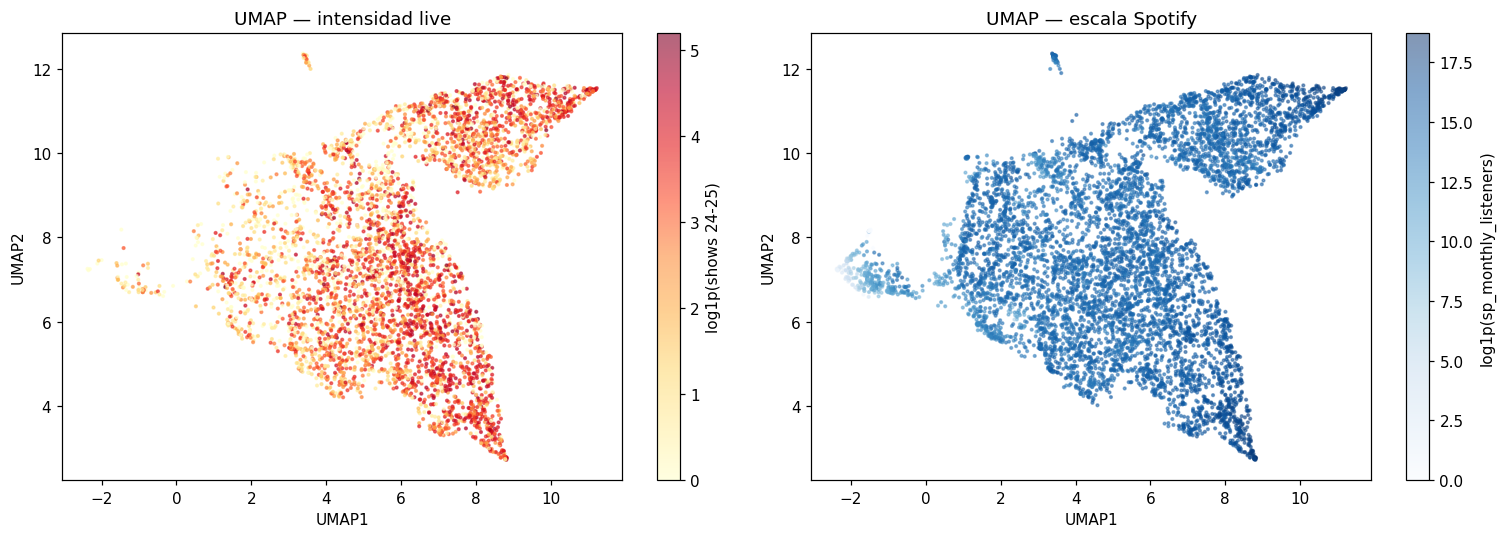

In [15]:
if not UMAP_OK:
    print('Instalar umap-learn y reiniciar kernel')
else:
    reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                        metric='euclidean', random_state=SEED, n_jobs=1)
    emb = reducer.fit_transform(X_sc.values)
    df_umap = pd.DataFrame(emb, columns=['UMAP1', 'UMAP2'], index=df.index)
    print(f'Embedding: {df_umap.shape}')

    has_shows = df['n_shows_24_25'].notna()
    shows_log = np.log1p(df.loc[has_shows, 'n_shows_24_25'])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sc1 = axes[0].scatter(
        df_umap.loc[has_shows, 'UMAP1'], df_umap.loc[has_shows, 'UMAP2'],
        c=shows_log, cmap='YlOrRd', s=3, alpha=0.6)
    plt.colorbar(sc1, ax=axes[0], label='log1p(shows 24-25)')
    axes[0].set_title('UMAP — intensidad live')
    axes[0].set_xlabel('UMAP1'); axes[0].set_ylabel('UMAP2')

    sp_log = np.log1p(df['sp_monthly_listeners'].fillna(0))
    sc2 = axes[1].scatter(
        df_umap['UMAP1'], df_umap['UMAP2'],
        c=sp_log, cmap='Blues', s=3, alpha=0.5)
    plt.colorbar(sc2, ax=axes[1], label='log1p(sp_monthly_listeners)')
    axes[1].set_title('UMAP — escala Spotify')
    axes[1].set_xlabel('UMAP1'); axes[1].set_ylabel('UMAP2')

    plt.tight_layout()
    plt.show()

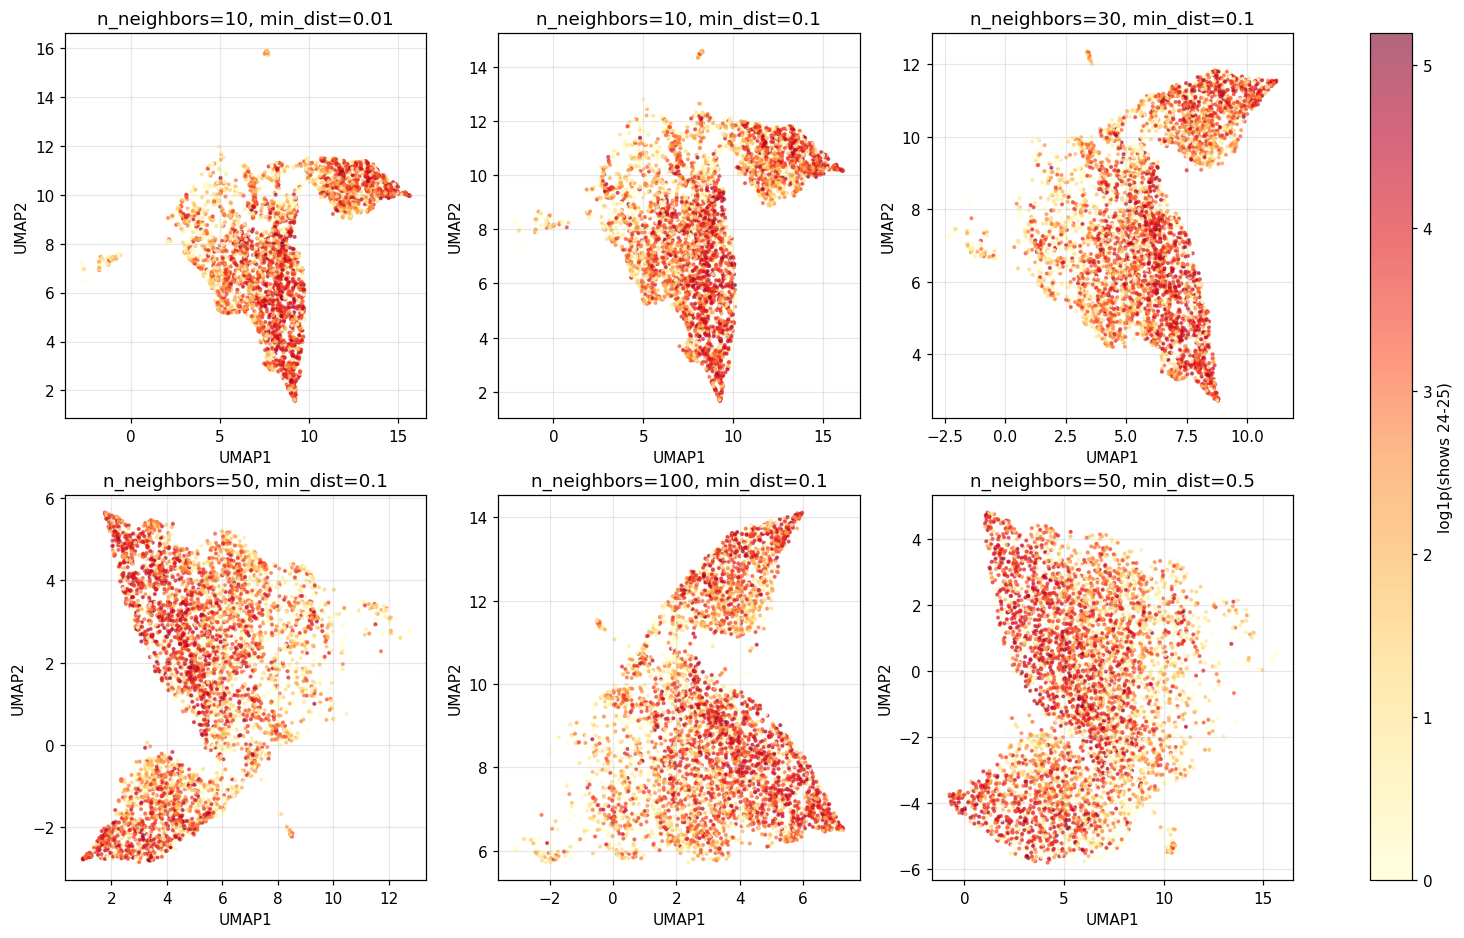

In [16]:
# ============================================================
# Sensibilidad de UMAP ante distintos parámetros
# ============================================================

umap_params = [
    {"n_neighbors": 10, "min_dist": 0.01},
    {"n_neighbors": 10, "min_dist": 0.1},
    {"n_neighbors": 30, "min_dist": 0.1},
    {"n_neighbors": 50, "min_dist": 0.1},
    {"n_neighbors": 100, "min_dist": 0.1},
    {"n_neighbors": 50, "min_dist": 0.5}
]

has_shows = df["n_shows_24_25"].notna()
shows_log = np.log1p(df.loc[has_shows, "n_shows_24_25"])

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, params in enumerate(umap_params):
    
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=params["n_neighbors"],
        min_dist=params["min_dist"],
        metric="euclidean",
        random_state=SEED,
        n_jobs=1
    )
    
    emb = reducer.fit_transform(X_sc.values)
    
    df_umap_tmp = pd.DataFrame(
        emb,
        columns=["UMAP1", "UMAP2"],
        index=df.index
    )
    
    sc = axes[i].scatter(
        df_umap_tmp.loc[has_shows, "UMAP1"],
        df_umap_tmp.loc[has_shows, "UMAP2"],
        c=shows_log,
        cmap="YlOrRd",
        s=3,
        alpha=0.6
    )
    
    axes[i].set_title(
        f"n_neighbors={params['n_neighbors']}, min_dist={params['min_dist']}"
    )
    axes[i].set_xlabel("UMAP1")
    axes[i].set_ylabel("UMAP2")
    axes[i].grid(alpha=0.3)

fig.colorbar(sc, ax=axes, label="log1p(shows 24-25)")
plt.show()

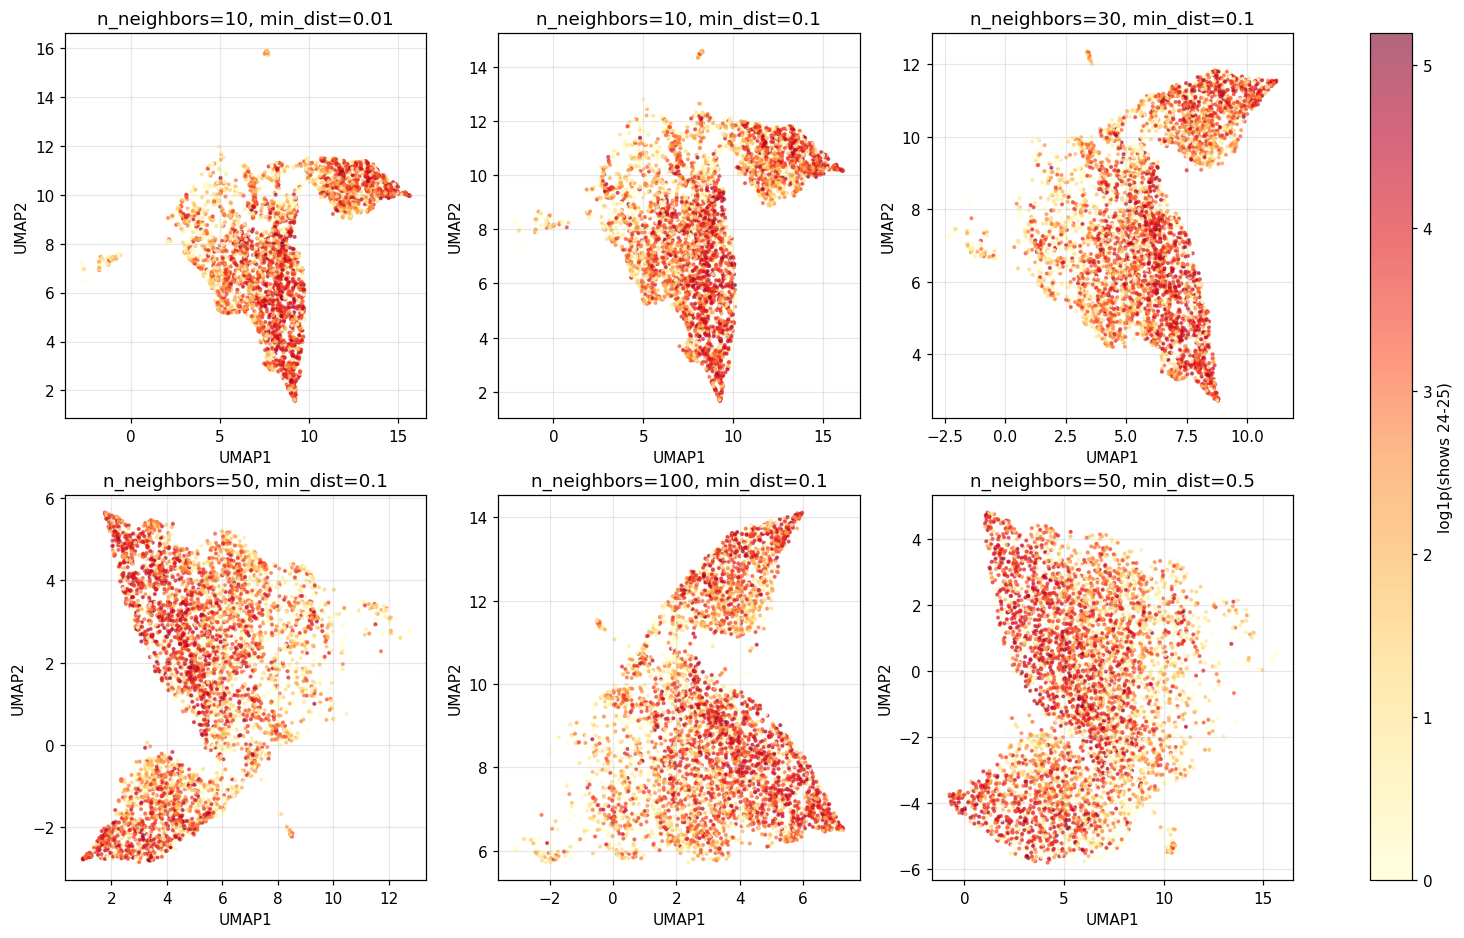

In [17]:
# ============================================================
# Sensibilidad de UMAP ante distintos parámetros
# ============================================================

umap_params = [
    {"n_neighbors": 10, "min_dist": 0.01},
    {"n_neighbors": 10, "min_dist": 0.1},
    {"n_neighbors": 30, "min_dist": 0.1},
    {"n_neighbors": 50, "min_dist": 0.1},
    {"n_neighbors": 100, "min_dist": 0.1},
    {"n_neighbors": 50, "min_dist": 0.5}
]

has_shows = df["n_shows_24_25"].notna()
shows_log = np.log1p(df.loc[has_shows, "n_shows_24_25"])

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, params in enumerate(umap_params):
    
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=params["n_neighbors"],
        min_dist=params["min_dist"],
        metric="euclidean",
        random_state=SEED,
        n_jobs=1
    )
    
    emb = reducer.fit_transform(X_sc.values)
    
    df_umap_tmp = pd.DataFrame(
        emb,
        columns=["UMAP1", "UMAP2"],
        index=df.index
    )
    
    sc = axes[i].scatter(
        df_umap_tmp.loc[has_shows, "UMAP1"],
        df_umap_tmp.loc[has_shows, "UMAP2"],
        c=shows_log,
        cmap="YlOrRd",
        s=3,
        alpha=0.6
    )
    
    axes[i].set_title(
        f"n_neighbors={params['n_neighbors']}, min_dist={params['min_dist']}"
    )
    axes[i].set_xlabel("UMAP1")
    axes[i].set_ylabel("UMAP2")
    axes[i].grid(alpha=0.3)

fig.colorbar(sc, ax=axes, label="log1p(shows 24-25)")
plt.show()

# T-SNE

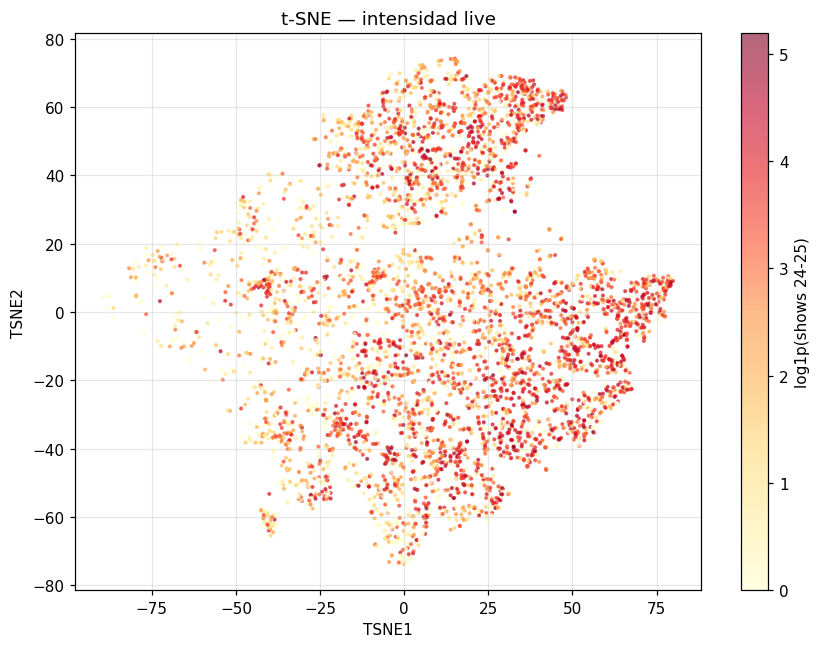

In [18]:
from sklearn.manifold import TSNE

# ============================================================
# t-SNE sobre matriz de features escaladas
# ============================================================

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=SEED
)

emb_tsne = tsne.fit_transform(X_sc.values)

df_tsne = pd.DataFrame(
    emb_tsne,
    columns=["TSNE1", "TSNE2"],
    index=df.index
)

has_shows = df["n_shows_24_25"].notna()
shows_log = np.log1p(df.loc[has_shows, "n_shows_24_25"])

plt.figure(figsize=(8, 6))

sc = plt.scatter(
    df_tsne.loc[has_shows, "TSNE1"],
    df_tsne.loc[has_shows, "TSNE2"],
    c=shows_log,
    cmap="YlOrRd",
    s=3,
    alpha=0.6
)

plt.colorbar(sc, label="log1p(shows 24-25)")
plt.title("t-SNE — intensidad live")
plt.xlabel("TSNE1")
plt.ylabel("TSNE2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


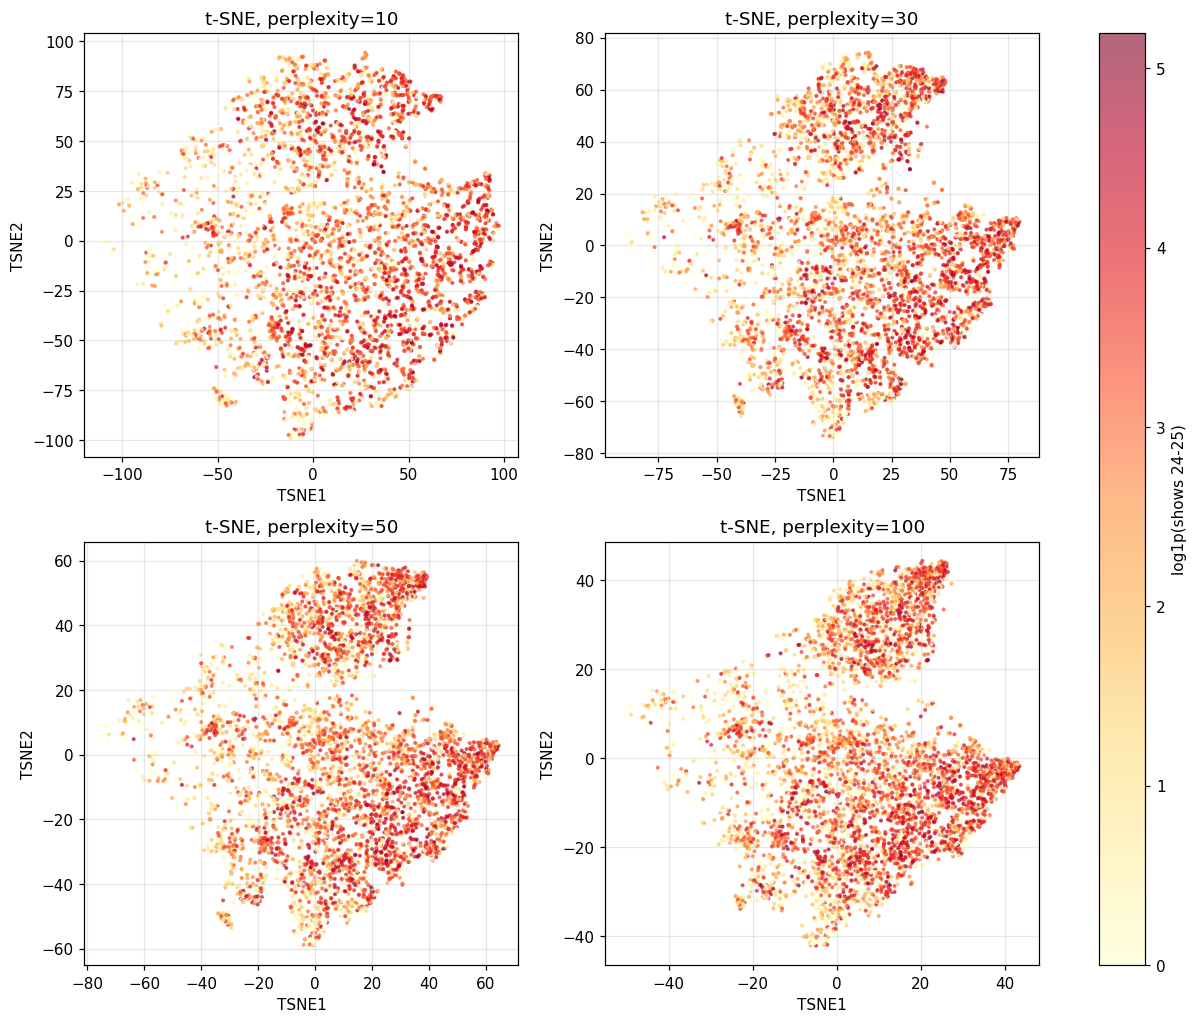

In [19]:
# ============================================================
# Sensibilidad de t-SNE ante distintos valores de perplexity
# ============================================================

perplexities = [10, 30, 50, 100]

has_shows = df["n_shows_24_25"].notna()
shows_log = np.log1p(df.loc[has_shows, "n_shows_24_25"])

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.ravel()

for i, perplexity_value in enumerate(perplexities):
    
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity_value,
        learning_rate="auto",
        init="pca",
        random_state=SEED
    )
    
    emb_tsne = tsne.fit_transform(X_sc.values)
    
    df_tsne_tmp = pd.DataFrame(
        emb_tsne,
        columns=["TSNE1", "TSNE2"],
        index=df.index
    )
    
    sc = axes[i].scatter(
        df_tsne_tmp.loc[has_shows, "TSNE1"],
        df_tsne_tmp.loc[has_shows, "TSNE2"],
        c=shows_log,
        cmap="YlOrRd",
        s=3,
        alpha=0.6
    )
    
    axes[i].set_title(f"t-SNE, perplexity={perplexity_value}")
    axes[i].set_xlabel("TSNE1")
    axes[i].set_ylabel("TSNE2")
    axes[i].grid(alpha=0.3)

fig.colorbar(sc, ax=axes, label="log1p(shows 24-25)")
plt.show()

# K-Medoids (PAM)

Más robusto que K-Means frente a outliers: usa puntos reales como centros de cluster.  
Implementación propia con distancia euclidiana y k-means++ initialization.  
La matriz de distancias (7 000 × 7 000) se precalcula una sola vez y se reutiliza para todos los valores de k.

In [20]:
def kmedoids_fit(D, k, n_init=5, max_iter=100, random_state=42):
    # K-Medoids sobre matriz de distancias D precalculada (float32)
    rng = np.random.RandomState(random_state)
    n = D.shape[0]
    best_inertia = np.inf
    best_labels, best_medoids = None, None

    for _ in range(n_init):
        # k-means++ init
        medoids = [int(rng.randint(0, n))]
        for __ in range(k - 1):
            d_min = D[:, medoids].min(axis=1).astype(np.float64)
            probs = d_min ** 2
            probs /= probs.sum()
            medoids.append(int(rng.choice(n, p=probs)))

        for ___ in range(max_iter):
            labels = np.argmin(D[:, medoids], axis=1)
            new_medoids = []
            for c in range(k):
                idxs = np.where(labels == c)[0]
                if len(idxs) == 0:
                    new_medoids.append(medoids[c])
                    continue
                sub_sum = D[np.ix_(idxs, idxs)].sum(axis=1)
                new_medoids.append(int(idxs[sub_sum.argmin()]))
            if sorted(new_medoids) == sorted(medoids):
                break
            medoids = new_medoids

        labels = np.argmin(D[:, medoids], axis=1)
        inertia = float(D[np.arange(n), [medoids[l] for l in labels]].sum())
        if inertia < best_inertia:
            best_inertia = inertia
            best_labels  = labels.copy()
            best_medoids = medoids[:]

    return best_labels, best_medoids

print('kmedoids_fit() definida')

kmedoids_fit() definida


In [21]:
# Precomputar matriz de distancias una sola vez (float32 ~ 196 MB)
print('Calculando matriz 7000×7000 (puede tardar ~15 s)...')
D = cdist(X_sc.values, X_sc.values, metric='euclidean').astype(np.float32)
print(f'D shape: {D.shape}  |  memoria: {D.nbytes/1e6:.0f} MB')

Calculando matriz 7000×7000 (puede tardar ~15 s)...


D shape: (7000, 7000)  |  memoria: 196 MB


In [22]:
km_res = {}
for k in [2, 3, 4, 5]:
    print(f'K-Medoids k={k}...')
    labels, medoids = kmedoids_fit(D, k, n_init=5, max_iter=100)
    sil = silhouette_score(X_sc.values, labels)
    db  = davies_bouldin_score(X_sc.values, labels)
    ch  = calinski_harabasz_score(X_sc.values, labels)
    sizes = dict(zip(*np.unique(labels, return_counts=True)))
    print(f'  sil={sil:.4f}  DB={db:.4f}  CH={ch:.0f}  sizes={sizes}')
    km_res[k] = dict(labels=labels, medoids=medoids,
                     sil=sil, db=db, ch=ch, sizes=sizes)

K-Medoids k=2...


  sil=0.1406  DB=2.3495  CH=871  sizes={np.int64(0): np.int64(4707), np.int64(1): np.int64(2293)}
K-Medoids k=3...


  sil=0.1647  DB=1.4587  CH=1757  sizes={np.int64(0): np.int64(4689), np.int64(1): np.int64(399), np.int64(2): np.int64(1912)}
K-Medoids k=4...


  sil=0.1342  DB=1.9586  CH=1459  sizes={np.int64(0): np.int64(379), np.int64(1): np.int64(2078), np.int64(2): np.int64(2796), np.int64(3): np.int64(1747)}
K-Medoids k=5...


  sil=0.1208  DB=1.7933  CH=1170  sizes={np.int64(0): np.int64(2100), np.int64(1): np.int64(1413), np.int64(2): np.int64(1374), np.int64(3): np.int64(1589), np.int64(4): np.int64(524)}


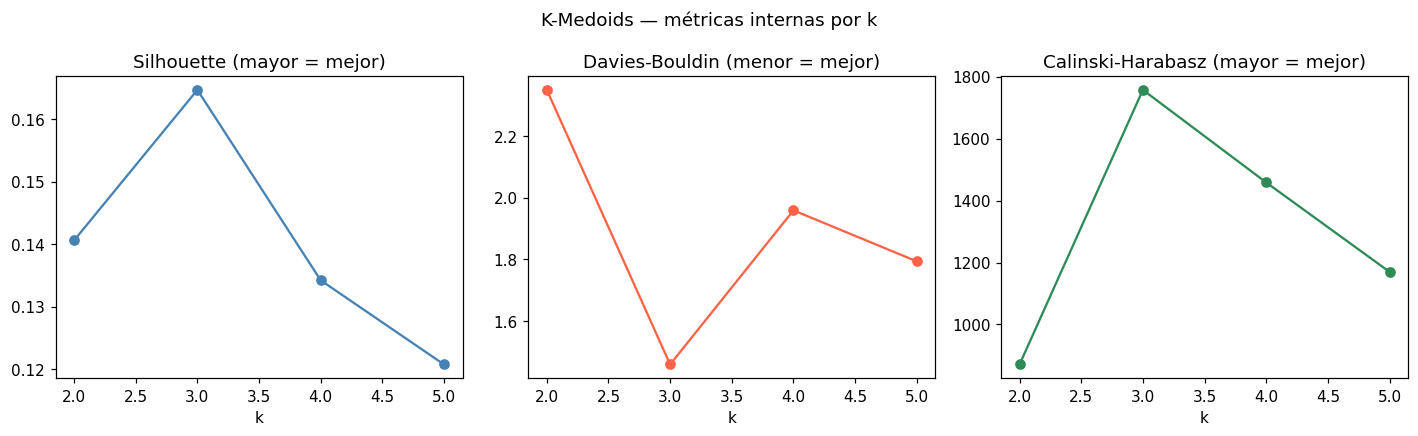

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
ks = list(km_res.keys())

axes[0].plot(ks, [km_res[k]['sil'] for k in ks], 'o-', color='steelblue')
axes[0].set_title('Silhouette (mayor = mejor)'); axes[0].set_xlabel('k')

axes[1].plot(ks, [km_res[k]['db'] for k in ks], 'o-', color='tomato')
axes[1].set_title('Davies-Bouldin (menor = mejor)'); axes[1].set_xlabel('k')

axes[2].plot(ks, [km_res[k]['ch'] for k in ks], 'o-', color='seagreen')
axes[2].set_title('Calinski-Harabasz (mayor = mejor)'); axes[2].set_xlabel('k')

plt.suptitle('K-Medoids — métricas internas por k', fontsize=12)
plt.tight_layout(); plt.show()

### alternativa

In [24]:
# ============================================================
# K-Medoids con guardado de costo total
# ============================================================

def kmedoids_fit(D, k, n_init=30, max_iter=100, random_state=42):
    
    rng = np.random.RandomState(random_state)
    n = D.shape[0]
    
    best_cost = np.inf
    best_labels = None
    best_medoids = None

    for _ in range(n_init):
        
        medoids = [int(rng.randint(0, n))]
        
        for __ in range(k - 1):
            d_min = D[:, medoids].min(axis=1).astype(np.float64)
            probs = d_min ** 2
            
            if probs.sum() == 0:
                candidate = int(rng.choice(np.setdiff1d(np.arange(n), medoids)))
            else:
                probs = probs / probs.sum()
                candidate = int(rng.choice(n, p=probs))
            
            medoids.append(candidate)

        for ___ in range(max_iter):
            
            labels = np.argmin(D[:, medoids], axis=1)
            new_medoids = []
            
            for c in range(k):
                idxs = np.where(labels == c)[0]
                
                if len(idxs) == 0:
                    new_medoids.append(medoids[c])
                    continue
                
                sub_sum = D[np.ix_(idxs, idxs)].sum(axis=1)
                new_medoids.append(int(idxs[sub_sum.argmin()]))
            
            if set(new_medoids) == set(medoids):
                break
            
            medoids = new_medoids

        labels = np.argmin(D[:, medoids], axis=1)
        cost = float(D[np.arange(n), [medoids[l] for l in labels]].sum())
        
        if cost < best_cost:
            best_cost = cost
            best_labels = labels.copy()
            best_medoids = medoids[:]

    return best_labels, best_medoids, best_cost

In [25]:
# ============================================================
# Evaluación de K-Medoids para varios valores de k
# ============================================================

km_res = {}

for k in range(2, 11):
    
    print(f"K-Medoids k={k}...")
    
    labels, medoids, cost = kmedoids_fit(
        D,
        k,
        n_init=30,
        max_iter=100,
        random_state=SEED
    )
    
    sil = silhouette_score(D, labels, metric="precomputed")
    db = davies_bouldin_score(X_sc.values, labels)
    ch = calinski_harabasz_score(X_sc.values, labels)
    sizes = dict(zip(*np.unique(labels, return_counts=True)))
    
    print(
        f"  cost={cost:.0f}  sil={sil:.4f}  "
        f"DB={db:.4f}  CH={ch:.0f}  sizes={sizes}"
    )
    
    km_res[k] = {
        "labels": labels,
        "medoids": medoids,
        "cost": cost,
        "sil": sil,
        "db": db,
        "ch": ch,
        "sizes": sizes
    }

K-Medoids k=2...


  cost=18719  sil=0.2046  DB=1.8624  CH=1657  sizes={np.int64(0): np.int64(4127), np.int64(1): np.int64(2873)}
K-Medoids k=3...


  cost=17577  sil=0.1647  DB=1.4587  CH=1757  sizes={np.int64(0): np.int64(4689), np.int64(1): np.int64(399), np.int64(2): np.int64(1912)}
K-Medoids k=4...


  cost=16580  sil=0.1472  DB=1.7846  CH=1533  sizes={np.int64(0): np.int64(2045), np.int64(1): np.int64(2725), np.int64(2): np.int64(1883), np.int64(3): np.int64(347)}
K-Medoids k=5...


  cost=15951  sil=0.0985  DB=1.7194  CH=1360  sizes={np.int64(0): np.int64(1333), np.int64(1): np.int64(1609), np.int64(2): np.int64(2190), np.int64(3): np.int64(353), np.int64(4): np.int64(1515)}
K-Medoids k=6...


  cost=15458  sil=0.1258  DB=1.6811  CH=1233  sizes={np.int64(0): np.int64(1880), np.int64(1): np.int64(1096), np.int64(2): np.int64(1206), np.int64(3): np.int64(1479), np.int64(4): np.int64(335), np.int64(5): np.int64(1004)}
K-Medoids k=7...


  cost=15147  sil=0.1294  DB=1.5910  CH=1208  sizes={np.int64(0): np.int64(1457), np.int64(1): np.int64(1151), np.int64(2): np.int64(338), np.int64(3): np.int64(1717), np.int64(4): np.int64(1260), np.int64(5): np.int64(239), np.int64(6): np.int64(838)}
K-Medoids k=8...


  cost=14686  sil=0.1313  DB=1.7491  CH=1088  sizes={np.int64(0): np.int64(981), np.int64(1): np.int64(326), np.int64(2): np.int64(944), np.int64(3): np.int64(760), np.int64(4): np.int64(1631), np.int64(5): np.int64(1121), np.int64(6): np.int64(892), np.int64(7): np.int64(345)}
K-Medoids k=9...


  cost=14478  sil=0.1257  DB=1.8111  CH=1026  sizes={np.int64(0): np.int64(945), np.int64(1): np.int64(1015), np.int64(2): np.int64(1103), np.int64(3): np.int64(197), np.int64(4): np.int64(654), np.int64(5): np.int64(1552), np.int64(6): np.int64(133), np.int64(7): np.int64(790), np.int64(8): np.int64(611)}
K-Medoids k=10...


  cost=14241  sil=0.1250  DB=1.6499  CH=1005  sizes={np.int64(0): np.int64(707), np.int64(1): np.int64(200), np.int64(2): np.int64(932), np.int64(3): np.int64(207), np.int64(4): np.int64(1022), np.int64(5): np.int64(723), np.int64(6): np.int64(840), np.int64(7): np.int64(740), np.int64(8): np.int64(1530), np.int64(9): np.int64(99)}


In [26]:
from sklearn.metrics import silhouette_samples

# ============================================================
# Silhouette promedio por cluster
# ============================================================

k_elegido = 7
labels_k = km_res[k_elegido]["labels"]

sil_samples = silhouette_samples(D, labels_k, metric="precomputed")

tabla_sil_cluster = (
    pd.DataFrame({
        "cluster": labels_k,
        "silhouette": sil_samples
    })
    .groupby("cluster")
    .agg(
        n_artistas=("cluster", "size"),
        silhouette_media=("silhouette", "mean"),
        silhouette_mediana=("silhouette", "median"),
        silhouette_min=("silhouette", "min"),
        pct_sil_negativa=("silhouette", lambda x: (x < 0).mean() * 100)
    )
    .sort_index()
)

tabla_sil_cluster.round(3)

,n_artistas,silhouette_media,silhouette_mediana,silhouette_min,pct_sil_negativa
cluster,,,,,
0,1457,0.063,0.074,-0.256,32.739
1,1151,-0.028,-0.022,-0.320,55.343
2,338,0.163,0.216,-0.305,23.373
3,1717,0.236,0.245,-0.056,1.398
4,1260,0.109,0.118,-0.162,20.317
5,239,0.118,0.110,-0.190,22.594
6,838,0.265,0.276,-0.080,1.432


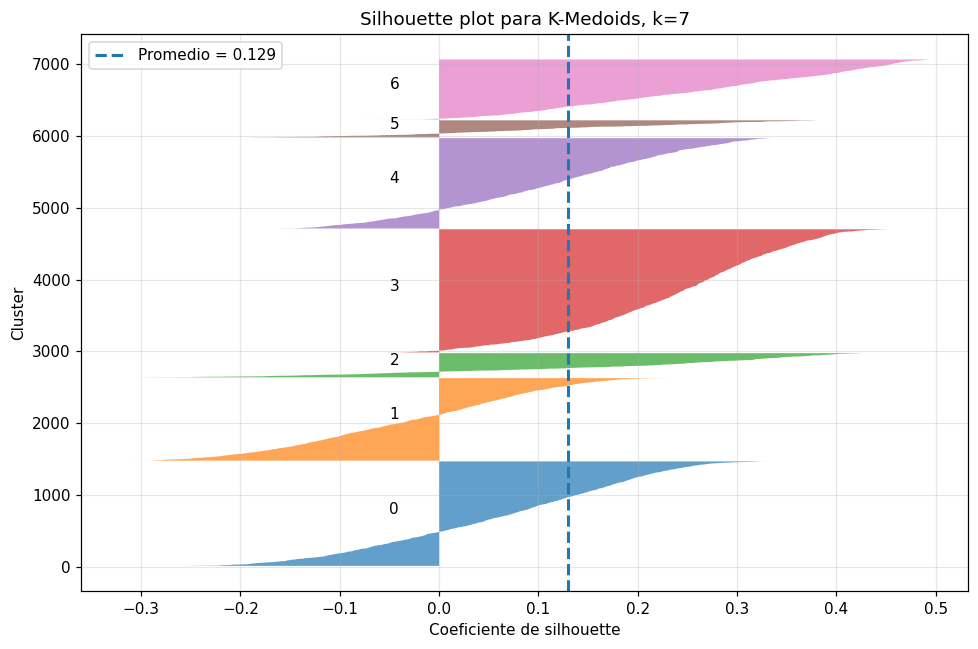

In [27]:
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Silhouette plot para una solución de K-Medoids
# ============================================================

k_elegido = 7
labels_k = km_res[k_elegido]["labels"]

sil_avg = silhouette_score(D, labels_k, metric="precomputed")
sil_values = silhouette_samples(D, labels_k, metric="precomputed")

fig, ax = plt.subplots(figsize=(9, 6))

y_lower = 10

for cluster_id in sorted(np.unique(labels_k)):
    
    cluster_sil_values = sil_values[labels_k == cluster_id]
    cluster_sil_values.sort()
    
    cluster_size = cluster_sil_values.shape[0]
    y_upper = y_lower + cluster_size
    
    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_sil_values,
        alpha=0.7
    )
    
    ax.text(
        -0.05,
        y_lower + 0.5 * cluster_size,
        str(cluster_id)
    )
    
    y_lower = y_upper + 10

ax.axvline(
    x=sil_avg,
    linestyle="--",
    linewidth=2,
    label=f"Promedio = {sil_avg:.3f}"
)

ax.set_title(f"Silhouette plot para K-Medoids, k={k_elegido}")
ax.set_xlabel("Coeficiente de silhouette")
ax.set_ylabel("Cluster")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
from sklearn.metrics import adjusted_rand_score

# ============================================================
# Estabilidad de K-Medoids ante distintas semillas
# ============================================================

k_elegido = 3
seeds = [1, 7, 13, 21, 42, 99, 123, 2026]

labels_por_seed = {}

for seed in seeds:
    
    labels_tmp, medoids_tmp, cost_tmp = kmedoids_fit(
        D,
        k_elegido,
        n_init=10,
        max_iter=100,
        random_state=seed
    )
    
    labels_por_seed[seed] = labels_tmp

ari_rows = []

for i, seed_i in enumerate(seeds):
    for seed_j in seeds[i + 1:]:
        
        ari = adjusted_rand_score(
            labels_por_seed[seed_i],
            labels_por_seed[seed_j]
        )
        
        ari_rows.append({
            "seed_i": seed_i,
            "seed_j": seed_j,
            "ARI": ari
        })

tabla_estabilidad = pd.DataFrame(ari_rows)

tabla_estabilidad["ARI"].describe().round(3)

count    28.000
mean      0.609
std       0.223
min       0.353
25%       0.387
50%       0.629
75%       0.811
max       1.000
Name: ARI, dtype: float64

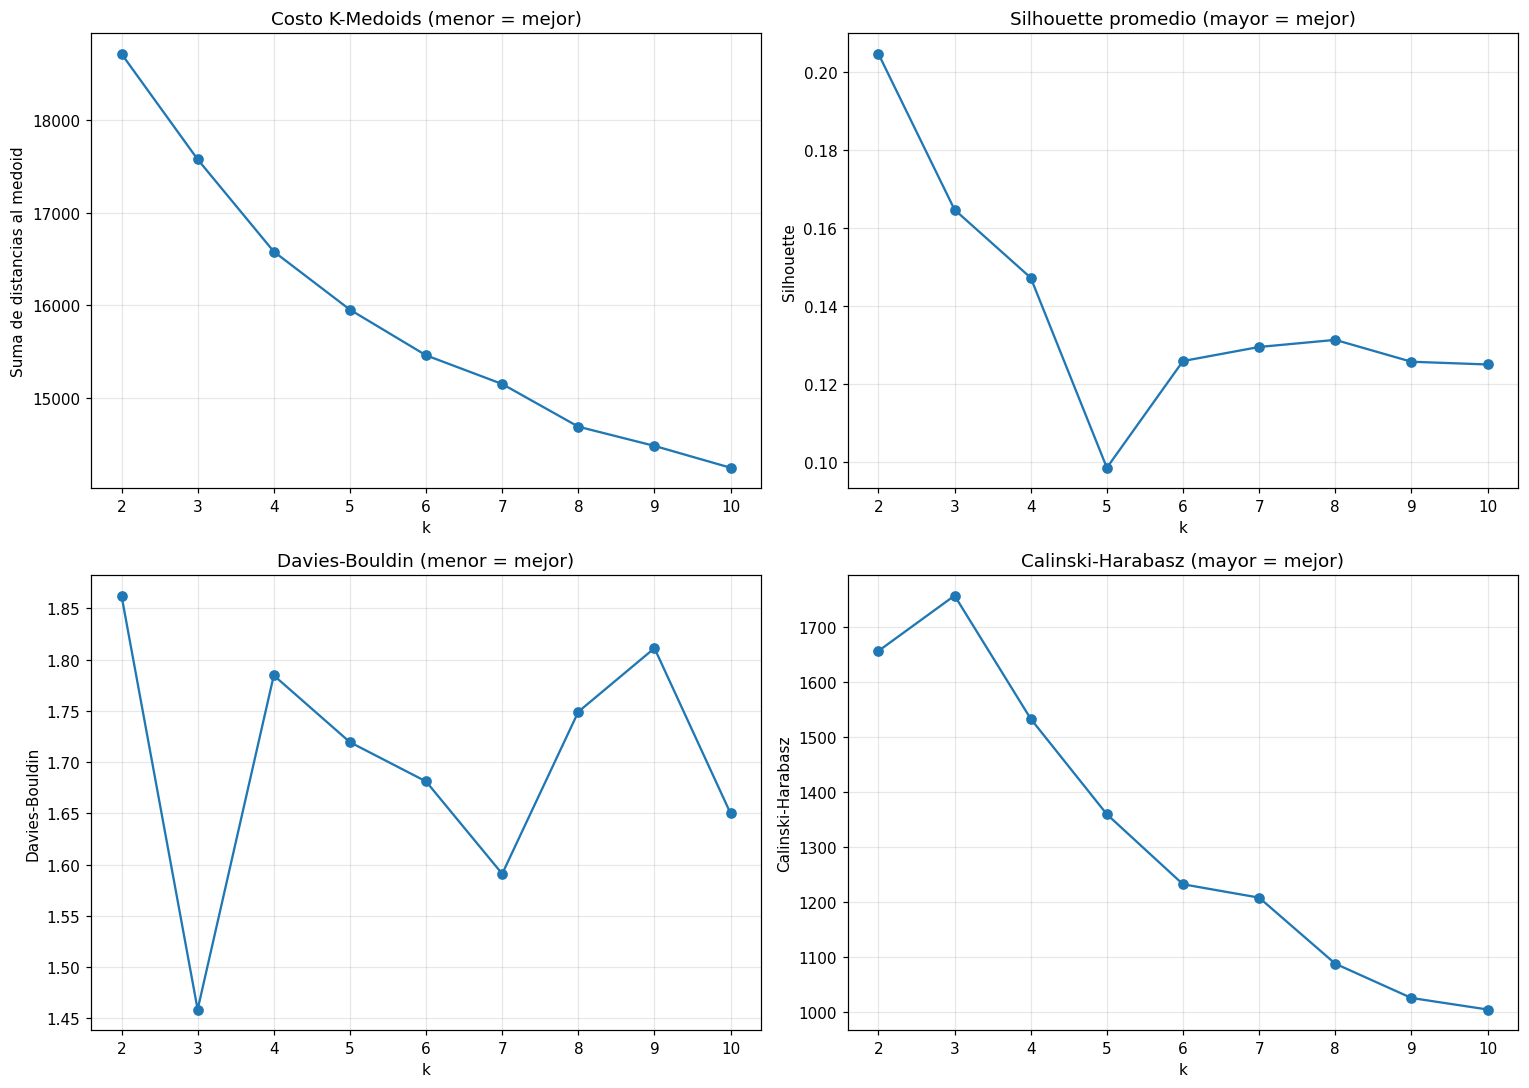

,k,cost,silhouette,davies_bouldin,calinski_harabasz,min_cluster_size,max_cluster_size
0,2,18718.621,0.205,1.862,1656.846,2873,4127
1,3,17576.994,0.165,1.459,1757.464,399,4689
2,4,16579.680,0.147,1.785,1533.455,347,2725
3,5,15951.356,0.098,1.719,1359.903,353,2190
4,6,15457.535,0.126,1.681,1232.658,335,1880
5,7,15147.062,0.129,1.591,1208.320,239,1717
6,8,14685.506,0.131,1.749,1088.238,326,1631
7,9,14477.520,0.126,1.811,1025.926,133,1552
8,10,14241.186,0.125,1.650,1004.975,99,1530


In [29]:
# ============================================================
# Tabla y gráficos de métricas internas por k
# ============================================================

tabla_kmedoids_metricas = pd.DataFrame([
    {
        "k": k,
        "cost": res["cost"],
        "silhouette": res["sil"],
        "davies_bouldin": res["db"],
        "calinski_harabasz": res["ch"],
        "min_cluster_size": min(res["sizes"].values()),
        "max_cluster_size": max(res["sizes"].values())
    }
    for k, res in km_res.items()
]).sort_values("k")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(tabla_kmedoids_metricas["k"], tabla_kmedoids_metricas["cost"], marker="o")
axes[0, 0].set_title("Costo K-Medoids (menor = mejor)")
axes[0, 0].set_xlabel("k")
axes[0, 0].set_ylabel("Suma de distancias al medoid")
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(tabla_kmedoids_metricas["k"], tabla_kmedoids_metricas["silhouette"], marker="o")
axes[0, 1].set_title("Silhouette promedio (mayor = mejor)")
axes[0, 1].set_xlabel("k")
axes[0, 1].set_ylabel("Silhouette")
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(tabla_kmedoids_metricas["k"], tabla_kmedoids_metricas["davies_bouldin"], marker="o")
axes[1, 0].set_title("Davies-Bouldin (menor = mejor)")
axes[1, 0].set_xlabel("k")
axes[1, 0].set_ylabel("Davies-Bouldin")
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(tabla_kmedoids_metricas["k"], tabla_kmedoids_metricas["calinski_harabasz"], marker="o")
axes[1, 1].set_title("Calinski-Harabasz (mayor = mejor)")
axes[1, 1].set_xlabel("k")
axes[1, 1].set_ylabel("Calinski-Harabasz")
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

tabla_kmedoids_metricas.round(3)

In [30]:
from sklearn.metrics import silhouette_samples, silhouette_score

# ============================================================
# Silhouette por cluster para soluciones seleccionadas
# ============================================================

for k_elegido in [2, 3]:
    
    labels_k = km_res[k_elegido]["labels"]
    
    sil_samples = silhouette_samples(D, labels_k, metric="precomputed")
    sil_avg = silhouette_score(D, labels_k, metric="precomputed")
    
    tabla_sil_cluster = (
        pd.DataFrame({
            "cluster": labels_k,
            "silhouette": sil_samples
        })
        .groupby("cluster")
        .agg(
            n_artistas=("cluster", "size"),
            silhouette_media=("silhouette", "mean"),
            silhouette_mediana=("silhouette", "median"),
            silhouette_min=("silhouette", "min"),
            pct_sil_negativa=("silhouette", lambda x: (x < 0).mean() * 100)
        )
        .sort_index()
    )
    
    print(f"\nK-Medoids k={k_elegido}")
    print(f"Silhouette promedio: {sil_avg:.3f}")
    display(tabla_sil_cluster.round(3))


K-Medoids k=2
Silhouette promedio: 0.205


,n_artistas,silhouette_media,silhouette_mediana,silhouette_min,pct_sil_negativa
cluster,,,,,
0,4127,0.356,0.369,-0.030,0.048
1,2873,-0.013,-0.013,-0.286,52.767



K-Medoids k=3
Silhouette promedio: 0.165


,n_artistas,silhouette_media,silhouette_mediana,silhouette_min,pct_sil_negativa
cluster,,,,,
0,4689,0.088,0.108,-0.223,25.912
1,399,0.196,0.234,-0.198,16.541
2,1912,0.346,0.357,0.090,0.000


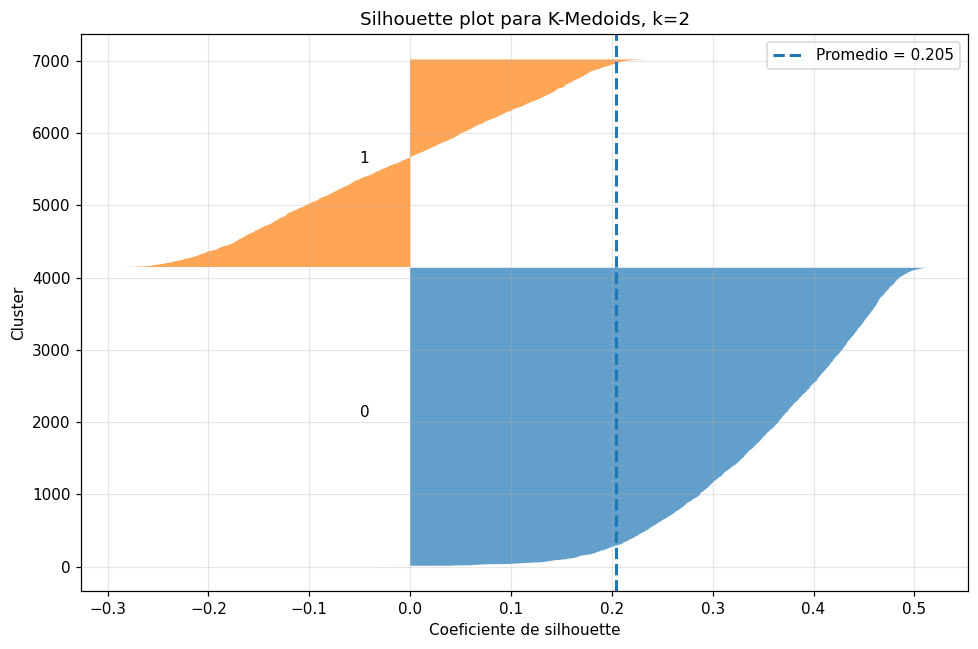

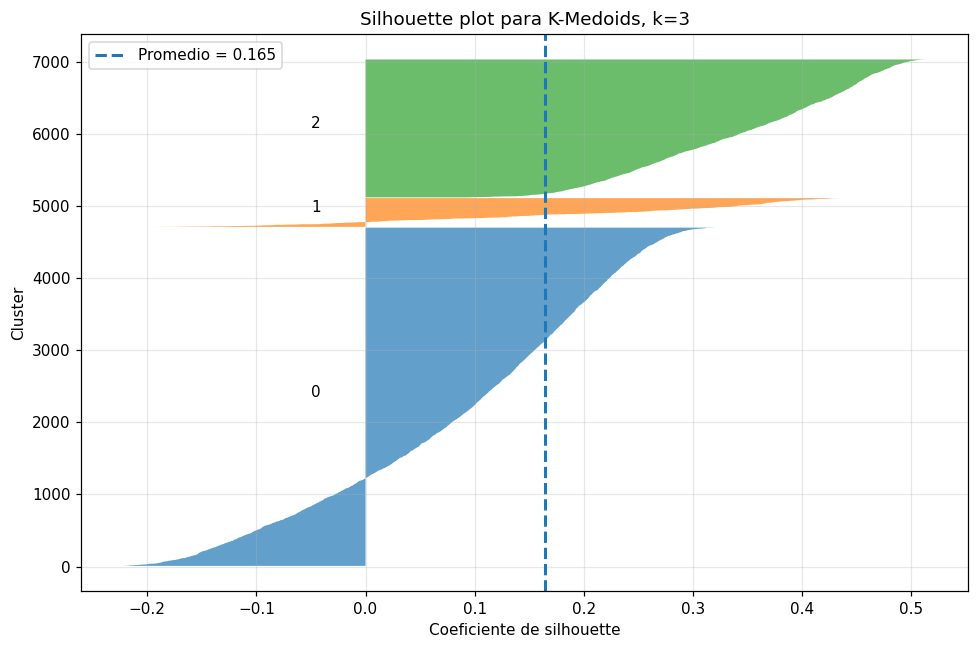

In [31]:
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Silhouette plot para K-Medoids
# ============================================================

def plot_silhouette_kmedoids(D, labels, k_elegido):
    
    sil_avg = silhouette_score(D, labels, metric="precomputed")
    sil_values = silhouette_samples(D, labels, metric="precomputed")
    
    fig, ax = plt.subplots(figsize=(9, 6))
    
    y_lower = 10
    
    for cluster_id in sorted(np.unique(labels)):
        
        cluster_sil_values = sil_values[labels == cluster_id]
        cluster_sil_values.sort()
        
        cluster_size = cluster_sil_values.shape[0]
        y_upper = y_lower + cluster_size
        
        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_sil_values,
            alpha=0.7
        )
        
        ax.text(
            -0.05,
            y_lower + 0.5 * cluster_size,
            str(cluster_id)
        )
        
        y_lower = y_upper + 10
    
    ax.axvline(
        x=sil_avg,
        linestyle="--",
        linewidth=2,
        label=f"Promedio = {sil_avg:.3f}"
    )
    
    ax.set_title(f"Silhouette plot para K-Medoids, k={k_elegido}")
    ax.set_xlabel("Coeficiente de silhouette")
    ax.set_ylabel("Cluster")
    ax.legend()
    ax.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()


plot_silhouette_kmedoids(D, km_res[2]["labels"], 2)
plot_silhouette_kmedoids(D, km_res[3]["labels"], 3)

# Gaussian Mixture Models (GMM)

Permite clusters de forma elipsoidal y asignaciones probabilísticas.  
Se evalúan dos estructuras de covarianza (`full` y `tied`) y se selecciona k por BIC.

In [32]:
gmm_res = {}
for cov in ['full', 'tied']:
    gmm_res[cov] = {}
    for k in [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]:
        gm = GaussianMixture(n_components=k, covariance_type=cov,
                             n_init=5, max_iter=300, random_state=SEED)
        gm.fit(X_sc.values)
        labels = gm.predict(X_sc.values)
        bic = gm.bic(X_sc.values)
        aic = gm.aic(X_sc.values)
        sil = silhouette_score(X_sc.values, labels)
        db  = davies_bouldin_score(X_sc.values, labels)
        ch  = calinski_harabasz_score(X_sc.values, labels)
        sizes = dict(zip(*np.unique(labels, return_counts=True)))
        print(f'GMM [{cov}] k={k}: BIC={bic:.0f}  AIC={aic:.0f}  '
              f'sil={sil:.4f}  DB={db:.4f}  sizes={sizes}')
        gmm_res[cov][k] = dict(labels=labels, model=gm,
                               bic=bic, aic=aic,
                               sil=sil, db=db, ch=ch, sizes=sizes)

GMM [full] k=2: BIC=-25705  AIC=-26767  sil=0.2782  DB=2.0139  sizes={np.int64(0): np.int64(5112), np.int64(1): np.int64(1888)}


GMM [full] k=3: BIC=-31615  AIC=-33212  sil=0.1227  DB=2.2463  sizes={np.int64(0): np.int64(3561), np.int64(1): np.int64(724), np.int64(2): np.int64(2715)}


GMM [full] k=4: BIC=-33152  AIC=-35284  sil=0.1259  DB=2.0236  sizes={np.int64(0): np.int64(2152), np.int64(1): np.int64(3408), np.int64(2): np.int64(825), np.int64(3): np.int64(615)}


GMM [full] k=5: BIC=-43489  AIC=-46155  sil=0.0375  DB=2.7168  sizes={np.int64(0): np.int64(2557), np.int64(1): np.int64(1003), np.int64(2): np.int64(429), np.int64(3): np.int64(1113), np.int64(4): np.int64(1898)}


GMM [full] k=6: BIC=-44977  AIC=-48178  sil=0.0501  DB=2.3740  sizes={np.int64(0): np.int64(925), np.int64(1): np.int64(1007), np.int64(2): np.int64(2409), np.int64(3): np.int64(1115), np.int64(4): np.int64(1016), np.int64(5): np.int64(528)}


...

GMM [tied] k=7: BIC=-19633  AIC=-20654  sil=0.1146  DB=1.5433  sizes={np.int64(0): np.int64(701), np.int64(1): np.int64(271), np.int64(2): np.int64(319), np.int64(3): np.int64(1653), np.int64(4): np.int64(3803), np.int64(5): np.int64(90), np.int64(6): np.int64(163)}


GMM [tied] k=8: BIC=-21492  AIC=-22596  sil=0.1156  DB=1.5678  sizes={np.int64(0): np.int64(284), np.int64(1): np.int64(3786), np.int64(2): np.int64(696), np.int64(3): np.int64(82), np.int64(4): np.int64(182), np.int64(5): np.int64(91), np.int64(6): np.int64(1645), np.int64(7): np.int64(234)}


GMM [tied] k=9: BIC=-22199  AIC=-23384  sil=0.1140  DB=1.6457  sizes={np.int64(0): np.int64(267), np.int64(1): np.int64(3694), np.int64(2): np.int64(83), np.int64(3): np.int64(234), np.int64(4): np.int64(1596), np.int64(5): np.int64(510), np.int64(6): np.int64(446), np.int64(7): np.int64(90), np.int64(8): np.int64(80)}


GMM [tied] k=10: BIC=-23609  AIC=-24877  sil=0.1160  DB=1.5074  sizes={np.int64(0): np.int64(63), np.int64(1): np.int64(666), np.int64(2): np.int64(1579), np.int64(3): np.int64(224), np.int64(4): np.int64(31), np.int64(5): np.int64(30), np.int64(6): np.int64(91), np.int64(7): np.int64(223), np.int64(8): np.int64(317), np.int64(9): np.int64(3776)}


GMM [tied] k=11: BIC=-23537  AIC=-24887  sil=0.0891  DB=1.5354  sizes={np.int64(0): np.int64(3157), np.int64(1): np.int64(215), np.int64(2): np.int64(695), np.int64(3): np.int64(633), np.int64(4): np.int64(31), np.int64(5): np.int64(76), np.int64(6): np.int64(1655), np.int64(7): np.int64(255), np.int64(8): np.int64(27), np.int64(9): np.int64(90), np.int64(10): np.int64(166)}


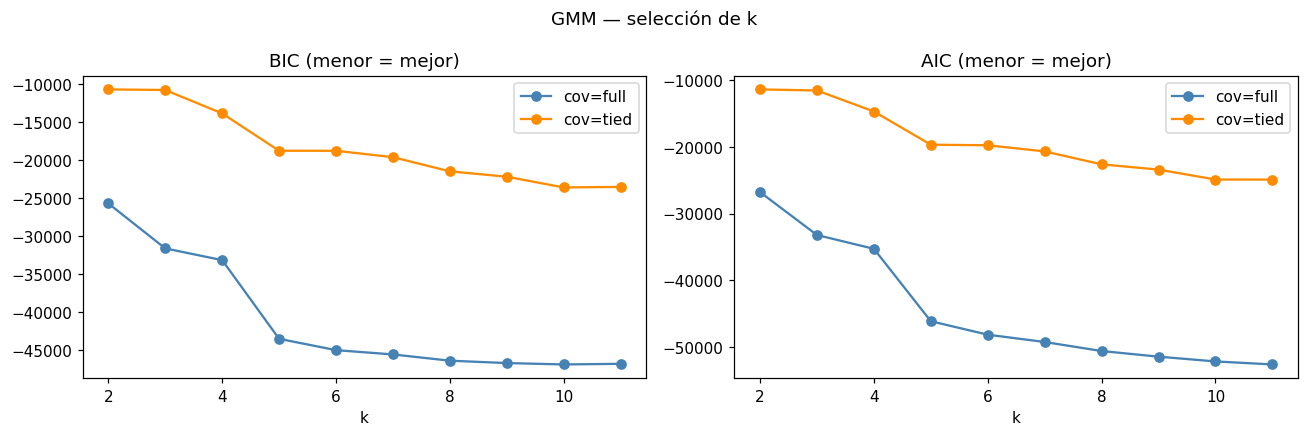

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
col_map = {'full': 'steelblue', 'tied': 'darkorange'}
ks = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

for cov in ['full', 'tied']:
    bics = [gmm_res[cov][k]['bic'] for k in ks]
    aics = [gmm_res[cov][k]['aic'] for k in ks]
    axes[0].plot(ks, bics, 'o-', color=col_map[cov], label=f'cov={cov}')
    axes[1].plot(ks, aics, 'o-', color=col_map[cov], label=f'cov={cov}')

for ax, title in zip(axes, ['BIC (menor = mejor)', 'AIC (menor = mejor)']):
    ax.set_title(title); ax.set_xlabel('k'); ax.legend()

plt.suptitle('GMM — selección de k', fontsize=12)
plt.tight_layout(); plt.show()

In [34]:
from sklearn.metrics import silhouette_samples, silhouette_score

# ============================================================
# Silhouette por cluster para GMM
# ============================================================

cov_elegida = "full"
k_elegido = 2

labels_gmm = gmm_res[cov_elegida][k_elegido]["labels"]

sil_samples = silhouette_samples(X_sc.values, labels_gmm)
sil_avg = silhouette_score(X_sc.values, labels_gmm)

tabla_sil_gmm = (
    pd.DataFrame({
        "cluster": labels_gmm,
        "silhouette": sil_samples
    })
    .groupby("cluster")
    .agg(
        n_artistas=("cluster", "size"),
        silhouette_media=("silhouette", "mean"),
        silhouette_mediana=("silhouette", "median"),
        silhouette_min=("silhouette", "min"),
        pct_sil_negativa=("silhouette", lambda x: (x < 0).mean() * 100)
    )
    .sort_index()
)

print(f"GMM {cov_elegida}, k={k_elegido}")
print(f"Silhouette promedio: {sil_avg:.3f}")
display(tabla_sil_gmm.round(3))

GMM full, k=2
Silhouette promedio: 0.278


,n_artistas,silhouette_media,silhouette_mediana,silhouette_min,pct_sil_negativa
cluster,,,,,
0,5112,0.408,0.429,-0.068,0.020
1,1888,-0.074,-0.078,-0.458,66.102


In [35]:
# ============================================================
# Incertidumbre de asignación en GMM
# ============================================================

gm = gmm_res["full"][2]["model"]

probs = gm.predict_proba(X_sc.values)
max_prob = probs.max(axis=1)

tabla_confianza_gmm = pd.DataFrame({
    "cluster": labels_gmm,
    "prob_maxima": max_prob
})

resumen_confianza_gmm = (
    tabla_confianza_gmm
    .groupby("cluster")
    .agg(
        n_artistas=("cluster", "size"),
        prob_media=("prob_maxima", "mean"),
        prob_mediana=("prob_maxima", "median"),
        pct_prob_menor_070=("prob_maxima", lambda x: (x < 0.70).mean() * 100),
        pct_prob_menor_090=("prob_maxima", lambda x: (x < 0.90).mean() * 100)
    )
)

resumen_confianza_gmm.round(3)

,n_artistas,prob_media,prob_mediana,pct_prob_menor_070,pct_prob_menor_090
cluster,,,,,
0,5112,0.976,0.999,2.602,7.199
1,1888,0.963,1.000,4.661,12.023


In [36]:
# ============================================================
# Artistas más representativos del componente minoritario GMM
# ============================================================

cov_elegida = "full"
k_elegido = 2
cluster_interes = 1

gm = gmm_res[cov_elegida][k_elegido]["model"]
labels_gmm = gmm_res[cov_elegida][k_elegido]["labels"]
probs = gm.predict_proba(X_sc.values)

df_gmm_repr = df.copy()
df_gmm_repr["cluster_gmm"] = labels_gmm
df_gmm_repr["prob_cluster_0"] = probs[:, 0]
df_gmm_repr["prob_cluster_1"] = probs[:, 1]
df_gmm_repr["prob_asignacion"] = probs.max(axis=1)

cols_mostrar = [
    "artist_name",
    "country_short",
    "genre_short",
    "sp_monthly_listeners",
    "ins_followers",
    "ycs_views",
    "tiktok_top_video_comments",
    "n_shows_24_25",
    "cluster_gmm",
    "prob_cluster_1"
]

representantes_cluster_1 = (
    df_gmm_repr[df_gmm_repr["cluster_gmm"] == cluster_interes]
    .sort_values("prob_cluster_1", ascending=False)
    [cols_mostrar]
    .head(30)
)

representantes_cluster_1

In [37]:
# ============================================================
# Perfil descriptivo de componentes GMM
# ============================================================

df_gmm_perfil = df.copy()
df_gmm_perfil["cluster_gmm_full_k2"] = labels_gmm

vars_perfil = [
    "sp_monthly_listeners",
    "sp_followers",
    "ins_followers",
    "ycs_views",
    "tiktok_top_video_comments",
    "num_sp_playlists",
    "num_yt_editorial_playlists",
    "n_shows_24_25"
]

tabla_perfil_gmm = (
    df_gmm_perfil
    .groupby("cluster_gmm_full_k2")
    .agg(
        n_artistas=("cluster_gmm_full_k2", "size"),
        **{
            f"mediana_{var}": (var, "median")
            for var in vars_perfil
            if var in df_gmm_perfil.columns
        }
    )
)

tabla_perfil_gmm.round(2)

,n_artistas,mediana_sp_monthly_listeners,mediana_sp_followers,mediana_ins_followers,mediana_ycs_views,mediana_tiktok_top_video_comments,mediana_num_sp_playlists,mediana_num_yt_editorial_playlists,mediana_n_shows_24_25
cluster_gmm_full_k2,,,,,,,,,
0,5112,3779123.0,1169194.0,729019.0,442595777.0,904251.5,141668.0,7.0,16.0
1,1888,1510770.0,244298.0,443360.5,116077506.5,295352.0,30489.0,2.0,3.0


In [38]:
# ============================================================
# Perfil de componentes GMM con ratios relativos a Spotify
# ============================================================

df_gmm_ratios = df.copy()
df_gmm_ratios["cluster_gmm_full_k2"] = labels_gmm
# Ratios como diferencia de logs, misma construcción que la celda de escalado
df_gmm_ratios["social_sp_ratio"] = df_log["log_ins_sp_ratio"]
df_gmm_ratios["youtube_sp_ratio"] = df_log["ycs_views"] - df_log["sp_monthly_listeners"]
df_gmm_ratios["tiktok_sp_ratio"] = df_log["log_tiktok_sp_ratio"]

tabla_ratios_gmm = (
    df_gmm_ratios
    .groupby("cluster_gmm_full_k2")
    .agg(
        n_artistas=("cluster_gmm_full_k2", "size"),
        mediana_social_sp_ratio=("social_sp_ratio", "median"),
        mediana_youtube_sp_ratio=("youtube_sp_ratio", "median"),
        mediana_tiktok_sp_ratio=("tiktok_sp_ratio", "median"),
        mediana_n_shows_24_25=("n_shows_24_25", "median")
    )
)

tabla_ratios_gmm.round(3)

,n_artistas,mediana_social_sp_ratio,mediana_youtube_sp_ratio,mediana_tiktok_sp_ratio,mediana_n_shows_24_25
cluster_gmm_full_k2,,,,,
0,5112,-1.679,4.706,-1.541,16.0
1,1888,-1.100,4.842,-1.535,3.0


# RANDOM FOREST
**Parte A — RF unsupervised (Shi & Horvath 2005):**  
Se entrena un Random Forest para distinguir datos reales de datos sintéticos (columnas permutadas).  
La importancia de variables resultante revela cuáles features son más estructurantes del espacio digital.  
*Nota*: la matriz de proximidad RF degenera para n=7 000 (la mayoría de pares nunca comparte hoja),
por lo que no se usa como input de clustering jerárquico.  



Feature importance RF (real vs sintético):
sp_monthly_listeners                 0.1508
num_az_playlists                     0.1317
sp_editorial_playlist_total_reach    0.1268
log_ins_sp_ratio                     0.1057
num_yt_editorial_playlists           0.0998
tiktok_top_video_comments            0.0945
log_tiktok_sp_ratio                  0.0803
ins_followers                        0.0716
pandora_lifetime_streams             0.0623
ycs_views                            0.0520
deezer_fans                          0.0246
dtype: float64


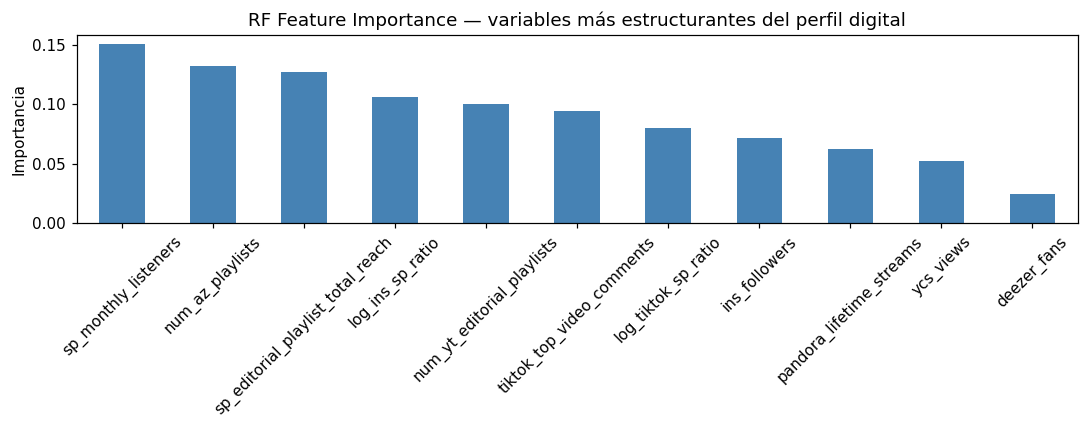

In [39]:
# === RF Unsupervised: feature importance ===
rng_rf = np.random.RandomState(SEED)
X_real = X_sc.values.astype(np.float32)
n_rf, p_rf = X_real.shape

X_synth = np.column_stack([
    rng_rf.permutation(X_real[:, j]) for j in range(p_rf)
]).astype(np.float32)

X_tr = np.vstack([X_real, X_synth])
y_tr = np.array([1]*n_rf + [0]*n_rf)

rf = RandomForestClassifier(n_estimators=100, max_depth=10,
                             min_samples_leaf=5, n_jobs=-1, random_state=SEED)
rf.fit(X_tr, y_tr)

fi = pd.Series(rf.feature_importances_, index=ALL_FEATS).sort_values(ascending=False)
print('Feature importance RF (real vs sintético):')
print(fi.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
fi.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('RF Feature Importance — variables más estructurantes del perfil digital')
ax.set_ylabel('Importancia'); ax.set_xlabel('')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

# SPECTRAL
**Parte B — Spectral Clustering (kNN affinity):**  
Construye un grafo de vecinos más cercanos (k=30) sobre el espacio escalado y aplica clustering espectral.  
Captura relaciones no lineales de densidad local sin supuestos de forma de cluster y sin
necesidad de precalcular una matriz densa de distancias.

In [40]:
# === Spectral Clustering (kNN affinity, no lineal) ===
sp_res = {}
for k in [2, 3, 4, 5, 6, 7, 8, 9]:
    print(f'Spectral k={k}...')
    sc = SpectralClustering(n_clusters=k, affinity='nearest_neighbors',
                            n_neighbors=30, assign_labels='kmeans',
                            n_init=10, random_state=SEED, n_jobs=-1)
    labels_sp = sc.fit_predict(X_sc.values)
    sil = silhouette_score(X_sc.values, labels_sp)
    db  = davies_bouldin_score(X_sc.values, labels_sp)
    ch  = calinski_harabasz_score(X_sc.values, labels_sp)
    sizes = dict(zip(*np.unique(labels_sp, return_counts=True)))
    min_pct = 100 * min(sizes.values()) / 7000
    print(f'  sil={sil:.4f}  DB={db:.4f}  CH={ch:.0f}  min%={min_pct:.1f}  sizes={sizes}')
    sp_res[k] = dict(labels=labels_sp, sil=sil, db=db, ch=ch, sizes=sizes)

Spectral k=2...


  sil=0.5305  DB=1.0366  CH=1677  min%=5.0  sizes={np.int32(0): np.int64(6652), np.int32(1): np.int64(348)}
Spectral k=3...


  sil=0.1674  DB=1.2356  CH=1490  min%=4.4  sizes={np.int32(0): np.int64(1012), np.int32(1): np.int64(5680), np.int32(2): np.int64(308)}
Spectral k=4...


  sil=0.1109  DB=1.2067  CH=1085  min%=4.4  sizes={np.int32(0): np.int64(5596), np.int32(1): np.int64(666), np.int32(2): np.int64(308), np.int32(3): np.int64(430)}
Spectral k=5...


  sil=0.1212  DB=1.1140  CH=935  min%=0.9  sizes={np.int32(0): np.int64(406), np.int32(1): np.int64(5578), np.int32(2): np.int64(646), np.int32(3): np.int64(64), np.int32(4): np.int64(306)}
Spectral k=6...


  sil=0.1126  DB=1.4496  CH=1013  min%=0.9  sizes={np.int32(0): np.int64(2932), np.int32(1): np.int64(64), np.int32(2): np.int64(2839), np.int32(3): np.int64(283), np.int32(4): np.int64(418), np.int32(5): np.int64(464)}
Spectral k=7...


  sil=0.1048  DB=1.4253  CH=1005  min%=0.9  sizes={np.int32(0): np.int64(1893), np.int32(1): np.int64(1959), np.int32(2): np.int64(63), np.int32(3): np.int64(282), np.int32(4): np.int64(283), np.int32(5): np.int64(393), np.int32(6): np.int64(2127)}
Spectral k=8...


  sil=0.1165  DB=1.3898  CH=987  min%=0.9  sizes={np.int32(0): np.int64(1205), np.int32(1): np.int64(1393), np.int32(2): np.int64(278), np.int32(3): np.int64(197), np.int32(4): np.int64(278), np.int32(5): np.int64(63), np.int32(6): np.int64(1737), np.int32(7): np.int64(1849)}
Spectral k=9...


  sil=0.1266  DB=1.3395  CH=1017  min%=0.9  sizes={np.int32(0): np.int64(1228), np.int32(1): np.int64(1720), np.int32(2): np.int64(998), np.int32(3): np.int64(257), np.int32(4): np.int64(197), np.int32(5): np.int64(1794), np.int32(6): np.int64(64), np.int32(7): np.int64(479), np.int32(8): np.int64(263)}


In [41]:
from sklearn.metrics import silhouette_samples, silhouette_score

# ============================================================
# Silhouette por cluster para Spectral Clustering
# ============================================================

k_elegido = 2

labels_spectral = sp_res[k_elegido]["labels"]

sil_samples = silhouette_samples(X_sc.values, labels_spectral)
sil_avg = silhouette_score(X_sc.values, labels_spectral)

tabla_sil_spectral = (
    pd.DataFrame({
        "cluster": labels_spectral,
        "silhouette": sil_samples
    })
    .groupby("cluster")
    .agg(
        n_artistas=("cluster", "size"),
        silhouette_media=("silhouette", "mean"),
        silhouette_mediana=("silhouette", "median"),
        silhouette_min=("silhouette", "min"),
        pct_sil_negativa=("silhouette", lambda x: (x < 0).mean() * 100)
    )
    .sort_index()
)

print(f"Spectral k={k_elegido}")
print(f"Silhouette promedio: {sil_avg:.3f}")
display(tabla_sil_spectral.round(3))

Spectral k=2
Silhouette promedio: 0.531


,n_artistas,silhouette_media,silhouette_mediana,silhouette_min,pct_sil_negativa
cluster,,,,,
0,6652,0.545,0.581,-0.125,0.301
1,348,0.253,0.288,-0.223,7.759


In [42]:
# ============================================================
# Perfil descriptivo de clusters Spectral k=2
# ============================================================

k_elegido = 2
cluster_col = f"cluster_spectral_k{k_elegido}"

df_spectral_perfil = df.copy()
df_spectral_perfil[cluster_col] = sp_res[k_elegido]["labels"]

# Ratios como diferencia de logs, misma construcción que la celda de escalado
df_spectral_perfil["social_sp_ratio"] = df_log["log_ins_sp_ratio"]
df_spectral_perfil["tiktok_sp_ratio"] = df_log["log_tiktok_sp_ratio"]

if "youtube_sp_ratio" in df_log.columns:
    df_spectral_perfil["youtube_sp_ratio"] = df_log["youtube_sp_ratio"]

vars_perfil = [
    "sp_monthly_listeners",
    "sp_followers",
    "sp_editorial_playlist_total_reach",
    "num_az_playlists",
    "num_yt_editorial_playlists",
    "tiktok_top_video_comments",
    "ins_followers",
    "ycs_views",
    "pandora_lifetime_streams",
    "deezer_fans",
    "social_sp_ratio",
    "tiktok_sp_ratio",
    "n_shows_24_25"
]

if "youtube_sp_ratio" in df_spectral_perfil.columns:
    vars_perfil.append("youtube_sp_ratio")

vars_perfil = [v for v in vars_perfil if v in df_spectral_perfil.columns]

tabla_perfil_spectral = (
    df_spectral_perfil
    .groupby(cluster_col)
    .agg(
        n_artistas=(cluster_col, "size"),
        **{
            f"mediana_{var}": (var, "median")
            for var in vars_perfil
        }
    )
)

tabla_perfil_spectral.round(3)

,n_artistas,mediana_sp_monthly_listeners,mediana_sp_followers,mediana_sp_editorial_playlist_total_reach,mediana_num_az_playlists,mediana_num_yt_editorial_playlists,mediana_tiktok_top_video_comments,mediana_ins_followers,mediana_ycs_views,mediana_pandora_lifetime_streams,mediana_deezer_fans,mediana_social_sp_ratio,mediana_tiktok_sp_ratio,mediana_n_shows_24_25
cluster_spectral_k2,,,,,,,,,,,,,,
0,6652,3352967.5,990161.5,7293678.5,55.0,5.0,760628.5,625076.0,366332320.0,42166211.5,13427.0,-1.668,-1.545,13.0
1,348,19759.0,24999.5,0.0,5.0,0.0,14636.5,1846379.0,364381422.5,65608.5,500.5,4.206,-1.135,1.0


In [43]:
# ============================================================
# Sensibilidad de Spectral Clustering ante n_neighbors
# ============================================================

spectral_sens_res = {}

for n_neighbors_value in [10, 20, 30, 50, 100]:
    
    spectral_sens_res[n_neighbors_value] = {}
    
    for k in [2, 3, 4, 5]:
        
        print(f"Spectral n_neighbors={n_neighbors_value}, k={k}...")
        
        sc = SpectralClustering(
            n_clusters=k,
            affinity="nearest_neighbors",
            n_neighbors=n_neighbors_value,
            assign_labels="kmeans",
            n_init=10,
            random_state=SEED,
            n_jobs=-1
        )
        
        labels_tmp = sc.fit_predict(X_sc.values)
        
        sil = silhouette_score(X_sc.values, labels_tmp)
        db = davies_bouldin_score(X_sc.values, labels_tmp)
        ch = calinski_harabasz_score(X_sc.values, labels_tmp)
        sizes = dict(zip(*np.unique(labels_tmp, return_counts=True)))
        min_pct = 100 * min(sizes.values()) / X_sc.shape[0]
        
        print(
            f"  sil={sil:.4f}  DB={db:.4f}  CH={ch:.0f}  "
            f"min%={min_pct:.1f}  sizes={sizes}"
        )
        
        spectral_sens_res[n_neighbors_value][k] = {
            "labels": labels_tmp,
            "sil": sil,
            "db": db,
            "ch": ch,
            "sizes": sizes,
            "min_pct": min_pct
        }

Spectral n_neighbors=10, k=2...


  sil=0.5372  DB=1.0070  CH=1594  min%=4.5  sizes={np.int32(0): np.int64(6686), np.int32(1): np.int64(314)}
Spectral n_neighbors=10, k=3...


  sil=0.1690  DB=1.2139  CH=1433  min%=4.4  sizes={np.int32(0): np.int64(898), np.int32(1): np.int64(5797), np.int32(2): np.int64(305)}
Spectral n_neighbors=10, k=4...


  sil=0.1144  DB=1.1686  CH=1025  min%=4.4  sizes={np.int32(0): np.int64(5766), np.int32(1): np.int64(349), np.int32(2): np.int64(580), np.int32(3): np.int64(305)}
Spectral n_neighbors=10, k=5...


  sil=0.1251  DB=1.0851  CH=888  min%=0.9  sizes={np.int32(0): np.int64(553), np.int32(1): np.int64(5743), np.int32(2): np.int64(305), np.int32(3): np.int64(333), np.int32(4): np.int64(66)}
Spectral n_neighbors=20, k=2...


...

  sil=0.1207  DB=1.1327  CH=967  min%=1.0  sizes={np.int32(0): np.int64(667), np.int32(1): np.int64(71), np.int32(2): np.int64(5494), np.int32(3): np.int64(458), np.int32(4): np.int64(310)}
Spectral n_neighbors=100, k=2...


  sil=0.1238  DB=1.5662  CH=1352  min%=25.8  sizes={np.int32(0): np.int64(5197), np.int32(1): np.int64(1803)}
Spectral n_neighbors=100, k=3...


  sil=0.1678  DB=1.2491  CH=1545  min%=4.6  sizes={np.int32(0): np.int64(1099), np.int32(1): np.int64(5582), np.int32(2): np.int64(319)}
Spectral n_neighbors=100, k=4...


  sil=0.1070  DB=1.2598  CH=1167  min%=4.5  sizes={np.int32(0): np.int64(588), np.int32(1): np.int64(5307), np.int32(2): np.int64(787), np.int32(3): np.int64(318)}
Spectral n_neighbors=100, k=5...


  sil=0.1141  DB=1.6266  CH=1206  min%=4.3  sizes={np.int32(0): np.int64(2870), np.int32(1): np.int64(302), np.int32(2): np.int64(730), np.int32(3): np.int64(579), np.int32(4): np.int64(2519)}


In [44]:
from sklearn.metrics import adjusted_rand_score

# ============================================================
# Estabilidad de Spectral k=2 ante n_neighbors
# ============================================================

ari_rows = []

neighbors_list = sorted(spectral_sens_res.keys())

for i, nn_i in enumerate(neighbors_list):
    for nn_j in neighbors_list[i + 1:]:
        
        labels_i = spectral_sens_res[nn_i][2]["labels"]
        labels_j = spectral_sens_res[nn_j][2]["labels"]
        
        ari = adjusted_rand_score(labels_i, labels_j)
        
        ari_rows.append({
            "n_neighbors_i": nn_i,
            "n_neighbors_j": nn_j,
            "ARI": ari
        })

tabla_ari_spectral = pd.DataFrame(ari_rows)
tabla_ari_spectral.round(3)

,n_neighbors_i,n_neighbors_j,ARI
0,10,20,0.954
1,10,30,0.941
2,10,50,0.906
3,10,100,-0.048
4,20,30,0.983
5,20,50,0.951
6,20,100,-0.051
7,30,50,0.964
8,30,100,-0.052
9,50,100,-0.054


# comparación GSS Spectral

In [45]:
from sklearn.metrics import adjusted_rand_score

# ============================================================
# Comparación global entre soluciones de clustering
# ============================================================

labels_kmedoids = km_res[2]["labels"]
labels_gmm = gmm_res["full"][2]["labels"]
labels_spectral = sp_res[2]["labels"]

comparacion_global = pd.DataFrame([
    {
        "metodo_a": "K-Medoids k=2",
        "metodo_b": "GMM full k=2",
        "ARI": adjusted_rand_score(labels_kmedoids, labels_gmm)
    },
    {
        "metodo_a": "K-Medoids k=2",
        "metodo_b": "Spectral k=2",
        "ARI": adjusted_rand_score(labels_kmedoids, labels_spectral)
    },
    {
        "metodo_a": "GMM full k=2",
        "metodo_b": "Spectral k=2",
        "ARI": adjusted_rand_score(labels_gmm, labels_spectral)
    }
])

comparacion_global.round(3)

,metodo_a,metodo_b,ARI
0,K-Medoids k=2,GMM full k=2,0.336
1,K-Medoids k=2,Spectral k=2,0.052
2,GMM full k=2,Spectral k=2,0.171


In [46]:
# ============================================================
# Solapamiento entre clusters de interés
# ============================================================

df_overlap = df.loc[X_sc.index, ["chartmetric_id"]].copy()

# df_overlap = pd.DataFrame(index=df.index) 

df_overlap["kmedoids_cluster"] = km_res[2]["labels"]
df_overlap["gmm_cluster"] = gmm_res["full"][2]["labels"]
df_overlap["spectral_cluster"] = sp_res[2]["labels"]

# Ajustar estos valores según el cluster que se quiera inspeccionar
mask_kmedoids_interes = df_overlap["kmedoids_cluster"] == 1
mask_gmm_minoritario = df_overlap["gmm_cluster"] == 1
mask_spectral_minoritario = df_overlap["spectral_cluster"] == 1

def resumen_solapamiento(mask_a, mask_b, nombre_a, nombre_b):
    
    interseccion = (mask_a & mask_b).sum()
    n_a = mask_a.sum()
    n_b = mask_b.sum()
    
    return {
        "grupo_a": nombre_a,
        "grupo_b": nombre_b,
        "n_a": n_a,
        "n_b": n_b,
        "interseccion": interseccion,
        "pct_de_a_en_b": 100 * interseccion / n_a,
        "pct_de_b_en_a": 100 * interseccion / n_b
    }

tabla_solapamientos = pd.DataFrame([
    resumen_solapamiento(
        mask_kmedoids_interes,
        mask_spectral_minoritario,
        "K-Medoids cluster 1",
        "Spectral cluster minoritario"
    ),
    resumen_solapamiento(
        mask_gmm_minoritario,
        mask_spectral_minoritario,
        "GMM cluster minoritario",
        "Spectral cluster minoritario"
    ),
    resumen_solapamiento(
        mask_kmedoids_interes,
        mask_gmm_minoritario,
        "K-Medoids cluster 1",
        "GMM cluster minoritario"
    )
])

tabla_solapamientos.round(2)

,grupo_a,grupo_b,n_a,n_b,interseccion,pct_de_a_en_b,pct_de_b_en_a
0,K-Medoids cluster 1,Spectral cluster minoritario,2873,348,346,12.04,99.43
1,GMM cluster minoritario,Spectral cluster minoritario,1888,348,348,18.43,100.00
2,K-Medoids cluster 1,GMM cluster minoritario,2873,1888,1652,57.50,87.50


In [47]:
rows_cmp = []
for k in [2, 3, 4, 5, 6, 7, 8, 9]:
    for method, res in [('K-Medoids', km_res[k]),
                         ('GMM-full',  gmm_res['full'][k]),
                         ('GMM-tied',  gmm_res['tied'][k]),
                         ('Spectral',  sp_res[k])]:
        min_size_pct = 100 * min(res['sizes'].values()) / 7000
        rows_cmp.append({
            'method': method, 'k': k,
            'silhouette':       round(res['sil'], 4),
            'davies_bouldin':   round(res['db'],  4),
            'calinski_harabasz':round(res['ch'],  1),
            'min_cluster_%':    round(min_size_pct, 1),
        })

cmp_df = pd.DataFrame(rows_cmp)
# Usable: sil > 0.15 AND min cluster >= 4% (280+ artistas con n=7000)
cmp_df['usable'] = (cmp_df['silhouette'] > 0.15) & (cmp_df['min_cluster_%'] >= 4.0)
print(cmp_df.sort_values(['method','k']).to_string(index=False))

   method  k  silhouette  davies_bouldin  calinski_harabasz  min_cluster_%  usable
 GMM-full  2      0.2782          2.0139             1438.3           27.0    True
 GMM-full  3      0.1227          2.2463             1176.5           10.3   False
 GMM-full  4      0.1259          2.0236             1099.6            8.8   False
 GMM-full  5      0.0375          2.7168              677.6            6.1   False
 GMM-full  6      0.0501          2.3740              643.8            7.5   False
 GMM-full  7      0.0538          3.2510              594.3            3.3   False
 GMM-full  8      0.0733          2.4438              684.1            2.9   False
 GMM-full  9      0.0336          2.8561              596.5            3.2   False
 GMM-tied  2      0.5184          1.0102             1519.6            4.6    True
 GMM-tied  3      0.1444          1.6509             1516.5            4.6   False
 GMM-tied  4      0.1239          1.9946             1219.4            4.5   False
 GMM

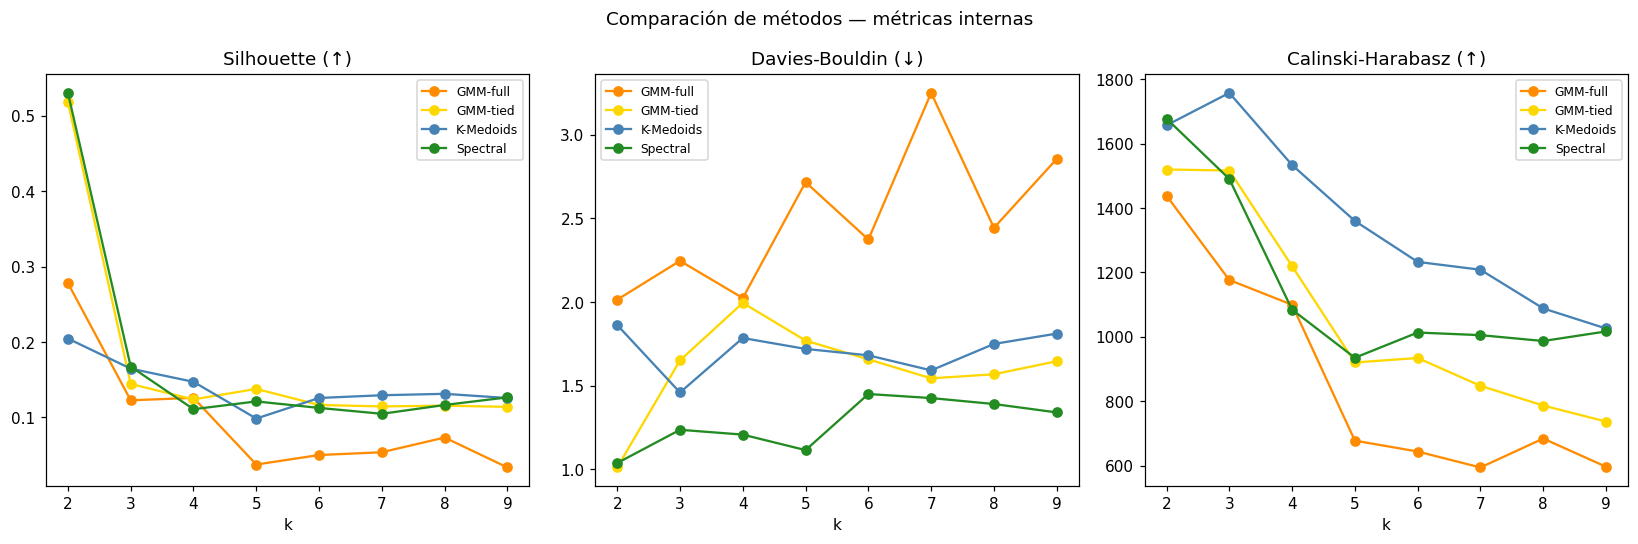

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors = {'K-Medoids':'steelblue','GMM-full':'darkorange',
          'GMM-tied':'gold','Spectral':'forestgreen'}
ks = [2, 3, 4, 5, 6, 7, 8, 9]

for ax, metric, title in zip(
        axes,
        ['silhouette','davies_bouldin','calinski_harabasz'],
        ['Silhouette (↑)','Davies-Bouldin (↓)','Calinski-Harabasz (↑)']):
    for method, grp in cmp_df.groupby('method'):
        ax.plot(grp['k'], grp[metric], 'o-',
                color=colors[method], label=method, linewidth=1.5, markersize=6)
    ax.set_title(title); ax.set_xlabel('k'); ax.legend(fontsize=8)

plt.suptitle('Comparación de métodos — métricas internas', fontsize=12)
plt.tight_layout(); plt.show()

# overlap GMM spectral

In [49]:
# ============================================================
# Control explícito de alineación por ID
# ============================================================

df_overlap = pd.DataFrame(index=df.index)

df_overlap["chartmetric_id"] = df["chartmetric_id"]
df_overlap["artist_name"] = df["artist_name"]

df_overlap["kmedoids_cluster"] = km_res[2]["labels"]
df_overlap["gmm_cluster"] = gmm_res["full"][2]["labels"]
df_overlap["spectral_cluster"] = sp_res[2]["labels"]

# Control básico: cantidad de filas
print(df_overlap.shape)
print(df.shape)

# Control de IDs únicos
print("IDs únicos en df_overlap:", df_overlap["chartmetric_id"].nunique())
print("Filas en df_overlap:", len(df_overlap))

df_overlap.head()

(7000, 5)
(7000, 53)
IDs únicos en df_overlap: 7000
Filas en df_overlap: 7000


In [50]:
# ============================================================
# Verificación del subconjunto Spectral dentro de GMM
# ============================================================

mask_gmm_minoritario = df_overlap["gmm_cluster"] == 1
mask_spectral_minoritario = df_overlap["spectral_cluster"] == 1

ids_spectral = set(df_overlap.loc[mask_spectral_minoritario, "chartmetric_id"])
ids_gmm = set(df_overlap.loc[mask_gmm_minoritario, "chartmetric_id"])

print("Spectral minoritario:", len(ids_spectral))
print("GMM minoritario:", len(ids_gmm))
print("Intersección:", len(ids_spectral & ids_gmm))
print("Spectral contenido en GMM:", ids_spectral.issubset(ids_gmm))

Spectral minoritario: 348
GMM minoritario: 1888
Intersección: 348
Spectral contenido en GMM: True


,grupo,n,pct_total
0,Resto de la muestra,5112,73.028571
1,GMM minoritario fuera de Spectral,1540,22.000000
2,Núcleo Spectral dentro de GMM,348,4.971429
3,Spectral minoritario fuera de GMM,0,0.000000


ARI GMM full k=2 vs Spectral k=2: 0.171
Spectral minoritario dentro de GMM minoritario: 100.0%
Cluster minoritario GMM: 1
Cluster minoritario Spectral: 1


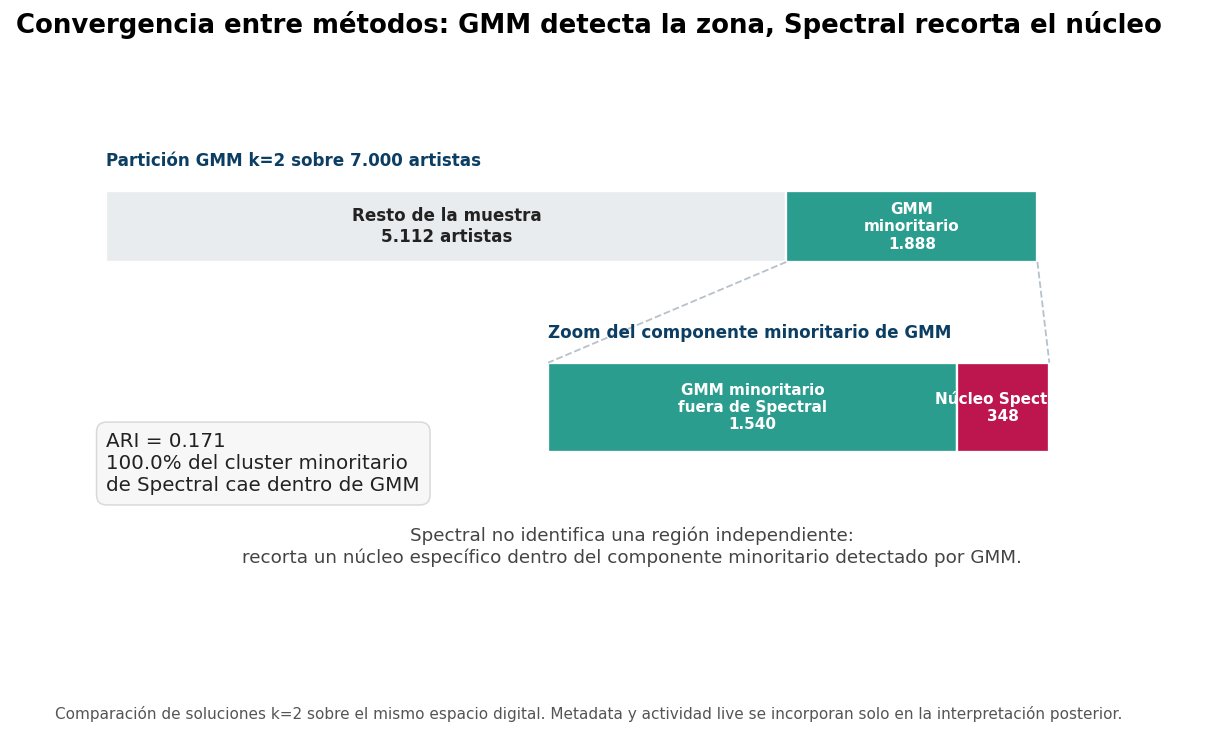

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\convergencia_gmm_spectral_k2_solapamiento.png


In [51]:
# ============================================================
# Figura de convergencia GMM k=2 y Spectral k=2
# Vista con barra general y zoom del componente minoritario GMM
# ============================================================

from sklearn.metrics import adjusted_rand_score
import matplotlib.patches as patches

# ------------------------------------------------------------
# Recuperación de etiquetas ya calculadas
# ------------------------------------------------------------

labels_gmm_k2 = gmm_res["full"][2]["labels"]
labels_spectral_k2 = sp_res[2]["labels"]

if len(labels_gmm_k2) != len(labels_spectral_k2):
    raise ValueError("Las etiquetas de GMM y Spectral tienen distinta longitud.")

if len(labels_gmm_k2) != len(df):
    raise ValueError("Las etiquetas no tienen la misma longitud que df.")

# ------------------------------------------------------------
# Identificación automática de clusters minoritarios
# ------------------------------------------------------------

conteo_gmm_k2 = pd.Series(labels_gmm_k2).value_counts()
conteo_spectral_k2 = pd.Series(labels_spectral_k2).value_counts()

cluster_minoritario_gmm = conteo_gmm_k2.idxmin()
cluster_minoritario_spectral = conteo_spectral_k2.idxmin()

pertenece_gmm_minoritario = labels_gmm_k2 == cluster_minoritario_gmm
pertenece_spectral_minoritario = labels_spectral_k2 == cluster_minoritario_spectral

# ------------------------------------------------------------
# Conteos de solapamiento
# ------------------------------------------------------------

n_total = len(df)

n_gmm_minoritario = pertenece_gmm_minoritario.sum()
n_spectral_minoritario = pertenece_spectral_minoritario.sum()

n_nucleo_spectral_en_gmm = (
    pertenece_gmm_minoritario &
    pertenece_spectral_minoritario
).sum()

n_gmm_minoritario_fuera_spectral = (
    pertenece_gmm_minoritario &
    ~pertenece_spectral_minoritario
).sum()

n_spectral_fuera_gmm = (
    ~pertenece_gmm_minoritario &
    pertenece_spectral_minoritario
).sum()

n_resto_muestra = (
    ~pertenece_gmm_minoritario &
    ~pertenece_spectral_minoritario
).sum()

ari_gmm_spectral = adjusted_rand_score(
    labels_gmm_k2,
    labels_spectral_k2
)

pct_spectral_dentro_gmm = (
    n_nucleo_spectral_en_gmm / n_spectral_minoritario * 100
)

# ------------------------------------------------------------
# Tabla de control
# ------------------------------------------------------------

tabla_control_solapamiento = pd.DataFrame({
    "grupo": [
        "Resto de la muestra",
        "GMM minoritario fuera de Spectral",
        "Núcleo Spectral dentro de GMM",
        "Spectral minoritario fuera de GMM"
    ],
    "n": [
        n_resto_muestra,
        n_gmm_minoritario_fuera_spectral,
        n_nucleo_spectral_en_gmm,
        n_spectral_fuera_gmm
    ],
    "pct_total": [
        n_resto_muestra / n_total * 100,
        n_gmm_minoritario_fuera_spectral / n_total * 100,
        n_nucleo_spectral_en_gmm / n_total * 100,
        n_spectral_fuera_gmm / n_total * 100
    ]
})

display(tabla_control_solapamiento)

print(f"ARI GMM full k=2 vs Spectral k=2: {ari_gmm_spectral:.3f}")
print(f"Spectral minoritario dentro de GMM minoritario: {pct_spectral_dentro_gmm:.1f}%")
print(f"Cluster minoritario GMM: {cluster_minoritario_gmm}")
print(f"Cluster minoritario Spectral: {cluster_minoritario_spectral}")

# ------------------------------------------------------------
# Parámetros visuales
# ------------------------------------------------------------

archivo_convergencia_gmm_spectral = (
    directorio_salidas_proyecto /
    "convergencia_gmm_spectral_k2_solapamiento.png"
)

color_resto = "#E9ECEF"
color_gmm = "#2A9D8F"
color_spectral = "#BD164F"
color_texto = "#222222"
color_linea = "#0C3E63"
color_borde = "white"

fig, ax = plt.subplots(figsize=(14, 7))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

# ------------------------------------------------------------
# Título
# ------------------------------------------------------------

fig.suptitle(
    "Convergencia entre métodos: GMM detecta la zona, Spectral recorta el núcleo",
    fontsize=17,
    fontweight="bold",
    y=0.96
)

# ------------------------------------------------------------
# Barra superior: muestra completa
# ------------------------------------------------------------

x0 = 0.08
y_top = 0.68
w_total = 0.78
h_bar = 0.12

w_resto = w_total * (n_resto_muestra / n_total)
w_gmm = w_total * (n_gmm_minoritario / n_total)

rect_resto = patches.Rectangle(
    (x0, y_top),
    w_resto,
    h_bar,
    facecolor=color_resto,
    edgecolor=color_borde,
    linewidth=1.5
)

rect_gmm = patches.Rectangle(
    (x0 + w_resto, y_top),
    w_gmm,
    h_bar,
    facecolor=color_gmm,
    edgecolor=color_borde,
    linewidth=1.5
)

ax.add_patch(rect_resto)
ax.add_patch(rect_gmm)

ax.text(
    x0 + w_resto / 2,
    y_top + h_bar / 2,
    f"Resto de la muestra\n{n_resto_muestra:,} artistas".replace(",", "."),
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color=color_texto
)

ax.text(
    x0 + w_resto + w_gmm / 2,
    y_top + h_bar / 2,
    f"GMM\nminoritario\n{n_gmm_minoritario:,}".replace(",", "."),
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="white"
)

ax.text(
    x0,
    y_top + h_bar + 0.035,
    "Partición GMM k=2 sobre 7.000 artistas",
    ha="left",
    va="bottom",
    fontsize=11,
    color=color_linea,
    fontweight="bold"
)

# ------------------------------------------------------------
# Barra inferior: zoom del GMM minoritario
# ------------------------------------------------------------

x_zoom = x0 + 0.37
y_zoom = 0.36
w_zoom = 0.42
h_zoom = 0.15

w_gmm_only_zoom = w_zoom * (n_gmm_minoritario_fuera_spectral / n_gmm_minoritario)
w_core_zoom = w_zoom * (n_nucleo_spectral_en_gmm / n_gmm_minoritario)

rect_gmm_only_zoom = patches.Rectangle(
    (x_zoom, y_zoom),
    w_gmm_only_zoom,
    h_zoom,
    facecolor=color_gmm,
    edgecolor=color_borde,
    linewidth=1.5
)

rect_core_zoom = patches.Rectangle(
    (x_zoom + w_gmm_only_zoom, y_zoom),
    w_core_zoom,
    h_zoom,
    facecolor=color_spectral,
    edgecolor=color_borde,
    linewidth=1.5
)

ax.add_patch(rect_gmm_only_zoom)
ax.add_patch(rect_core_zoom)

ax.text(
    x_zoom + w_gmm_only_zoom / 2,
    y_zoom + h_zoom / 2,
    f"GMM minoritario\nfuera de Spectral\n{n_gmm_minoritario_fuera_spectral:,}".replace(",", "."),
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="white"
)

ax.text(
    x_zoom + w_gmm_only_zoom + w_core_zoom / 2,
    y_zoom + h_zoom / 2,
    f"Núcleo Spectral\n{n_nucleo_spectral_en_gmm:,}".replace(",", "."),
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="white"
)

ax.text(
    x_zoom,
    y_zoom + h_zoom + 0.035,
    "Zoom del componente minoritario de GMM",
    ha="left",
    va="bottom",
    fontsize=11,
    color=color_linea,
    fontweight="bold"
)

# ------------------------------------------------------------
# Líneas de conexión entre GMM superior y zoom inferior
# ------------------------------------------------------------

x_gmm_top_ini = x0 + w_resto
x_gmm_top_fin = x0 + w_resto + w_gmm

ax.plot(
    [x_gmm_top_ini, x_zoom],
    [y_top, y_zoom + h_zoom],
    color="#B8C2CC",
    linewidth=1.2,
    linestyle="--"
)

ax.plot(
    [x_gmm_top_fin, x_zoom + w_zoom],
    [y_top, y_zoom + h_zoom],
    color="#B8C2CC",
    linewidth=1.2,
    linestyle="--"
)

# ------------------------------------------------------------
# Métricas destacadas
# ------------------------------------------------------------

texto_metricas = (
    f"ARI = {ari_gmm_spectral:.3f}\n"
    f"{pct_spectral_dentro_gmm:.1f}% del cluster minoritario\n"
    f"de Spectral cae dentro de GMM"
)

ax.text(
    0.08,
    0.34,
    texto_metricas,
    ha="left",
    va="center",
    fontsize=13,
    color=color_texto,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#F7F7F7",
        edgecolor="#D9D9D9"
    )
)

# ------------------------------------------------------------
# Interpretación sintética
# ------------------------------------------------------------

if n_spectral_fuera_gmm == 0:
    texto_interpretacion = (
        "Spectral no identifica una región independiente:\n"
        "recorta un núcleo específico dentro del componente minoritario detectado por GMM."
    )
else:
    texto_interpretacion = (
        f"{n_spectral_fuera_gmm} artistas del cluster minoritario de Spectral\n"
        "quedan fuera del componente minoritario de GMM."
    )

ax.text(
    0.52,
    0.20,
    texto_interpretacion,
    ha="center",
    va="center",
    fontsize=12,
    color="#444444"
)

# ------------------------------------------------------------
# Footer
# ------------------------------------------------------------

fig.text(
    0.5,
    0.04,
    "Comparación de soluciones k=2 sobre el mismo espacio digital. Metadata y actividad live se incorporan solo en la interpretación posterior.",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.savefig(
    archivo_convergencia_gmm_spectral,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25
)

plt.show()

print("Archivo guardado en:", archivo_convergencia_gmm_spectral)

,grupo,n,pct_total
0,Resto de la muestra,5112,73.028571
1,GMM minoritario fuera de Spectral,1540,22.000000
2,Núcleo Spectral dentro de GMM,348,4.971429
3,Spectral minoritario fuera de GMM,0,0.000000


ARI GMM full k=2 vs Spectral k=2: 0.171
Spectral minoritario dentro de GMM minoritario: 100.0%
Cluster minoritario GMM: 1
Cluster minoritario Spectral: 1


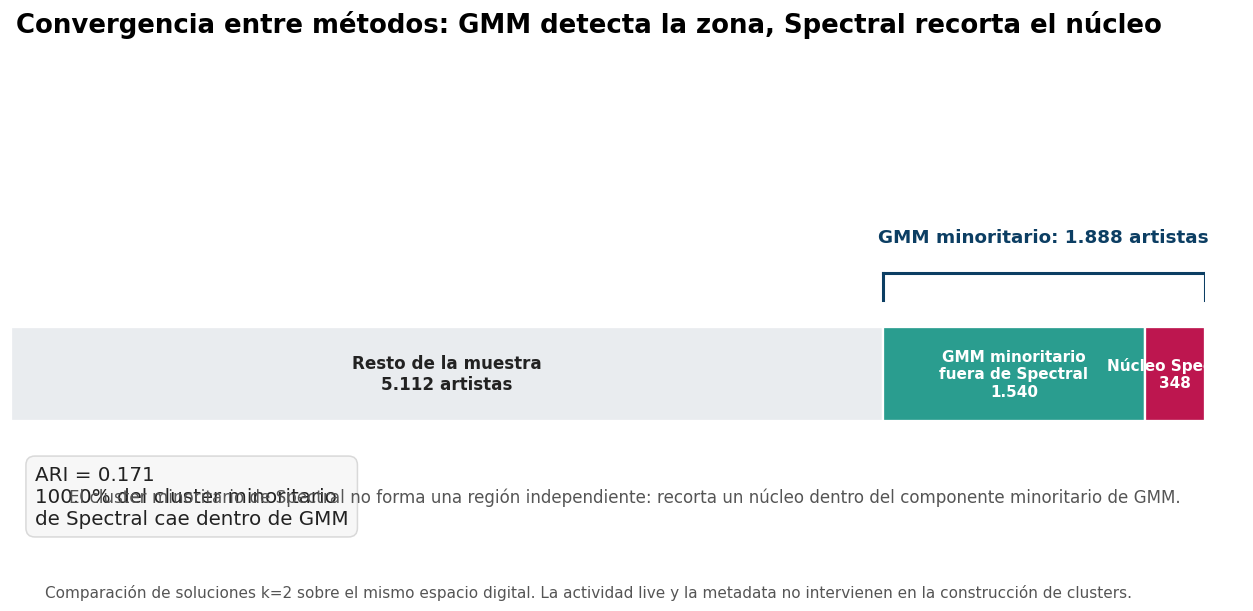

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\convergencia_gmm_spectral_k2_solapamiento.png


In [52]:
# ============================================================
# Figura de convergencia GMM k=2 y Spectral k=2
# GMM detecta zona minoritaria y Spectral recorta el núcleo
# ============================================================

from sklearn.metrics import adjusted_rand_score

# ------------------------------------------------------------
# Recuperación de etiquetas ya calculadas
# ------------------------------------------------------------

labels_gmm_k2 = gmm_res["full"][2]["labels"]
labels_spectral_k2 = sp_res[2]["labels"]

if len(labels_gmm_k2) != len(labels_spectral_k2):
    raise ValueError("Las etiquetas de GMM y Spectral tienen distinta longitud.")

if len(labels_gmm_k2) != len(df):
    raise ValueError("Las etiquetas no tienen la misma longitud que df.")

# ------------------------------------------------------------
# Identificación automática de clusters minoritarios
# ------------------------------------------------------------

conteo_gmm_k2 = pd.Series(labels_gmm_k2).value_counts()
conteo_spectral_k2 = pd.Series(labels_spectral_k2).value_counts()

cluster_minoritario_gmm = conteo_gmm_k2.idxmin()
cluster_minoritario_spectral = conteo_spectral_k2.idxmin()

pertenece_gmm_minoritario = labels_gmm_k2 == cluster_minoritario_gmm
pertenece_spectral_minoritario = labels_spectral_k2 == cluster_minoritario_spectral

# ------------------------------------------------------------
# Grupos de solapamiento
# ------------------------------------------------------------

n_total = len(df)

n_gmm_minoritario = pertenece_gmm_minoritario.sum()
n_spectral_minoritario = pertenece_spectral_minoritario.sum()

n_nucleo_spectral_en_gmm = (
    pertenece_gmm_minoritario &
    pertenece_spectral_minoritario
).sum()

n_gmm_minoritario_fuera_spectral = (
    pertenece_gmm_minoritario &
    ~pertenece_spectral_minoritario
).sum()

n_spectral_fuera_gmm = (
    ~pertenece_gmm_minoritario &
    pertenece_spectral_minoritario
).sum()

n_resto_muestra = (
    ~pertenece_gmm_minoritario &
    ~pertenece_spectral_minoritario
).sum()

ari_gmm_spectral = adjusted_rand_score(
    labels_gmm_k2,
    labels_spectral_k2
)

pct_spectral_dentro_gmm = (
    n_nucleo_spectral_en_gmm / n_spectral_minoritario * 100
)

# ------------------------------------------------------------
# Tabla de control
# ------------------------------------------------------------

tabla_control_solapamiento = pd.DataFrame({
    "grupo": [
        "Resto de la muestra",
        "GMM minoritario fuera de Spectral",
        "Núcleo Spectral dentro de GMM",
        "Spectral minoritario fuera de GMM"
    ],
    "n": [
        n_resto_muestra,
        n_gmm_minoritario_fuera_spectral,
        n_nucleo_spectral_en_gmm,
        n_spectral_fuera_gmm
    ],
    "pct_total": [
        n_resto_muestra / n_total * 100,
        n_gmm_minoritario_fuera_spectral / n_total * 100,
        n_nucleo_spectral_en_gmm / n_total * 100,
        n_spectral_fuera_gmm / n_total * 100
    ]
})

display(tabla_control_solapamiento)

print(f"ARI GMM full k=2 vs Spectral k=2: {ari_gmm_spectral:.3f}")
print(f"Spectral minoritario dentro de GMM minoritario: {pct_spectral_dentro_gmm:.1f}%")
print(f"Cluster minoritario GMM: {cluster_minoritario_gmm}")
print(f"Cluster minoritario Spectral: {cluster_minoritario_spectral}")

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

archivo_convergencia_gmm_spectral = (
    directorio_salidas_proyecto /
    "convergencia_gmm_spectral_k2_solapamiento.png"
)

color_resto = "#E9ECEF"
color_gmm_only = "#2A9D8F"
color_core = "#BD164F"
color_texto = "#222222"
color_borde = "#FFFFFF"
color_azul = "#0C3E63"

fig, ax = plt.subplots(figsize=(14, 5.8))

ax.set_xlim(0, n_total)
ax.set_ylim(-0.8, 1.4)
ax.axis("off")

# ------------------------------------------------------------
# Barra anidada principal
# ------------------------------------------------------------

inicio_resto = 0
inicio_gmm_only = n_resto_muestra
inicio_core = n_resto_muestra + n_gmm_minoritario_fuera_spectral

ax.barh(
    y=0,
    width=n_resto_muestra,
    left=inicio_resto,
    height=0.42,
    color=color_resto,
    edgecolor=color_borde,
    linewidth=1.5
)

ax.barh(
    y=0,
    width=n_gmm_minoritario_fuera_spectral,
    left=inicio_gmm_only,
    height=0.42,
    color=color_gmm_only,
    edgecolor=color_borde,
    linewidth=1.5
)

ax.barh(
    y=0,
    width=n_nucleo_spectral_en_gmm,
    left=inicio_core,
    height=0.42,
    color=color_core,
    edgecolor=color_borde,
    linewidth=1.5
)

# ------------------------------------------------------------
# Etiquetas internas y externas
# ------------------------------------------------------------

ax.text(
    inicio_resto + n_resto_muestra / 2,
    0,
    f"Resto de la muestra\n{n_resto_muestra:,} artistas".replace(",", "."),
    ha="center",
    va="center",
    fontsize=11,
    color=color_texto,
    fontweight="bold"
)

ax.text(
    inicio_gmm_only + n_gmm_minoritario_fuera_spectral / 2,
    0,
    f"GMM minoritario\nfuera de Spectral\n{n_gmm_minoritario_fuera_spectral:,}".replace(",", "."),
    ha="center",
    va="center",
    fontsize=10,
    color="white",
    fontweight="bold"
)

ax.text(
    inicio_core + n_nucleo_spectral_en_gmm / 2,
    0,
    f"Núcleo Spectral\n{n_nucleo_spectral_en_gmm:,}".replace(",", "."),
    ha="center",
    va="center",
    fontsize=10,
    color="white",
    fontweight="bold"
)

# ------------------------------------------------------------
# Corchete conceptual sobre zona GMM minoritaria
# ------------------------------------------------------------

x_gmm_ini = inicio_gmm_only
x_gmm_fin = inicio_core + n_nucleo_spectral_en_gmm
y_bracket = 0.45

ax.plot(
    [x_gmm_ini, x_gmm_fin],
    [y_bracket, y_bracket],
    color=color_azul,
    linewidth=2
)

ax.plot(
    [x_gmm_ini, x_gmm_ini],
    [y_bracket, y_bracket - 0.12],
    color=color_azul,
    linewidth=2
)

ax.plot(
    [x_gmm_fin, x_gmm_fin],
    [y_bracket, y_bracket - 0.12],
    color=color_azul,
    linewidth=2
)

ax.text(
    (x_gmm_ini + x_gmm_fin) / 2,
    y_bracket + 0.12,
    f"GMM minoritario: {n_gmm_minoritario:,} artistas".replace(",", "."),
    ha="center",
    va="bottom",
    fontsize=12,
    color=color_azul,
    fontweight="bold"
)

# ------------------------------------------------------------
# Métricas destacadas
# ------------------------------------------------------------

texto_metricas = (
    f"ARI = {ari_gmm_spectral:.3f}\n"
    f"{pct_spectral_dentro_gmm:.1f}% del cluster minoritario\n"
    f"de Spectral cae dentro de GMM"
)

ax.text(
    n_total * 0.02,
    -0.55,
    texto_metricas,
    ha="left",
    va="center",
    fontsize=13,
    color=color_texto,
    bbox=dict(
        boxstyle="round,pad=0.45",
        facecolor="#F7F7F7",
        edgecolor="#D9D9D9"
    )
)

# ------------------------------------------------------------
# Nota de excepción si existiera Spectral fuera de GMM
# ------------------------------------------------------------

if n_spectral_fuera_gmm > 0:
    texto_excepcion = (
        f"Atención: {n_spectral_fuera_gmm} artistas del cluster minoritario "
        "de Spectral quedan fuera del componente minoritario de GMM."
    )
else:
    texto_excepcion = (
        "El cluster minoritario de Spectral no forma una región independiente: "
        "recorta un núcleo dentro del componente minoritario de GMM."
    )

ax.text(
    n_total * 0.98,
    -0.55,
    texto_excepcion,
    ha="right",
    va="center",
    fontsize=11,
    color="#555555"
)

# ------------------------------------------------------------
# Título y footer
# ------------------------------------------------------------

fig.suptitle(
    "Convergencia entre métodos: GMM detecta la zona, Spectral recorta el núcleo",
    fontsize=17,
    fontweight="bold",
    y=0.96
)

fig.text(
    0.5,
    0.04,
    "Comparación de soluciones k=2 sobre el mismo espacio digital. La actividad live y la metadata no intervienen en la construcción de clusters.",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.savefig(
    archivo_convergencia_gmm_spectral,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25
)

plt.show()

print("Archivo guardado en:", archivo_convergencia_gmm_spectral)

# SPECTRAL k = 3

In [53]:
# # Auto-selección: mejor silhouette entre soluciones 'usable'
# OVERRIDE_METHOD = spe  # ej. 'K-Medoids' para forzar método
# OVERRIDE_K      = None   # ej. 3 para forzar k

# usable = cmp_df[cmp_df['usable']]
# if len(usable) == 0:
#     print('Ninguna solución supera los umbrales — se toma la de mayor silhouette total')
#     usable = cmp_df

# if OVERRIDE_METHOD and OVERRIDE_K:
#     best_row = cmp_df[(cmp_df['method']==OVERRIDE_METHOD) & (cmp_df['k']==OVERRIDE_K)].iloc[0]
# else:
#     best_row = usable.sort_values('silhouette', ascending=False).iloc[0]

# BM = best_row['method']
# BK = int(best_row['k'])
# print(f'Mejor modelo: {BM}  k={BK}')
# print(f'  Silhouette={best_row["silhouette"]}  DB={best_row["davies_bouldin"]}  '
#       f'CH={best_row["calinski_harabasz"]}  min_cluster%={best_row["min_cluster_%"]}')

# # Recuperar etiquetas
# if BM == 'K-Medoids':
#     best_labels = km_res[BK]['labels']
# elif BM == 'GMM-full':
#     best_labels = gmm_res['full'][BK]['labels']
# elif BM == 'GMM-tied':
#     best_labels = gmm_res['tied'][BK]['labels']
# else:
#     best_labels = sp_res[BK]['labels']

# df_work      = df.copy()
# df_work['cluster'] = best_labels
# df_log['cluster']  = best_labels

# print('\nTamaño de clusters:')
# print(df_work['cluster'].value_counts().sort_index())

In [54]:
# ============================================================
# Selección forzada: Spectral k=3
# ============================================================

OVERRIDE_METHOD = "Spectral"
OVERRIDE_K = 3

# ------------------------------------------------------------
# Recuperación de métricas internas de la solución elegida
# ------------------------------------------------------------

best_row = (
    cmp_df
    .loc[
        (cmp_df["method"] == OVERRIDE_METHOD) &
        (cmp_df["k"] == OVERRIDE_K)
    ]
    .iloc[0]
)

BM = best_row["method"]
BK = int(best_row["k"])

print(f"Modelo seleccionado: {BM}  k={BK}")
print(
    f'  Silhouette={best_row["silhouette"]}  '
    f'DB={best_row["davies_bouldin"]}  '
    f'CH={best_row["calinski_harabasz"]}  '
    f'min_cluster%={best_row["min_cluster_%"]}'
)

# ------------------------------------------------------------
# Recuperación de etiquetas Spectral k=3
# ------------------------------------------------------------

best_labels = sp_res[BK]["labels"]

# ------------------------------------------------------------
# Dataframes finales con etiquetas Spectral k=3
# ------------------------------------------------------------

df_cluster_spectral_k3 = df.copy()
df_cluster_spectral_k3["cluster"] = best_labels

df_log_cluster_spectral_k3 = df_log.copy()
df_log_cluster_spectral_k3["cluster"] = best_labels

# ------------------------------------------------------------
# Alias opcionales para mantener compatibilidad con celdas previas
# ------------------------------------------------------------

df_work = df_cluster_spectral_k3.copy()
df_log["cluster"] = best_labels

print("\nTamaño de clusters Spectral k=3:")
print(df_cluster_spectral_k3["cluster"].value_counts().sort_index())

display(
    df_cluster_spectral_k3["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="n_artistas")
)

Modelo seleccionado: Spectral  k=3
  Silhouette=0.1674  DB=1.2356  CH=1490.3  min_cluster%=4.4

Tamaño de clusters Spectral k=3:
cluster
0    1012
1    5680
2     308
Name: count, dtype: int64


,cluster,n_artistas
0,0,1012
1,1,5680
2,2,308


In [55]:
# ============================================================
# Compatibilidad de colores para celdas previas
# ============================================================

COLORS = [
    "#F2C94C",  # Headliners
    "#2A9D8F",  # Performers
    "#BD164F"   # Streamers
]

# Cruce con metadata

In [56]:
for var in ['genre_short', 'country_short', 'pronoun_short',
            'major_record_label', 'band']:
    ct = (pd.crosstab(df_work['cluster'], df_work[var],
                      normalize='index') * 100).round(1)
    print(f'\n--- {var} (% dentro del cluster) ---')
    print(ct.to_string())


--- genre_short (% dentro del cluster) ---
genre_short  Alternative & indie  Country & folk  Electronic & dance  Hip-hop & trap  Jazz & blues & classical   Latin & urban  Miscellaneous   Pop  R&b, soul & funk  Regional global  Regional mexicano  Rock & metal
cluster                                                                                                                                                                                                                
0                            6.1             6.2                 7.6            15.7                        0.6           12.8            0.8  21.9              10.0              4.2                3.6          10.4
1                            6.8             3.8                14.4            12.6                        2.9            9.5            2.2  19.8               6.7             10.2                3.3           7.9
2                            3.9             1.0                10.7            15.6        

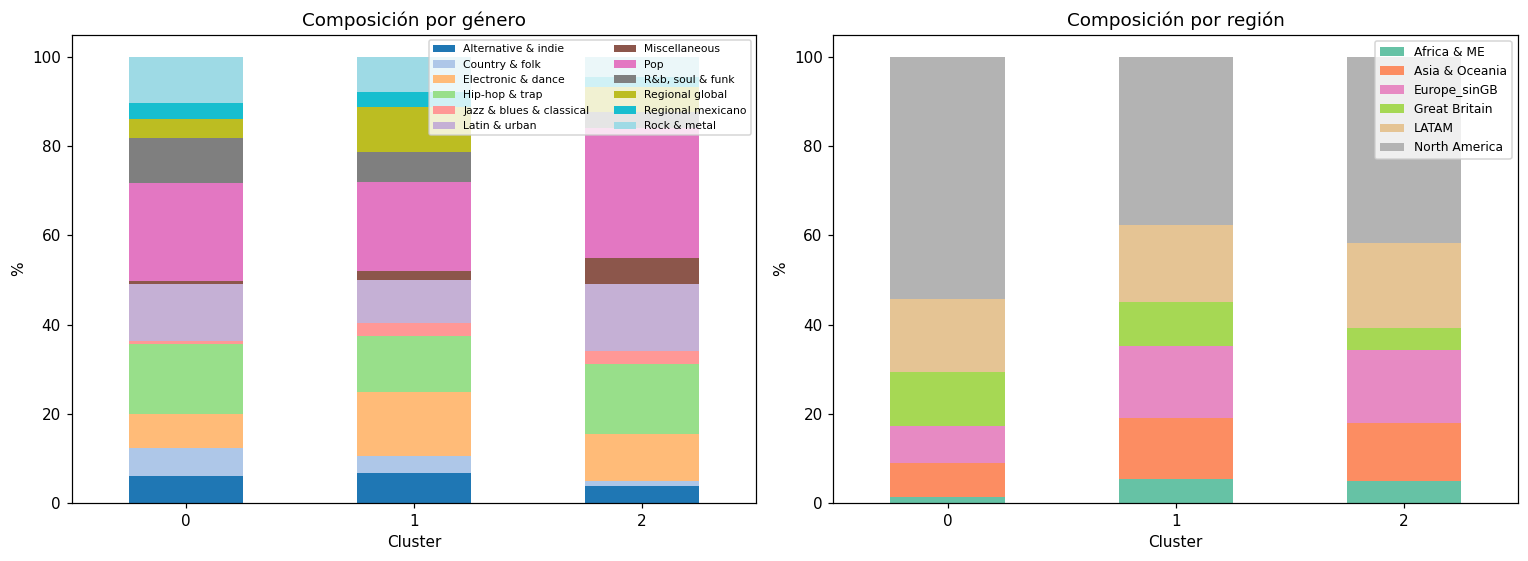

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4 + BK * 0.4))

genre_ct = (pd.crosstab(df_work['cluster'], df_work['genre_short'],
                        normalize='index') * 100)
genre_ct.plot(kind='bar', stacked=True, ax=axes[0],
              colormap='tab20', legend=True)
axes[0].set_title('Composición por género')
axes[0].set_xlabel('Cluster'); axes[0].set_ylabel('%')
axes[0].legend(loc='upper right', fontsize=7, ncol=2)
axes[0].tick_params(axis='x', rotation=0)

region_ct = (pd.crosstab(df_work['cluster'], df_work['country_short'],
                         normalize='index') * 100)
region_ct.plot(kind='bar', stacked=True, ax=axes[1],
               colormap='Set2', legend=True)
axes[1].set_title('Composición por región')
axes[1].set_xlabel('Cluster'); axes[1].set_ylabel('%')
axes[1].legend(loc='upper right', fontsize=8)
axes[1].tick_params(axis='x', rotation=0)


ruta_clust_region_genre = (
    directorio_salidas_proyecto /
    "spectral3_region_genre.png"
)

plt.savefig(
    ruta_clust_region_genre,
    dpi=300,
    bbox_inches="tight"
)


plt.tight_layout(); plt.show()

# Cruce con actividad en vivo (subset 4 913)

El cluster fue asignado sobre los 7 000 artistas.  
Para la interpretación live se restringe al subconjunto con `n_shows_24_25` disponible.

In [58]:
df_live = df_work[df_work['n_shows_24_25'].notna()].copy()
print(f'Subset con dato live: {len(df_live)} artistas')

stats_rows = []
for c in sorted(df_live['cluster'].unique()):
    grp = df_live.loc[df_live['cluster'] == c, 'n_shows_24_25']
    stats_rows.append({
        'cluster': c,
        'n': len(grp),
        'pct_zero': round(100*(grp==0).mean(), 1),
        'median':   grp.median(),
        'p25':      grp.quantile(0.25),
        'p75':      grp.quantile(0.75),
        'p90':      grp.quantile(0.90),
        'max':      grp.max()
    })

print(pd.DataFrame(stats_rows).to_string(index=False))

Subset con dato live: 4913 artistas
 cluster    n  pct_zero  median  p25  p75  p90   max
       0  926      11.6    27.0  5.0 54.0 79.0 160.0
       1 3938      18.6    10.0  1.0 32.0 64.0 179.0
       2   49      38.8     1.0  0.0 10.0 19.8  75.0


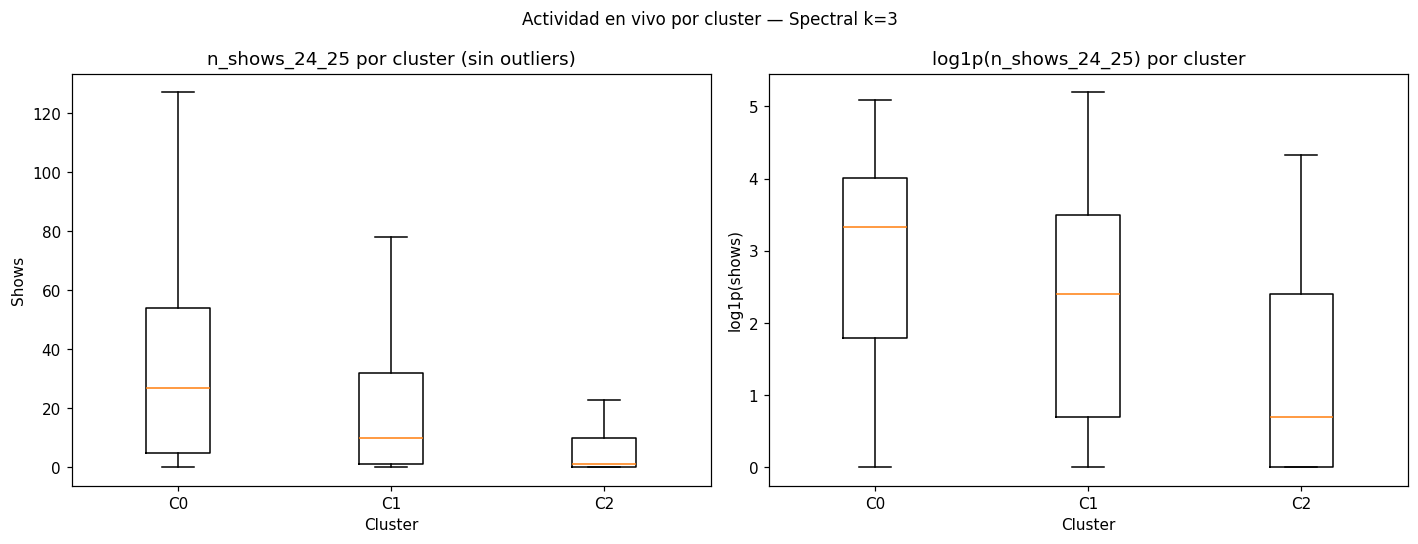

In [59]:
# Boxplot shows por cluster
cluster_ids = sorted(df_live['cluster'].unique())
data_plot   = [df_live.loc[df_live['cluster']==c, 'n_shows_24_25'].values
               for c in cluster_ids]
labels_plot = [f'C{c}' for c in cluster_ids]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].boxplot(data_plot, labels=labels_plot, showfliers=False)
axes[0].set_title('n_shows_24_25 por cluster (sin outliers)')
axes[0].set_xlabel('Cluster'); axes[0].set_ylabel('Shows')

axes[1].boxplot([np.log1p(d) for d in data_plot],
                labels=labels_plot, showfliers=False)
axes[1].set_title('log1p(n_shows_24_25) por cluster')
axes[1].set_xlabel('Cluster'); axes[1].set_ylabel('log1p(shows)')

plt.suptitle(f'Actividad en vivo por cluster — {BM} k={BK}', fontsize=11)

ruta_boxplot_spectral = (
    directorio_salidas_proyecto /
    "spectral3_boxplot_live.png"
)

plt.savefig(
    ruta_boxplot_spectral,
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout(); plt.show()

In [60]:
# === Reproducir ambos modelos ===
# print("K-Medoids k=3...")
# km3_labels, _ = kmedoids_fit(D, 3, n_init=5, max_iter=100)
# print(f"  sizes: {dict(zip(*np.unique(km3_labels, return_counts=True)))}")

print("Spectral k=3...")
sp3_labels = SpectralClustering(
    n_clusters=3, affinity='nearest_neighbors', n_neighbors=30,
    assign_labels='kmeans', n_init=10, random_state=SEED, n_jobs=-1
).fit_predict(X_sc.values)
print(f"  sizes: {dict(zip(*np.unique(sp3_labels, return_counts=True)))}")

# Etiquetas canonicas (reordenadas por mediana de shows para interpretación consistente)
df_full = df_imp.copy()
#df_full['km3_raw'] = km3_labels
df_full['sp3_raw'] = sp3_labels
df_full['n_shows_24_25'] = df['n_shows_24_25'].values

for raw_col, final_col in [('sp3_raw','sp3')]:
    med_shows = (df_full[df_full['n_shows_24_25'].notna()]
                 .groupby(raw_col)['n_shows_24_25'].median()
                 .sort_values(ascending=False))
    remap = {old: new for new, old in enumerate(med_shows.index)}
    df_full[final_col] = df_full[raw_col].map(remap)

# Adjuntar metadatos
for col in ['genre_short','country_short','pronoun_short','major_record_label','band']:
    df_full[col] = df[col].values

#km3 = df_full['km3'].values
sp3 = df_full['sp3'].values
#print("\nKM3 clusters (ordenados por shows desc):", dict(zip(*np.unique(km3, return_counts=True))))
print("SP3 clusters (ordenados por shows desc):", dict(zip(*np.unique(sp3, return_counts=True))))

Spectral k=3...


  sizes: {np.int32(0): np.int64(1012), np.int32(1): np.int64(5680), np.int32(2): np.int64(308)}
SP3 clusters (ordenados por shows desc): {np.int64(0): np.int64(1012), np.int64(1): np.int64(5680), np.int64(2): np.int64(308)}


In [61]:
# === Tabla resumen completa por cluster y modelo ===
df_log2 = df_imp[BASE_COLS].apply(np.log1p).copy()
sp_a = df_log2['sp_monthly_listeners'] + 1e-6
df_log2['social_sp_ratio'] = df_log2['ins_followers'] / sp_a
df_log2['tiktok_sp_ratio'] = df_log2['tiktok_top_video_comments'] / sp_a

rows_sum = []
for model_name, labels in [('Spectral k=3', sp3)]:
    for c in sorted(np.unique(labels)):
        mask      = labels == c
        g         = df_full[mask]
        g_log     = df_log2[mask]
        g_live    = g[g['n_shows_24_25'].notna()]
        shows     = g_live['n_shows_24_25']
        rows_sum.append({
            'modelo':      model_name,
            'cluster':     f'C{c}',
            'n':           mask.sum(),
            'pct_total':   round(100*mask.sum()/7000, 1),
            'major_%':     round(100*g['major_record_label'].mean(), 1),
            'band_%':      round(100*g['band'].mean(), 1),
            'n_live':      len(g_live),
            'pct_zero_shows': round(100*(shows==0).mean(), 1),
            'med_shows':   shows.median(),
            'p75_shows':   shows.quantile(.75),
            'p90_shows':   shows.quantile(.90),
            'sp_monthly_listeners_med':  round(g_log['sp_monthly_listeners'].median(), 2),
            'pandora_streams_med':     round(g_log['pandora_lifetime_streams'].median(), 2),
            'ins_followers_med':         round(g_log['ins_followers'].median(), 2),
            'ycs_views_med':         round(g_log['ycs_views'].median(), 2),
            'ins_sp_ratio_med':round(g_log['social_sp_ratio'].median(), 2),
        })

summary_df = pd.DataFrame(rows_sum)
print(summary_df.to_string(index=False))

      modelo cluster    n  pct_total  major_%  band_%  n_live  pct_zero_shows  med_shows  p75_shows  p90_shows  sp_monthly_listeners_med  pandora_streams_med  ins_followers_med  ycs_views_med  ins_sp_ratio_med
Spectral k=3      C0 1012       14.5     50.7    26.3     926            11.6       27.0       54.0       79.0                     16.54                20.60              15.23          21.61              0.92
Spectral k=3      C1 5680       81.1     23.1    29.7    3938            18.6       10.0       32.0       64.0                     14.86                16.39              13.22          19.57              0.88
Spectral k=3      C2  308        4.4      5.5    21.1      49            38.8        1.0       10.0       19.8                      9.89                 0.00              13.79          19.72              1.46


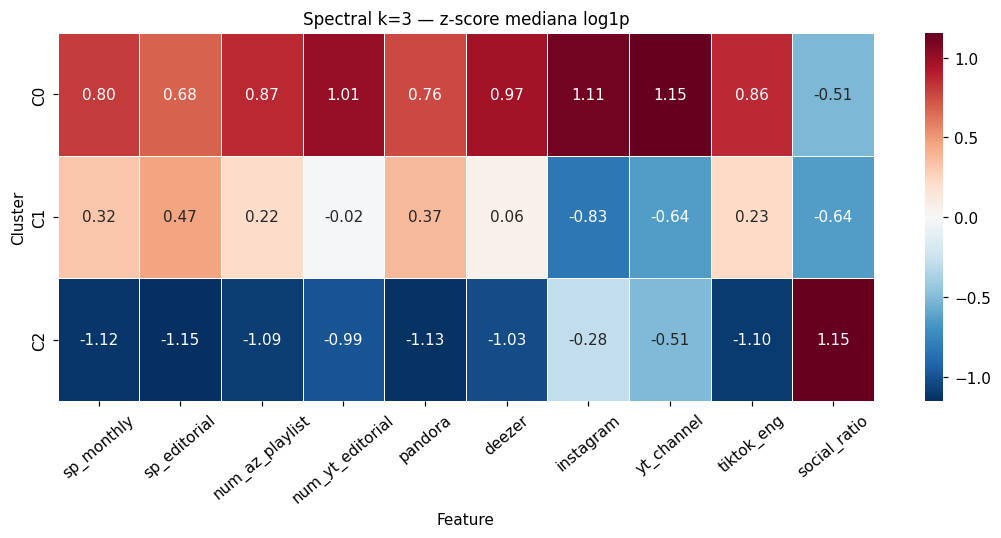

In [62]:
# === Heatmap z-score único panel ===
PLOT_FEATS = BASE_COLS + ['social_sp_ratio']   # 10 features legibles
FEAT_LABELS = ['sp_monthly', 'sp_editorial', 'num_az_playlist',
               'num_yt_editorial', 'pandora', 'deezer',
               'instagram', 'yt_channel', 'tiktok_eng', 'social_ratio']

# Definimos un solo ax (sin desempaquetar una lista)
fig, ax = plt.subplots(1, 1, figsize=(10, 5))  # Ajusté el ancho de 18 a 10 ya que es un solo panel

# Definimos directamente el modelo y sus etiquetas
model_name = 'Spectral k=3'
labels = sp3

# Cálculo del perfil
prof = {}
for c in sorted(np.unique(labels)):
    prof[f'C{c}'] = df_log2[labels == c][PLOT_FEATS].median().values

prof_df = pd.DataFrame(prof, index=FEAT_LABELS).T
prof_z  = prof_df.sub(prof_df.mean()).div(prof_df.std() + 1e-9)

# Dibujar el heatmap en el único ax disponible
sns.heatmap(prof_z, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, linewidths=0.4, ax=ax, cbar=True)

ax.set_title(f'{model_name} — z-score mediana log1p', fontsize=11)
ax.set_xlabel('Feature')
ax.set_ylabel('Cluster')
ax.tick_params(axis='x', rotation=40)

plt.tight_layout()
plt.show()

# radial

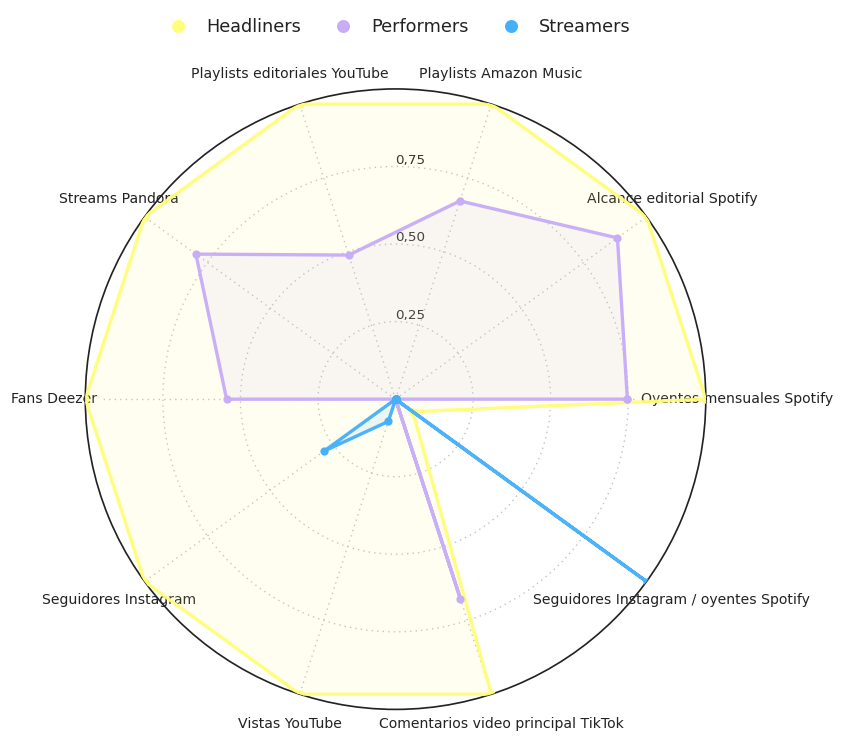

WindowsPath('C:/Users/Silvana/Documents/Maestria_Exactas/taller_tesis_1/music_industry_social_live_code/graficos/spectral3_radial.png')

In [63]:
# ============================================================
# Radar / spider chart
# Perfil digital por cluster, Spectral k=3
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Título general comentado para el informe
# Perfil digital por cluster, normalización min-max por variable
# ------------------------------------------------------------

# ------------------------------------------------------------
# Estética general del informe
# ------------------------------------------------------------

color_texto = "#222222"
color_grilla = "#BDBDBD"
color_fondo = "#FFFFFF"

plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Variables reales usadas en el radar
# ------------------------------------------------------------

PLOT_FEATS = BASE_COLS + ["social_sp_ratio"]

# ------------------------------------------------------------
# Etiquetas visuales para el gráfico
# ------------------------------------------------------------

radar_labels = {
    "sp_followers": "Seguidores Spotify",
    "sp_monthly_listeners": "Oyentes mensuales Spotify",
    "sp_popularity": "Popularidad Spotify",
    "sp_playlist_total_reach": "Alcance playlists Spotify",
    "num_sp_playlists": "Playlists Spotify",
    "num_sp_editorial_playlists": "Playlists editoriales Spotify",
    "sp_editorial_playlist_total_reach": "Alcance editorial Spotify",
    "num_am_playlists": "Playlists Apple Music",
    "num_am_editorial_playlists": "Playlists editoriales Apple Music",
    "num_de_playlists": "Playlists Deezer",
    "num_de_editorial_playlists": "Playlists editoriales Deezer",
    "de_playlist_total_reach": "Alcance playlists Deezer",
    "de_editorial_playlist_total_reach": "Alcance editorial Deezer",
    "num_az_playlists": "Playlists Amazon Music",
    "num_az_editorial_playlists": "Playlists editoriales Amazon Music",
    "num_yt_playlists": "Playlists YouTube",
    "num_yt_editorial_playlists": "Playlists editoriales YouTube",
    "yt_playlist_total_reach": "Alcance playlists YouTube",
    "ins_followers": "Seguidores Instagram",
    "twitter_followers": "Seguidores Twitter/X",
    "tiktok_followers": "Seguidores TikTok",
    "tiktok_likes": "Likes TikTok",
    "tiktok_top_video_views": "Vistas video principal TikTok",
    "tiktok_top_video_comments": "Comentarios video principal TikTok",
    "tiktok_track_posts": "Posts con tracks en TikTok",
    "ycs_subscribers": "Suscriptores YouTube",
    "ycs_views": "Vistas YouTube",
    "youtube_daily_video_views": "Vistas diarias YouTube",
    "youtube_monthly_video_views": "Vistas mensuales YouTube",
    "deezer_fans": "Fans Deezer",
    "shazam_count": "Conteos Shazam",
    "pandora_lifetime_streams": "Streams Pandora",
    "pandora_lifetime_stations_added": "Estaciones agregadas Pandora",
    "social_sp_ratio": "Seguidores Instagram / oyentes Spotify"
}

RADAR_FEATS = PLOT_FEATS
RADAR_LABELS = [
    radar_labels.get(feat, feat.replace("_", " "))
    for feat in RADAR_FEATS
]

N_FEAT = len(RADAR_FEATS)

angles = np.linspace(0, 2 * np.pi, N_FEAT, endpoint=False).tolist()
angles += angles[:1]

# ------------------------------------------------------------
# Nombres y colores por cluster
# Colores distintos de la paleta usada para dimensiones
# ------------------------------------------------------------

cluster_names = {
    0: "Headliners",
    1: "Performers",
    2: "Streamers"
}

cluster_colors = {
    0: "#0B6E69",
    1: "#6C5B7B",
    2: "#C65D3A"
}

cluster_colors = {
    0: "#FFFD79",
    1: "#C7ACF7",
    2: "#45AFFA"
}

# ------------------------------------------------------------
# Panel polar
# ------------------------------------------------------------

fig, ax = plt.subplots(
    1,
    1,
    figsize=(8.9, 6.8),
    subplot_kw=dict(polar=True),
    facecolor=color_fondo
)

ax.set_facecolor(color_fondo)

labels = sp3

# ------------------------------------------------------------
# Perfil mediano por cluster
# ------------------------------------------------------------

prof = {}

for c in sorted(np.unique(labels)):
    prof[c] = (
        df_log2
        .loc[labels == c, PLOT_FEATS]
        .apply(lambda s: np.asarray(s, dtype="float64"))
        .median()
        .values
    )

prof_arr = np.array([
    prof[c]
    for c in sorted(prof)
], dtype="float64")

# ------------------------------------------------------------
# Normalización min-max por variable entre clusters
# ------------------------------------------------------------

mn = np.nanmin(prof_arr, axis=0)
mx = np.nanmax(prof_arr, axis=0)

prof_norm = (prof_arr - mn) / (mx - mn + 1e-9)

# ------------------------------------------------------------
# Gráfico de clusters
# ------------------------------------------------------------

for i, c in enumerate(sorted(np.unique(labels))):
    
    vals = prof_norm[i].tolist()
    vals += vals[:1]
    
    ax.plot(
        angles,
        vals,
        marker="o",
        markersize=4.4,
        color=cluster_colors[c],
        linewidth=2.2,
        alpha=0.95,
        label=cluster_names[c],
        zorder=3
    )
    
    ax.fill(
        angles,
        vals,
        alpha=0.10,
        color=cluster_colors[c],
        zorder=2
    )

# ------------------------------------------------------------
# Configuración visual
# ------------------------------------------------------------

ax.set_xticks(angles[:-1])
ax.set_xticklabels(RADAR_LABELS)

for label in ax.get_xticklabels():
    label.set_fontsize(9.2)
    label.set_color(color_texto)
    label.set_zorder(20)
    label.set_bbox(
        dict(
            facecolor=color_fondo,
            edgecolor="none",
            alpha=1.0,
            pad=2.4
        )
    )

# Más separación entre el borde del radar y las etiquetas
ax.tick_params(
    axis="x",
    pad=10,
    colors=color_texto
)

ax.set_ylim(0, 1)

ax.set_yticks([0.25, 0.5, 0.75])
ax.set_yticklabels(
    ["0,25", "0,50", "0,75"],
    fontsize=8.8,
    color=color_texto
)

ax.tick_params(
    axis="y",
    colors=color_texto,
    length=0
)

# Ubica las etiquetas radiales lejos de la zona más cargada
ax.set_rlabel_position(90)

ax.grid(
    color=color_grilla,
    linestyle=(0, (1, 3)),
    linewidth=0.9,
    alpha=0.95,
    zorder=0
)

ax.spines["polar"].set_color(color_texto)
ax.spines["polar"].set_linewidth(1.1)

# ------------------------------------------------------------
# Leyenda superior izquierda con círculos, sin caja
# Siempre en un solo renglón
# ------------------------------------------------------------

legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=cluster_colors[c],
        markeredgecolor="none",
        markersize=8.5,
        label=cluster_names[c]
    )
    for c in sorted(np.unique(labels))
]

# ax.legend(
#     handles=legend_elements,
#     loc="upper left",
#     bbox_to_anchor=(-0.12, 1.14),
#     frameon=False,
#     fontsize=11.5,
#     handletextpad=0.6,
#     columnspacing=1.4,
#     labelcolor=color_texto,
#     ncol=3
# )

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.14),
    frameon=False,
    fontsize=11.5,
    handletextpad=0.6,
    columnspacing=1.4,
    labelcolor=color_texto,
    ncol=3
)

# ------------------------------------------------------------
# Títulos apagados para mantener criterio visual del informe
# ------------------------------------------------------------

# ax.set_title(
#     "Spectral k=3",
#     pad=18,
#     fontsize=13,
#     color=color_texto
# )

# fig.suptitle(
#     "Perfil digital por cluster, normalización min-max por variable",
#     y=1.02,
#     fontsize=15,
#     color=color_texto
# )

plt.tight_layout()

# ------------------------------------------------------------
# Guardado
# ------------------------------------------------------------

ruta_radial = (
    directorio_salidas_proyecto /
    "spectral3_radial.png"
)

fig.savefig(
    ruta_radial,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

ruta_radial

# violines 

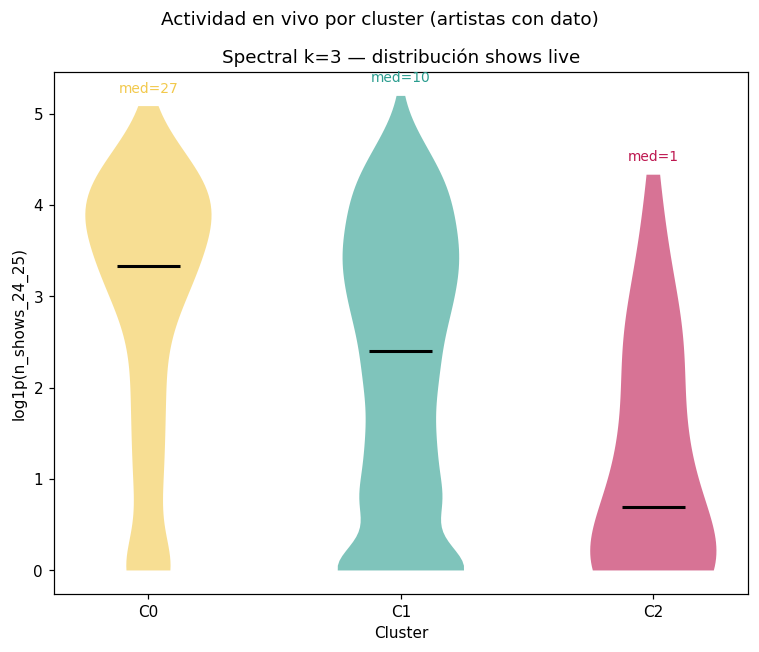


Spectral k=3:
  C0 n= 926  zero=11.6%  >10shows=68.9%  >50shows=27.9%  med=  27  p90=  79
  C1 n=3938  zero=18.6%  >10shows=48.9%  >50shows=15.3%  med=  10  p90=  64
  C2 n=  49  zero=38.8%  >10shows=16.3%  >50shows= 2.0%  med=   1  p90=  20


In [64]:
# === Actividad en vivo: violins — Solo Spectral ===
# 1. Creamos un único panel
fig, ax = plt.subplots(1, 1, figsize=(7, 6))

# 2. Definimos directamente Spectral
model_name = 'Spectral k=3'
labels = sp3

# Asignamos etiquetas al DataFrame principal
df_full['_labels'] = labels
live_data = df_full[df_full['n_shows_24_25'].notna()].copy()
live_data['log_shows'] = np.log1p(live_data['n_shows_24_25'])
cluster_ids = sorted(live_data['_labels'].unique())

# Gráfico de violín en el único ax disponible
parts = ax.violinplot(
    [live_data.loc[live_data['_labels'] == c, 'log_shows'].values for c in cluster_ids],
    positions=cluster_ids, showmedians=True, showextrema=False
)

for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(COLORS[i % 3])
    pc.set_alpha(0.6)
parts['cmedians'].set_color('black')
parts['cmedians'].set_linewidth(2)

# Overlay median text
for c in cluster_ids:
    med = live_data.loc[live_data['_labels'] == c, 'n_shows_24_25'].median()
    ax.text(c, live_data.loc[live_data['_labels'] == c, 'log_shows'].max() + 0.15,
            f'med={med:.0f}', ha='center', fontsize=9, color=COLORS[c % 3])

ax.set_xticks(cluster_ids)
ax.set_xticklabels([f'C{c}' for c in cluster_ids])
ax.set_xlabel('Cluster')
ax.set_ylabel('log1p(n_shows_24_25)')
ax.set_title(f'{model_name} — distribución shows live')

plt.suptitle('Actividad en vivo por cluster (artistas con dato)', fontsize=12)
plt.tight_layout()

ruta_violines_spectral3 = (
    directorio_salidas_proyecto /
    "spectral3_violinesvivo.png"
)

plt.savefig(
    ruta_violines_spectral3,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# === Tabla complementaria: % sin shows y % con >50 shows (Solo Spectral) ===
print(f"\n{model_name}:")
for c in sorted(live_data['_labels'].unique()):
    g = live_data.loc[live_data['_labels'] == c, 'n_shows_24_25']
    print(f"  C{c} n={len(g):4d}  zero={100*(g==0).mean():4.1f}%  "
          f">10shows={100*(g>10).mean():4.1f}%  >50shows={100*(g>50).mean():4.1f}%  "
          f"med={g.median():4.0f}  p90={g.quantile(.9):4.0f}")

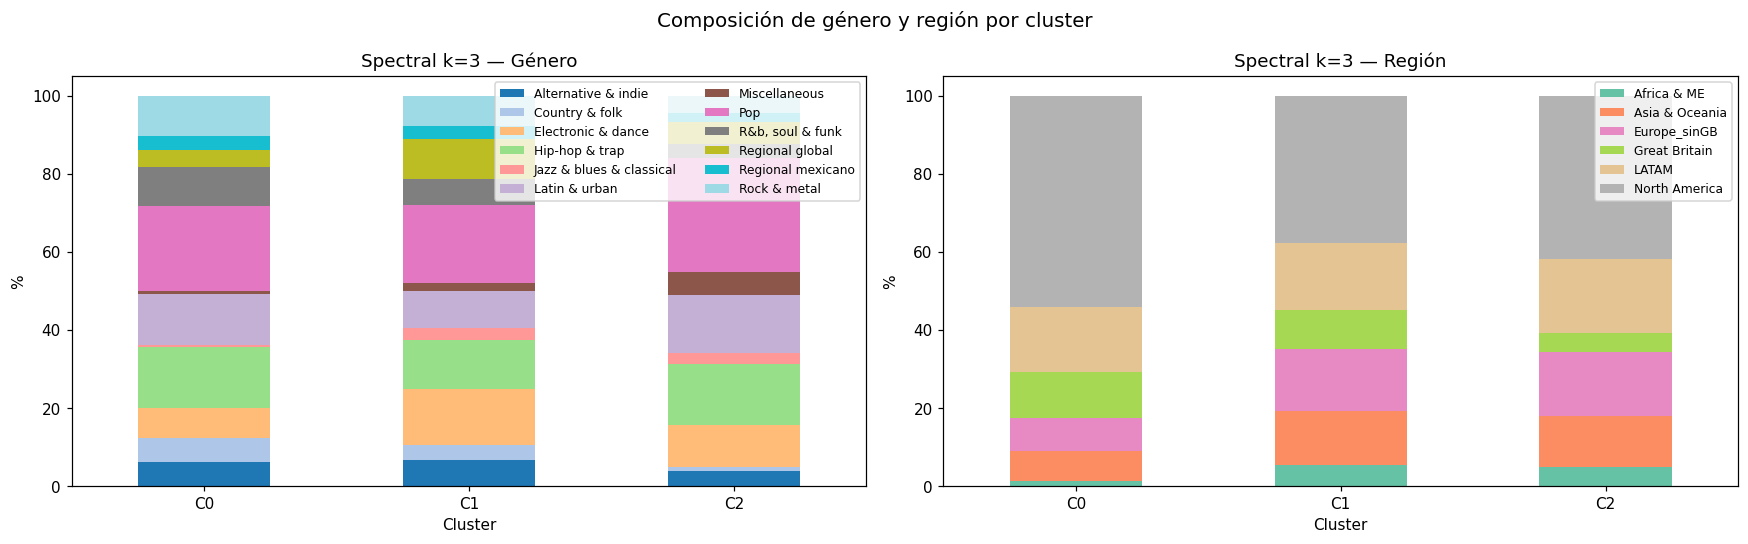

In [65]:
# === Composición por género y región — Solo Spectral ===
# 1. Pasamos a una sola fila con dos columnas (Género a la izquierda, Región a la derecha)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 2. Definimos directamente Spectral
model_name = 'Spectral k=3'
labels = sp3
df_full['_labels'] = labels

# --- Gráfico 1: Género ---
g_ct = (pd.crosstab(df_full['_labels'], df_full['genre_short'], normalize='index') * 100)
g_ct.index = [f'C{i}' for i in g_ct.index]

# Graficamos en el primer panel axes[0]
g_ct.plot(kind='bar', stacked=True, ax=axes[0], colormap='tab20', legend=True)
axes[0].set_title(f'{model_name} — Género')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('%')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(loc='upper right', fontsize=8, ncol=2)

# --- Gráfico 2: Región ---
r_ct = (pd.crosstab(df_full['_labels'], df_full['country_short'], normalize='index') * 100)
r_ct.index = [f'C{i}' for i in r_ct.index]

# Graficamos en el segundo panel axes[1]
r_ct.plot(kind='bar', stacked=True, ax=axes[1], colormap='Set2', legend=True)
axes[1].set_title(f'{model_name} — Región')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('%')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(loc='upper right', fontsize=8)

plt.suptitle('Composición de género y región por cluster', fontsize=13)
plt.tight_layout()
plt.show()

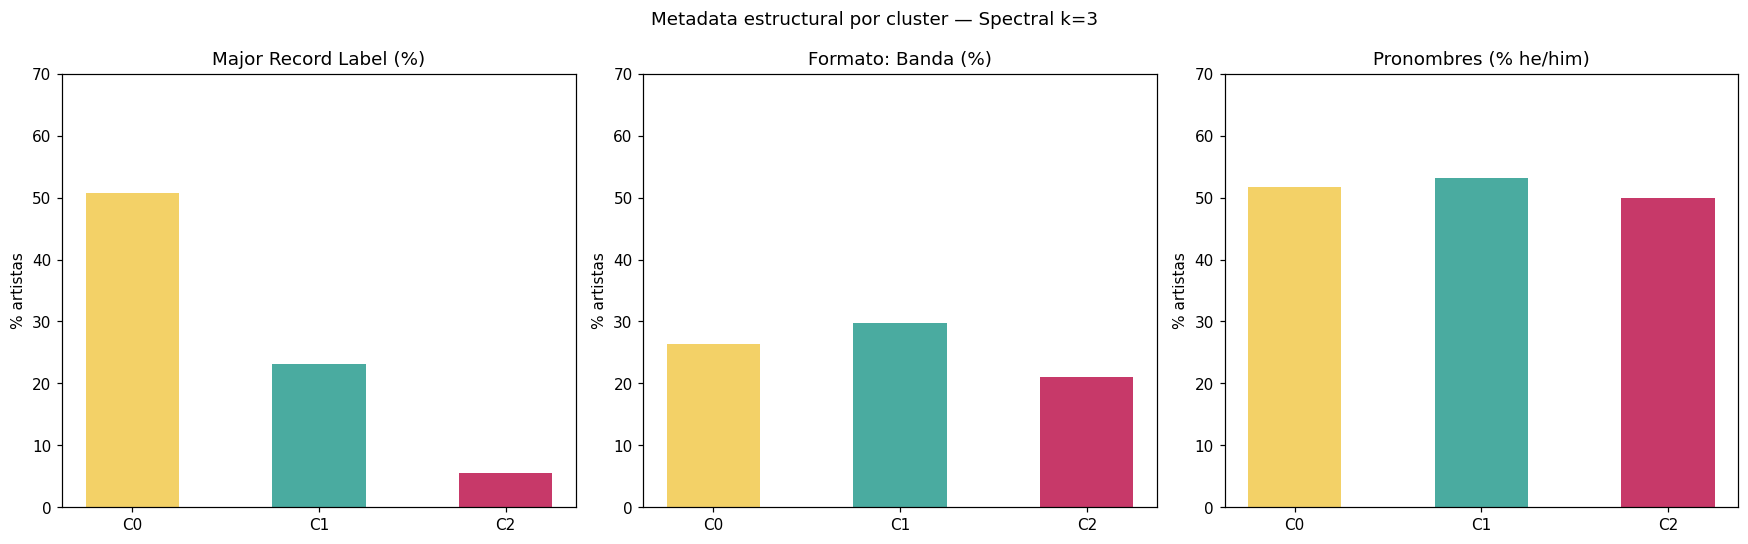


Distribución de pronombres por cluster (%) — Spectral k=3:
major_record_label  False  True 
C0                   49.3   50.7
C1                   76.9   23.1
C2                   94.5    5.5


In [66]:
# === Major label, banda/solista y pronombres — Solo Spectral ===
# Mantenemos los 3 paneles en una fila
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Definimos directamente Spectral y sus variables
model_name = 'Spectral k=3'
labels = sp3
df_full['_labels'] = labels

x = np.arange(3)   # 3 clusters (C0, C1, C2)

# Iteramos sobre los 3 paneles (ejes) y sus respectivas configuraciones
for ax, var, title, ylab in zip(
        axes,
        ['major_record_label', 'band', 'pronoun_short'],
        ['Major Record Label (%)', 'Formato: Banda (%)', 'Pronombres (% he/him)'],
        ['% artistas', '% artistas', '% artistas']):

    vals = []
    for c in sorted(np.unique(labels)):
        g = df_full[df_full['_labels'] == c]
        if var == 'pronoun_short':
            vals.append(100 * (g[var] == 'he/him').mean())
        else:
            vals.append(100 * g[var].mean())
            
    # Graficamos las barras directamente en x (sin offsets). 
    # Usamos COLORS para mantener la identidad de cada cluster (C0, C1, C2)
    ax.bar(x, vals, width=0.5, color=COLORS, alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(['C0', 'C1', 'C2'])
    ax.set_title(title)
    ax.set_ylabel(ylab)
    ax.set_ylim(0, 70)

plt.suptitle(f'Metadata estructural por cluster — {model_name}', fontsize=12)
plt.tight_layout()

ruta_spectral3_bandpronounlabel = (
    directorio_salidas_proyecto /
    "spectral3_bandpronounlabel.png"
)

plt.savefig(
    ruta_spectral3_bandpronounlabel,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# === Tabla de pronombres completa (Solo Spectral) ===
print(f"\nDistribución de pronombres por cluster (%) — {model_name}:")
ct = (pd.crosstab(df_full['_labels'], df_full['major_record_label'], normalize='index') * 100).round(1)
ct.index = [f'C{i}' for i in ct.index]
print(ct.to_string())




In [67]:
# ============================================================
# Búsqueda de tablas de métricas internas en memoria
# ============================================================

tablas_metricas_candidatas = []

objetos_en_memoria = list(globals().items())

for nombre_objeto, objeto in objetos_en_memoria:
    
    if isinstance(objeto, pd.DataFrame):
        
        columnas_texto = " ".join([str(col).lower() for col in objeto.columns])
        
        contiene_metricas = any(
            palabra in columnas_texto
            for palabra in ["silhouette", "davies", "calinski", "db", "ch", "bic", "aic", "ari"]
        )
        
        contiene_modelo = any(
            palabra in columnas_texto
            for palabra in ["modelo", "method", "cluster", "k", "n_clusters"]
        )
        
        if contiene_metricas or contiene_modelo:
            tablas_metricas_candidatas.append({
                "objeto": nombre_objeto,
                "shape": objeto.shape,
                "columnas": list(objeto.columns)
            })

tabla_objetos_metricas_candidatos = pd.DataFrame(tablas_metricas_candidatas)

display(tabla_objetos_metricas_candidatos)

,objeto,shape,columnas
0,__,"(5, 5)","[chartmetric_id, artist_name, kmedoids_cluster..."
1,df,"(7000, 53)","[chartmetric_id, artist_name, country, pronoun..."
2,df_imp,"(7000, 53)","[chartmetric_id, artist_name, country, pronoun..."
3,df_log,"(7000, 12)","[sp_monthly_listeners, sp_editorial_playlist_t..."
4,X_sc,"(7000, 11)","[sp_monthly_listeners, sp_editorial_playlist_t..."
5,_10,"(8, 11)","[sp_monthly_listeners, sp_editorial_playlist_t..."
6,_13,"(2, 2)","[log_ins_sp_ratio, log_tiktok_sp_ratio]"
7,corr_mat,"(11, 11)","[sp_monthly_listeners, sp_editorial_playlist_t..."
8,tabla_sil_cluster,"(3, 5)","[n_artistas, silhouette_media, silhouette_medi..."
9,_26,"(7, 5)","[n_artistas, silhouette_media, silhouette_medi..."


In [68]:
# ============================================================
# Búsqueda automática de métricas internas de soluciones Spectral
# ============================================================

resultados_metricas_spectral = []

objetos_en_memoria = list(globals().items())

for nombre_objeto, objeto in objetos_en_memoria:
    
    # Se omiten tablas generadas por esta misma celda (evita error al re-ejecutar)
    if isinstance(objeto, pd.DataFrame) and "objeto_origen" not in objeto.columns:
        
        columnas_texto = " ".join([str(col).lower() for col in objeto.columns])
        
        contiene_metricas = any(
            palabra in columnas_texto
            for palabra in ["silhouette", "davies", "calinski", "db", "ch", "bic", "aic", "ari"]
        )
        
        if contiene_metricas:
            
            mascara_spectral = (
                objeto
                .astype(str)
                .apply(
                    lambda fila: fila.str.contains("Spectral", case=False, regex=False).any(),
                    axis=1
                )
            )
            
            if mascara_spectral.sum() > 0:
                
                tabla_filtrada = objeto.loc[mascara_spectral].copy()
                tabla_filtrada.insert(0, "objeto_origen", nombre_objeto)
                
                resultados_metricas_spectral.append(tabla_filtrada)

if len(resultados_metricas_spectral) == 0:
    print("No se encontraron filas con Spectral en tablas de métricas internas.")
else:
    tabla_metricas_spectral_encontradas = pd.concat(
        resultados_metricas_spectral,
        ignore_index=True
    )
    
    display(tabla_metricas_spectral_encontradas)

,objeto_origen,metodo_a,metodo_b,ARI,method,k,silhouette,davies_bouldin,calinski_harabasz,min_cluster_%,usable
0,comparacion_global,K-Medoids k=2,Spectral k=2,0.052275,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,comparacion_global,GMM full k=2,Spectral k=2,0.170953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,_45,K-Medoids k=2,Spectral k=2,0.052000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,_45,GMM full k=2,Spectral k=2,0.171000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,cmp_df,NaN,NaN,NaN,Spectral,2.0,0.5305,1.0366,1677.5,5.0,True
5,cmp_df,NaN,NaN,NaN,Spectral,3.0,0.1674,1.2356,1490.3,4.4,True
6,cmp_df,NaN,NaN,NaN,Spectral,4.0,0.1109,1.2067,1084.5,4.4,False
7,cmp_df,NaN,NaN,NaN,Spectral,5.0,0.1212,1.1140,935.0,0.9,False
8,cmp_df,NaN,NaN,NaN,Spectral,6.0,0.1126,1.4496,1013.3,0.9,False
9,cmp_df,NaN,NaN,NaN,Spectral,7.0,0.1048,1.4253,1005.2,0.9,False


# PRUEBAS — visualizaciones alternativas al UMAP Spectral k=3

Capítulo exploratorio, para decidir si se conserva. Objetivo: mostrar el k=3 como **zonas de un continuo**, no como grupos separados.

- Todas las proyecciones usan `X_sc`, la misma matriz sobre la que se ajustó el Spectral. Se eliminó el UMAP anterior porque se calculaba sobre otra matriz (otra imputación y otra construcción de ratios).
- Grilla explorada fuera de la notebook: t-SNE (perplexity 30, 150, 500) y UMAP (n_neighbors 15, 100, 300 × min_dist 0.1, 0.8). En **todas** las configuraciones, y también en las dos hebras del embedding espectral, Headliners aparece en dos zonas: son dos submodos reales del perfil, no un artefacto de UMAP. Solo con configuraciones que priorizan estructura global (UMAP manhattan n_neighbors=100; UMAP n_neighbors=500) aparece como una única zona continua.
- Descartada: LDA (proyección supervisada que exagera la separación).


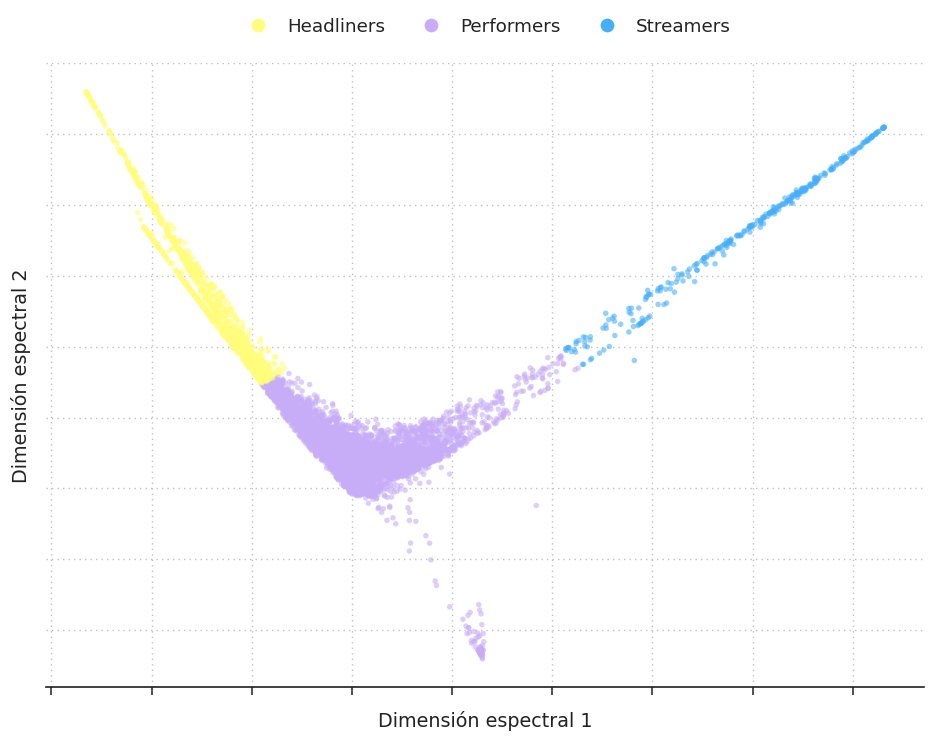

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\embedding_espectral_k3_perfiles.png


In [69]:
# ============================================================
# PRUEBA 1 | Embedding espectral de perfiles Spectral k=3
# Espacio en el que el propio algoritmo asigna los clusters
# (mismo grafo kNN=30 que SpectralClustering; Belkin & Niyogi, 2003)
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.neighbors import kneighbors_graph
from sklearn.manifold import spectral_embedding

color_texto = "#222222"
color_grilla = "#BDBDBD"
color_fondo = "#FFFFFF"

plt.rcParams["font.family"] = "DejaVu Sans"

palette_sp3_new = {
    "Headliners": "#FFFD79",
    "Performers": "#C7ACF7",
    "Streamers": "#45AFFA"
}

orden_perfiles = ["Headliners", "Performers", "Streamers"]
orden_capas = ["Performers", "Headliners", "Streamers"]  # mayoritario debajo

mapa_perfiles_sp3 = {0: "Headliners", 1: "Performers", 2: "Streamers"}
perfil_sp3 = df_full["sp3"].map(mapa_perfiles_sp3).values

# ------------------------------------------------------------
# Embedding: mismo grafo que SpectralClustering(affinity="nearest_neighbors", n_neighbors=30)
# ------------------------------------------------------------

grafo_knn_sp3 = kneighbors_graph(X_sc.values, n_neighbors=30, include_self=True)
grafo_knn_sp3 = 0.5 * (grafo_knn_sp3 + grafo_knn_sp3.T)

embedding_espectral_sp3 = spectral_embedding(
    grafo_knn_sp3,
    n_components=3,
    drop_first=False,
    random_state=SEED
)

# El primer autovector es casi constante; se grafican el 2 y el 3
coords_espectral_sp3 = embedding_espectral_sp3[:, 1:3]

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.6, 6.8), facecolor=color_fondo)
ax.set_facecolor(color_fondo)

for perfil in orden_capas:
    mascara = perfil_sp3 == perfil
    ax.scatter(
        coords_espectral_sp3[mascara, 0],
        coords_espectral_sp3[mascara, 1],
        s=13,
        alpha=0.58,
        color=palette_sp3_new[perfil],
        edgecolors="none",
        rasterized=True
    )

ax.set_xlabel("Dimensión espectral 1", fontsize=12.5, color=color_texto, labelpad=10)
ax.set_ylabel("Dimensión espectral 2", fontsize=12.5, color=color_texto, labelpad=10)

ax.grid(axis="both", color=color_grilla, linestyle=(0, (1, 3)), linewidth=0.9, alpha=0.95)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color(color_texto)
ax.spines["bottom"].set_linewidth(1.1)

# Escala de los autovectores arbitraria: se ocultan los valores de los ejes
ax.tick_params(axis="x", colors=color_texto, labelbottom=False, length=5, width=1)
ax.tick_params(axis="y", colors=color_texto, labelleft=False, length=0)

legend_elements = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=palette_sp3_new[perfil],
           markeredgecolor="none", markersize=9, label=perfil)
    for perfil in orden_perfiles
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.10),
    frameon=False,
    fontsize=12,
    handletextpad=0.6,
    columnspacing=1.5,
    labelcolor=color_texto,
    ncol=3
)

plt.tight_layout()

ruta_embedding_espectral_k3 = directorio_salidas_proyecto / "embedding_espectral_k3_perfiles.png"

fig.savefig(ruta_embedding_espectral_k3, dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

print("Archivo guardado en:", ruta_embedding_espectral_k3)


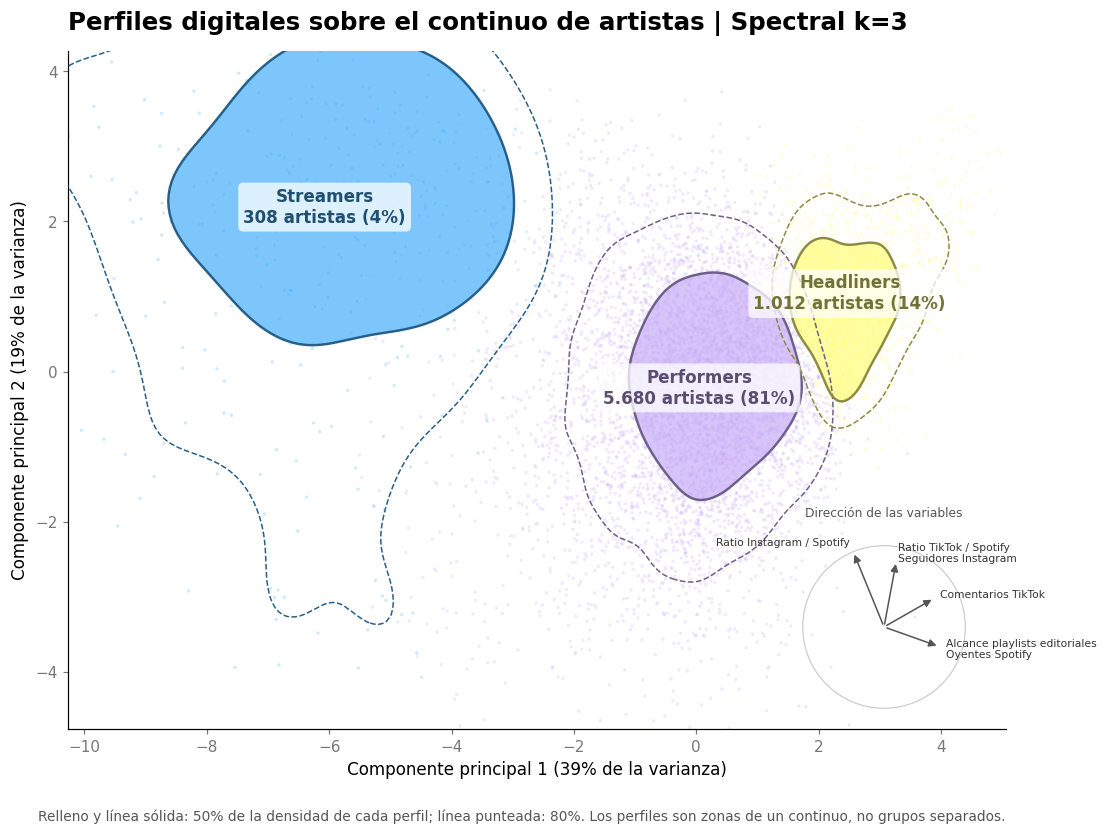

In [70]:
# ============================================================
# PRUEBA 2 | PCA de perfiles Spectral k=3 (versión estética)
# Regiones de densidad por perfil + inset con dirección de variables
# ============================================================

import seaborn as sns
import matplotlib.colors as mcolors
from sklearn.decomposition import PCA

mapa_perfiles_sp3 = {0: "Headliners", 1: "Performers", 2: "Streamers"}
palette_sp3 = {"Headliners": "#FFFD79", "Performers": "#C7ACF7", "Streamers": "#45AFFA"}
orden_capas_sp3 = ["Performers", "Headliners", "Streamers"]
perfil_sp3 = df_full["sp3"].map(mapa_perfiles_sp3).values

# Tono oscuro de cada color, solo para contornos y textos (legibilidad del amarillo)
def oscurecer(color_hex, factor=0.55):
    r, g, b = mcolors.to_rgb(color_hex)
    return (r * factor, g * factor, b * factor)

nombres_legibles_sp3 = {
    "sp_monthly_listeners": "Oyentes Spotify",
    "sp_editorial_playlist_total_reach": "Alcance playlists editoriales",
    "num_az_playlists": "Playlists Amazon",
    "num_yt_editorial_playlists": "Playlists YouTube",
    "pandora_lifetime_streams": "Streams Pandora",
    "deezer_fans": "Fans Deezer",
    "ins_followers": "Seguidores Instagram",
    "ycs_views": "Vistas YouTube",
    "tiktok_top_video_comments": "Comentarios TikTok",
    "log_ins_sp_ratio": "Ratio Instagram / Spotify",
    "log_tiktok_sp_ratio": "Ratio TikTok / Spotify"
}

pca_sp3 = PCA(n_components=2, random_state=SEED).fit(X_sc.values)
coords_pca_sp3 = pca_sp3.transform(X_sc.values)
var_pca_sp3 = pca_sp3.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(11, 8))

for perfil in orden_capas_sp3:
    mascara = perfil_sp3 == perfil
    x_p, y_p = coords_pca_sp3[mascara, 0], coords_pca_sp3[mascara, 1]

    ax.scatter(x_p, y_p, s=5, alpha=0.25, color=palette_sp3[perfil], edgecolors="none", zorder=1)

    # Núcleo: región con el 50% de la densidad del perfil (relleno)
    sns.kdeplot(x=x_p, y=y_p, levels=[0.5, 1], fill=True, alpha=0.7,
                cmap=mcolors.ListedColormap([palette_sp3[perfil]]), ax=ax, zorder=2)
    # Contornos 50% (sólido) y 80% (punteado)
    sns.kdeplot(x=x_p, y=y_p, levels=[0.5], color=oscurecer(palette_sp3[perfil]),
                linewidths=1.6, ax=ax, zorder=3)
    sns.kdeplot(x=x_p, y=y_p, levels=[0.2], color=oscurecer(palette_sp3[perfil]),
                linewidths=1, linestyles="--", ax=ax, zorder=3)

    # Etiqueta directa en la mediana del perfil
    n_p = mascara.sum()
    ax.text(np.median(x_p), np.median(y_p),
            f"{perfil}\n{n_p:,} artistas ({n_p / len(perfil_sp3):.0%})".replace(",", "."),
            ha="center", va="center", fontsize=11, fontweight="bold",
            color=oscurecer(palette_sp3[perfil], 0.45), zorder=5,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.75))

# Recorte de ejes al 0.5%-99.5% para evitar espacio vacío
x_lim = np.percentile(coords_pca_sp3[:, 0], [0.2, 99.8])
y_lim = np.percentile(coords_pca_sp3[:, 1], [0.5, 99.5])
ax.set_xlim(x_lim[0] - 0.5, x_lim[1] + 0.5)
ax.set_ylim(y_lim[0] - 0.5, y_lim[1] + 0.5)

ax.set_title("Perfiles digitales sobre el continuo de artistas | Spectral k=3",
             fontsize=16, fontweight="bold", pad=14, loc="left")
ax.set_xlabel(f"Componente principal 1 ({var_pca_sp3[0]:.0f}% de la varianza)", fontsize=11)
ax.set_ylabel(f"Componente principal 2 ({var_pca_sp3[1]:.0f}% de la varianza)", fontsize=11)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(colors="#777777")

# ------------------------------------------------------------
# Inset: dirección de las variables con mayor peso en el plano
# ------------------------------------------------------------

cargas_sp3 = pd.DataFrame(pca_sp3.components_.T, index=X_sc.columns, columns=["PC1", "PC2"])
top_cargas_sp3 = cargas_sp3.pow(2).sum(axis=1).nlargest(6).index

# Variables con dirección casi idéntica (< 12 grados) comparten flecha y etiqueta
angulos_sp3 = np.degrees(np.arctan2(cargas_sp3.loc[top_cargas_sp3, "PC2"], cargas_sp3.loc[top_cargas_sp3, "PC1"]))
grupos_flechas_sp3 = []
for var in angulos_sp3.sort_values().index:
    if grupos_flechas_sp3 and abs(angulos_sp3[var] - angulos_sp3[grupos_flechas_sp3[-1][0]]) < 12:
        grupos_flechas_sp3[-1].append(var)
    else:
        grupos_flechas_sp3.append([var])

ax_in = ax.inset_axes([0.74, 0.0, 0.26, 0.3])
ax_in.set_xlim(-1.25, 1.25)
ax_in.set_ylim(-1.25, 1.25)
ax_in.set_aspect("equal")
ax_in.axis("off")
ax_in.add_patch(plt.Circle((0, 0), 1, fill=False, color="#CCCCCC", lw=0.8))

escala_in = 1 / cargas_sp3.loc[top_cargas_sp3].pow(2).sum(axis=1).pow(0.5).max()

for grupo in grupos_flechas_sp3:
    x_c, y_c = cargas_sp3.loc[grupo].mean() * escala_in
    ax_in.annotate("", xy=(x_c, y_c), xytext=(0, 0),
                   arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1))
    ax_in.text(x_c * 1.12, y_c * 1.12, "\n".join(nombres_legibles_sp3.get(v, v) for v in grupo), fontsize=7,
               color="#333333", ha="left" if x_c >= 0 else "right", va="center")

ax_in.set_title("Dirección de las variables", fontsize=8, color="#555555")

plt.figtext(
    0.5, 0.005,
    "Relleno y línea sólida: 50% de la densidad de cada perfil; línea punteada: 80%. Los perfiles son zonas de un continuo, no grupos separados.",
    ha="center", fontsize=9, color="#555555"
)

plt.savefig(directorio_salidas_proyecto / "prueba_pca_k3_perfiles.png", dpi=300, bbox_inches="tight")
plt.show()


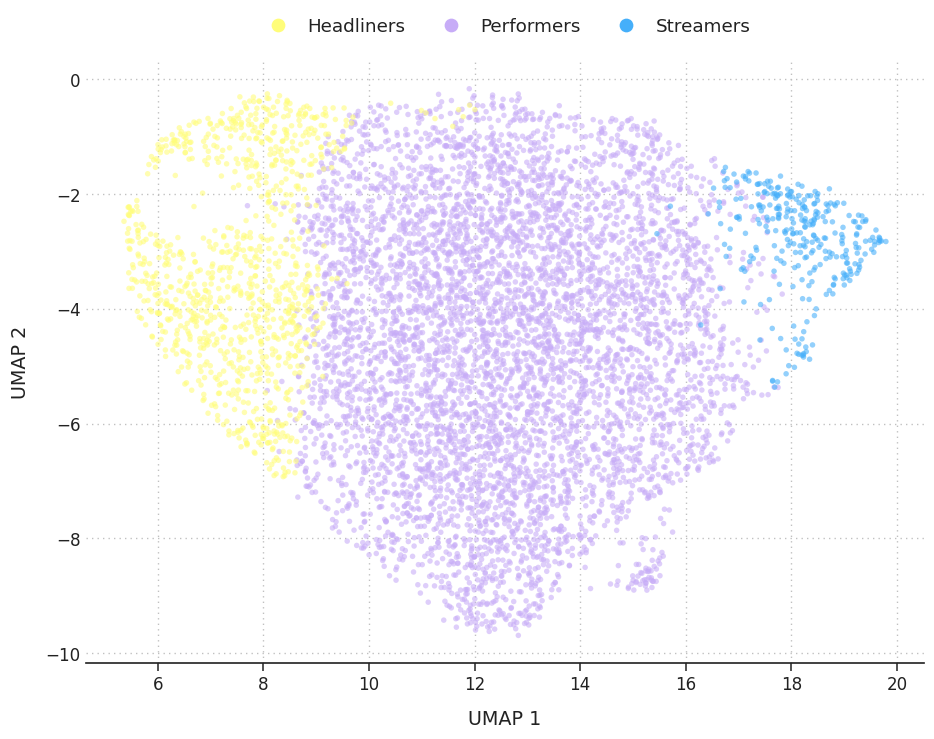

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\umap_spectral_k3_manhattan_nn100.png


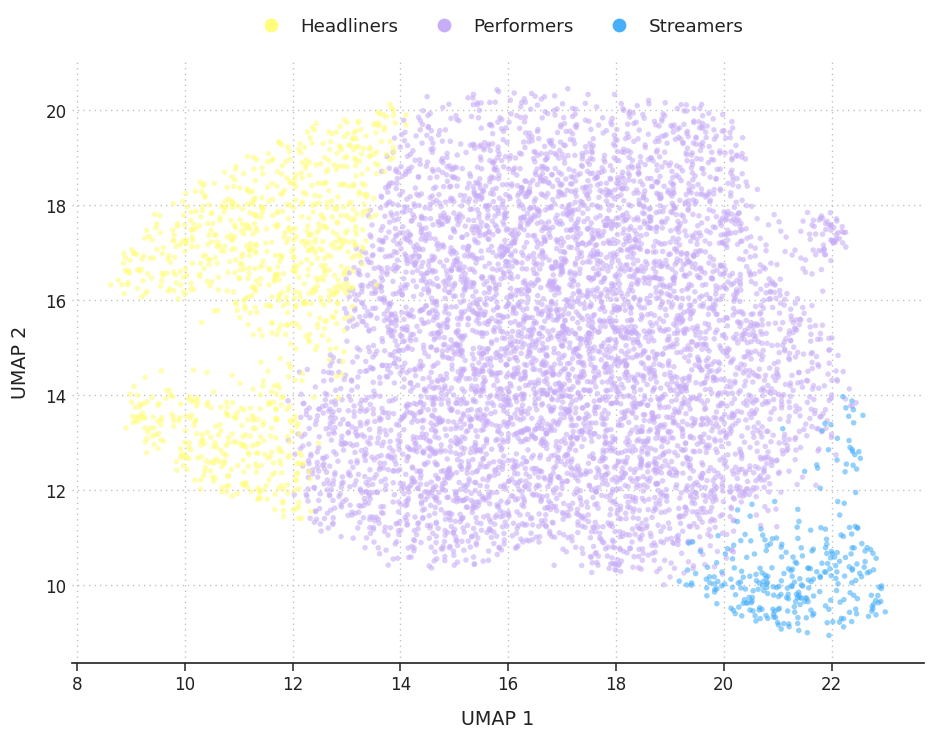

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\umap_spectral_k3_euclidea_nn500.png


In [71]:
# ============================================================
# PRUEBA 3 | UMAP de perfiles Spectral k=3 sobre X_sc
# Configuraciones que priorizan estructura global (Headliners como una sola zona):
#   (a) métrica manhattan, n_neighbors=100, min_dist=0.5
#   (b) métrica euclídea, n_neighbors=500, min_dist=0.8
# Grilla explorada fuera de la notebook: n_neighbors 15-1000, min_dist 0.1-0.99,
# métricas euclídea/manhattan/coseno, densMAP, init=pca, t-SNE perplexity 30-1000
# ============================================================

import umap
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

color_texto = "#222222"
color_grilla = "#BDBDBD"
color_fondo = "#FFFFFF"

plt.rcParams["font.family"] = "DejaVu Sans"

palette_sp3_new = {
    "Headliners": "#FFFD79",
    "Performers": "#C7ACF7",
    "Streamers": "#45AFFA"
}

orden_perfiles = ["Headliners", "Performers", "Streamers"]
orden_capas = ["Performers", "Headliners", "Streamers"]  # mayoritario debajo

mapa_perfiles_sp3 = {0: "Headliners", 1: "Performers", 2: "Streamers"}
perfil_sp3 = df_full["sp3"].map(mapa_perfiles_sp3).values

configuraciones_umap_sp3 = {
    "manhattan_nn100": dict(n_neighbors=100, min_dist=0.5, metric="manhattan"),
    "euclidea_nn500": dict(n_neighbors=500, min_dist=0.8, metric="euclidean")
}


def graficar_umap_sp3(embedding, nombre_archivo):

    fig, ax = plt.subplots(figsize=(8.6, 6.8), facecolor=color_fondo)
    ax.set_facecolor(color_fondo)

    for perfil in orden_capas:
        mascara = perfil_sp3 == perfil
        ax.scatter(
            embedding[mascara, 0],
            embedding[mascara, 1],
            s=13,
            alpha=0.58,
            color=palette_sp3_new[perfil],
            edgecolors="none",
            rasterized=True
        )

    ax.set_xlabel("UMAP 1", fontsize=12.5, color=color_texto, labelpad=10)
    ax.set_ylabel("UMAP 2", fontsize=12.5, color=color_texto, labelpad=10)

    ax.grid(axis="both", color=color_grilla, linestyle=(0, (1, 3)), linewidth=0.9, alpha=0.95)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(color_texto)
    ax.spines["bottom"].set_linewidth(1.1)

    ax.tick_params(axis="x", colors=color_texto, labelsize=11, length=5, width=1)
    ax.tick_params(axis="y", colors=color_texto, labelsize=11, length=0)

    legend_elements = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor=palette_sp3_new[perfil],
               markeredgecolor="none", markersize=9, label=perfil)
        for perfil in orden_perfiles
    ]

    ax.legend(
        handles=legend_elements,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.10),
        frameon=False,
        fontsize=12,
        handletextpad=0.6,
        columnspacing=1.5,
        labelcolor=color_texto,
        ncol=3
    )

    plt.tight_layout()

    ruta = directorio_salidas_proyecto / nombre_archivo
    fig.savefig(ruta, dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()
    print("Archivo guardado en:", ruta)


embeddings_umap_sp3 = {}

for nombre, params in configuraciones_umap_sp3.items():
    embeddings_umap_sp3[nombre] = umap.UMAP(random_state=SEED, **params).fit_transform(X_sc.values)
    graficar_umap_sp3(embeddings_umap_sp3[nombre], f"umap_spectral_k3_{nombre}.png")


# artistas

In [72]:
# ============================================================
# Muestra de 10 artistas por perfil Spectral k=3
# ============================================================

df_muestra_artistas_sp3 = df_full.copy()

cluster_col = "sp3"

mapa_perfiles_sp3 = {
    0: "Headliners",
    1: "Performers",
    2: "Streamers"
}

columnas_clusters = [
    "Headliners",
    "Performers",
    "Streamers"
]

for col in ["social_sp_ratio", "tiktok_sp_ratio"]:
    if col not in df_muestra_artistas_sp3.columns:
        if "df_log2" in globals() and col in df_log2.columns:
            df_muestra_artistas_sp3[col] = df_log2[col].values

df_muestra_artistas_sp3["perfil_sp3"] = (
    df_muestra_artistas_sp3[cluster_col]
    .map(mapa_perfiles_sp3)
)

if df_muestra_artistas_sp3["perfil_sp3"].isna().any():
    print("Valores de sp3 sin mapear:")
    print(df_muestra_artistas_sp3.loc[df_muestra_artistas_sp3["perfil_sp3"].isna(), cluster_col].value_counts())
    raise ValueError("Hay valores de sp3 que no coinciden con el mapa de perfiles.")

columnas_muestra_artistas = [
    "perfil_sp3",
    "artist_name",
    "country_short",
    "genre_short",
    "major_record_label",
    "sp_monthly_listeners",
    "sp_editorial_playlist_total_reach",
    "num_az_playlists",
    "num_yt_editorial_playlists",
    "pandora_lifetime_streams",
    "deezer_fans",
    "ins_followers",
    "ycs_views",
    "tiktok_top_video_comments",
    "social_sp_ratio",
    "tiktok_sp_ratio",
    "n_shows_24_25"
]

columnas_muestra_artistas = [
    col for col in columnas_muestra_artistas
    if col in df_muestra_artistas_sp3.columns
]

filas_muestra_artistas_sp3 = []

for perfil in columnas_clusters:
    
    datos_perfil = (
        df_muestra_artistas_sp3
        .loc[df_muestra_artistas_sp3["perfil_sp3"] == perfil]
        .copy()
    )
    
    muestra_perfil = datos_perfil.sample(
        n=min(10, len(datos_perfil)),
        random_state=42
    )
    
    filas_muestra_artistas_sp3.append(muestra_perfil)

muestra_10_artistas_por_cluster_sp3 = (
    pd.concat(filas_muestra_artistas_sp3, ignore_index=True)
    [columnas_muestra_artistas]
)

display(muestra_10_artistas_por_cluster_sp3)

,perfil_sp3,artist_name,country_short,genre_short,major_record_label,sp_monthly_listeners,sp_editorial_playlist_total_reach,num_az_playlists,num_yt_editorial_playlists,pandora_lifetime_streams,deezer_fans,ins_followers,ycs_views,tiktok_top_video_comments,social_sp_ratio,tiktok_sp_ratio,n_shows_24_25
0,Headliners,d4vd,North America,Pop,True,21378770.0,26715438.0,125.0,12.0,4.695434e+07,136624.0,1803943.0,1.325736e+09,12194613.0,0.853511,0.966737,81.0
1,Headliners,Julieta Venegas,LATAM,Latin & urban,False,19227199.0,43574314.0,226.0,17.0,3.586875e+08,208.0,1241438.0,2.197474e+09,6356869.0,0.836628,0.934009,29.0
2,Headliners,Pink Sweat$,North America,"R&b, soul & funk",False,5032440.0,12021352.0,88.0,18.0,4.319211e+07,44655.0,857138.0,1.077139e+09,4394153.0,0.885295,0.991211,25.0
3,Headliners,Aya Nakamura,Europe_sinGB,Hip-hop & trap,False,9517529.0,12116360.0,163.0,10.0,6.630536e+06,2516232.0,4646838.0,4.588587e+09,22203474.0,0.955382,1.052718,1.0
4,Headliners,Tory Lanez,North America,Hip-hop & trap,False,23768843.0,15081069.0,206.0,30.0,2.490692e+09,557.0,11269990.0,3.546512e+09,5187537.0,0.956062,0.910379,1.0
5,Headliners,Vybz Kartel,LATAM,Latin & urban,False,3837257.0,11797102.0,118.0,20.0,1.021477e+09,1294.0,3895466.0,2.316512e+09,4000583.0,1.000993,1.002749,20.0
6,Headliners,Carla Morrison,LATAM,Latin & urban,False,9760572.0,39981771.0,165.0,7.0,2.575958e+08,457383.0,2431728.0,3.459489e+09,7309020.0,0.913647,0.982028,NaN
7,Headliners,TOMORROW X TOGETHER,Asia & Oceania,Miscellaneous,True,6198782.0,13577737.0,111.0,17.0,5.274385e+07,909643.0,18132478.0,3.897280e+09,20576670.0,1.068629,1.076714,48.0
8,Headliners,LUDMILLA,LATAM,Regional global,False,11540078.0,33955567.0,232.0,16.0,1.677801e+06,161.0,31027549.0,5.706027e+09,9625429.0,1.060822,0.988844,25.0
9,Headliners,Tyla,Africa & ME,Regional global,False,34606081.0,170059712.0,464.0,37.0,1.097825e+08,1538.0,13612908.0,2.450292e+09,10754652.0,0.946254,0.932677,22.0


# artistas / cluster / rank

In [73]:
# ============================================================
# Muestra de 50 artistas por perfil Spectral k=3
# Ordenados por chartmetric_rank / cm_artist_rank
# ============================================================

from pathlib import Path

df_muestra_artistas_sp3 = df_full.copy()

cluster_col = "sp3"

mapa_perfiles_sp3 = {
    0: "Headliners",
    1: "Performers",
    2: "Streamers"
}

columnas_clusters = [
    "Headliners",
    "Performers",
    "Streamers"
]

# ------------------------------------------------------------
# Cargar dataset crudo con ranking Chartmetric
# ------------------------------------------------------------

ruta_dataset_raw_7000 = Path(
    r"C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\dataset_raw_concat_7000.csv"
)

df_rank_chartmetric = pd.read_csv(ruta_dataset_raw_7000)

columnas_rank_posibles = [
    "chartmetric_rank",
    "cm_artist_rank"
]

columna_rank = next(
    (col for col in columnas_rank_posibles if col in df_rank_chartmetric.columns),
    None
)

if columna_rank is None:
    print("Columnas disponibles en df_rank_chartmetric:")
    print(df_rank_chartmetric.columns.tolist())
    raise ValueError("No se encontró chartmetric_rank ni cm_artist_rank en el dataset crudo.")

columnas_necesarias_rank = [
    "chartmetric_id",
    columna_rank
]

columnas_faltantes_rank = [
    col for col in columnas_necesarias_rank
    if col not in df_rank_chartmetric.columns
]

if len(columnas_faltantes_rank) > 0:
    raise ValueError(f"Faltan columnas en dataset crudo: {columnas_faltantes_rank}")

df_rank_chartmetric = (
    df_rank_chartmetric[columnas_necesarias_rank]
    .drop_duplicates(subset=["chartmetric_id"])
    .copy()
)

# ------------------------------------------------------------
# Incorporar ranking a df_full por chartmetric_id
# ------------------------------------------------------------

if "chartmetric_id" not in df_muestra_artistas_sp3.columns:
    raise ValueError("df_full no contiene chartmetric_id, necesario para hacer el merge.")

df_muestra_artistas_sp3 = (
    df_muestra_artistas_sp3
    .merge(
        df_rank_chartmetric,
        on="chartmetric_id",
        how="left"
    )
)

df_muestra_artistas_sp3 = df_muestra_artistas_sp3.rename(
    columns={columna_rank: "chartmetric_rank"}
)

df_muestra_artistas_sp3["chartmetric_rank"] = pd.to_numeric(
    df_muestra_artistas_sp3["chartmetric_rank"],
    errors="coerce"
)

# ------------------------------------------------------------
# Agregar ratios si no están en df_full
# ------------------------------------------------------------

for col in ["social_sp_ratio", "tiktok_sp_ratio"]:
    if col not in df_muestra_artistas_sp3.columns:
        if "df_log2" in globals() and col in df_log2.columns:
            df_muestra_artistas_sp3[col] = df_log2[col].values

# ------------------------------------------------------------
# Mapear perfiles
# ------------------------------------------------------------

df_muestra_artistas_sp3["perfil_sp3"] = (
    df_muestra_artistas_sp3[cluster_col]
    .map(mapa_perfiles_sp3)
)

if df_muestra_artistas_sp3["perfil_sp3"].isna().any():
    print("Valores de sp3 sin mapear:")
    print(
        df_muestra_artistas_sp3
        .loc[df_muestra_artistas_sp3["perfil_sp3"].isna(), cluster_col]
        .value_counts()
    )
    raise ValueError("Hay valores de sp3 que no coinciden con el mapa de perfiles.")

# ------------------------------------------------------------
# Columnas a mostrar
# ------------------------------------------------------------

columnas_muestra_artistas = [
    "perfil_sp3",
    "chartmetric_rank",
    "chartmetric_id",
    "artist_name",
    "country_short",
    "genre_short",
    "major_record_label",
    "sp_monthly_listeners",
    "sp_editorial_playlist_total_reach",
    "num_az_playlists",
    "num_yt_editorial_playlists",
    "pandora_lifetime_streams",
    "deezer_fans",
    "ins_followers",
    "ycs_views",
    "tiktok_top_video_comments",
    "social_sp_ratio",
    "tiktok_sp_ratio",
    "n_shows_24_25"
]

columnas_muestra_artistas = [
    col for col in columnas_muestra_artistas
    if col in df_muestra_artistas_sp3.columns
]

# ------------------------------------------------------------
# Seleccionar 50 artistas por cluster, ordenados por ranking
# y mostrar solo artist_name
# ------------------------------------------------------------

filas_muestra_artistas_sp3 = []

for perfil in columnas_clusters:
    
    datos_perfil = (
        df_muestra_artistas_sp3
        .loc[df_muestra_artistas_sp3["perfil_sp3"] == perfil]
        .copy()
        .sort_values(
            by=["chartmetric_rank", "artist_name"],
            ascending=[True, True],
            na_position="last"
        )
    )
    
    muestra_perfil = datos_perfil.head(50)
    
    filas_muestra_artistas_sp3.append(muestra_perfil)

muestra_50_artistas_por_cluster_sp3 = (
    pd.concat(filas_muestra_artistas_sp3, ignore_index=True)
    [["artist_name"]]
)

# ------------------------------------------------------------
# Exportar nombres a TXT, separados por cluster
# ------------------------------------------------------------

ruta_artistas_txt = (
    directorio_salidas_proyecto /
    "artistas_50_por_cluster_spectral_k3.txt"
)

with open(ruta_artistas_txt, "w", encoding="utf-8") as f:
    
    for perfil in columnas_clusters:
        
        nombres_perfil = (
            df_muestra_artistas_sp3
            .loc[df_muestra_artistas_sp3["perfil_sp3"] == perfil]
            .copy()
            .sort_values(
                by=["chartmetric_rank", "artist_name"],
                ascending=[True, True],
                na_position="last"
            )
            .head(50)["artist_name"]
            .dropna()
            .tolist()
        )
        
        f.write(f"{perfil}\n")
        f.write("=" * len(perfil) + "\n")
        
        for i, nombre in enumerate(nombres_perfil, start=1):
            f.write(f"{i}. {nombre}\n")
        
        f.write("\n\n")

print("Archivo guardado en:", ruta_artistas_txt)
display(muestra_50_artistas_por_cluster_sp3)



Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\artistas_50_por_cluster_spectral_k3.txt


,perfil_sp3,n,rank_mediana,rank_p25,rank_p75,rank_p90
0,Headliners,1012,666.5,285.75,1201.25,1878.9
1,Performers,5680,6075.0,3469.75,9290.25,12489.2
2,Streamers,308,7702.0,4476.50,11441.00,19754.8


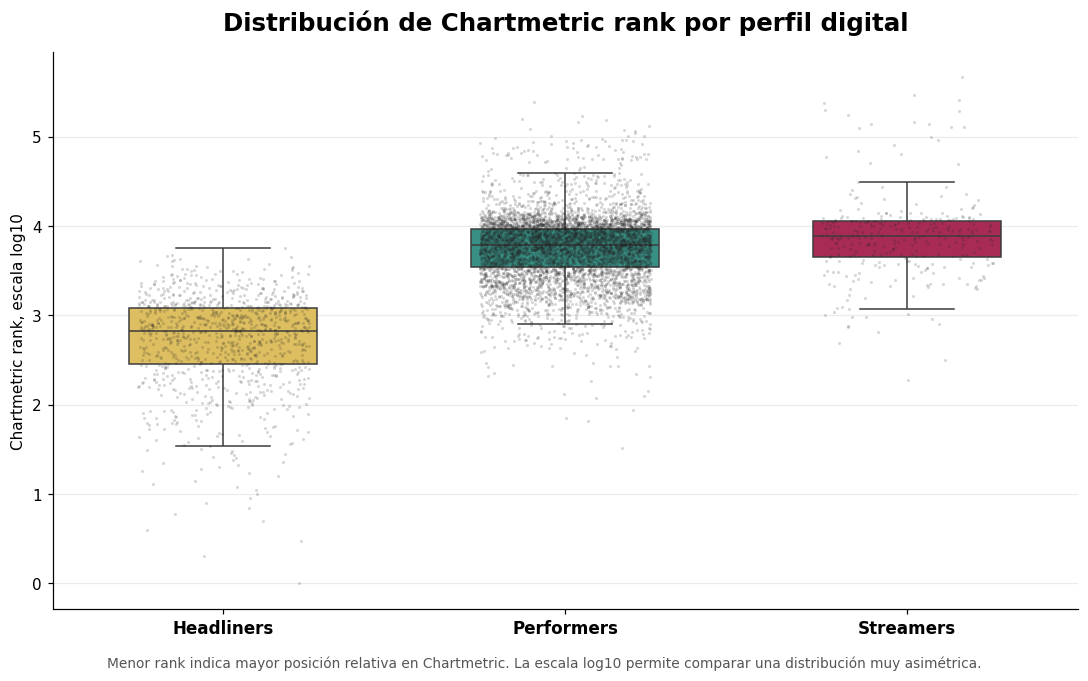

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\spectral3_chartmetric_rank_boxplot.png


tramo_rank,Top 100,101-500,501-1.000,1.001-2.500,2.501-5.000,5.001-10.000,>10.000
perfil_sp3,,,,,,,
Headliners,9.5,30.9,27.6,27.3,4.6,0.1,0.0
Performers,0.1,0.7,2.0,13.6,23.3,39.8,20.6
Streamers,0.0,1.0,2.3,8.8,17.9,34.7,35.4


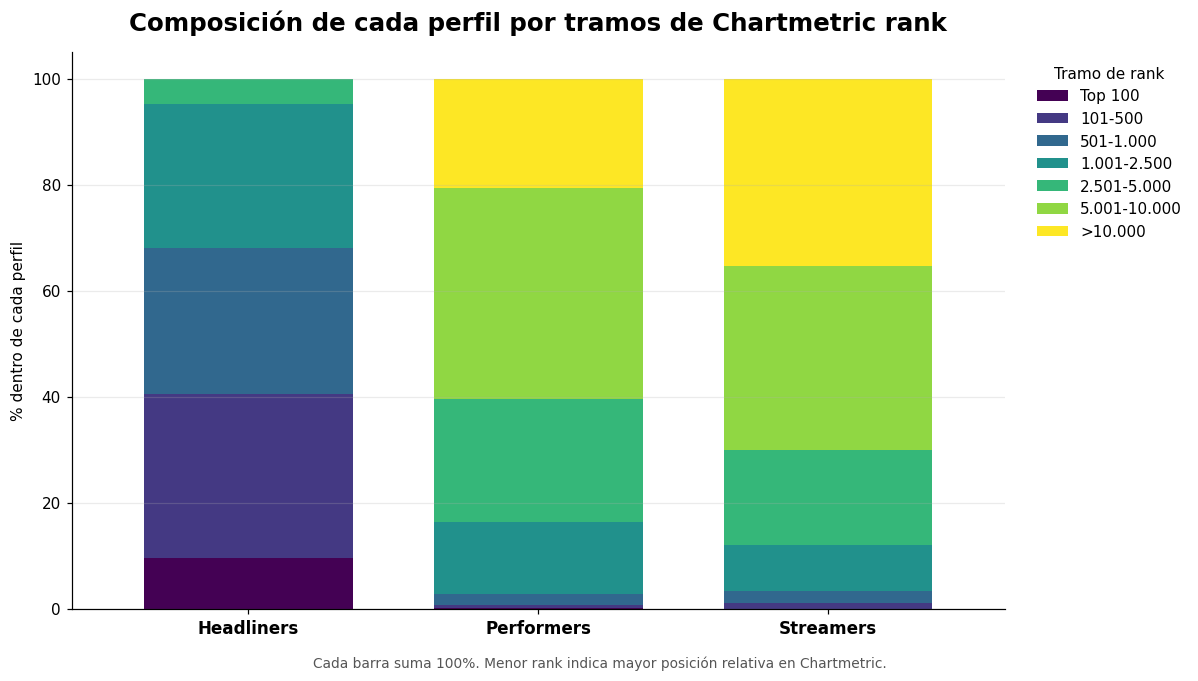

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\spectral3_chartmetric_rank_tramos.png


In [74]:
# ============================================================
# Asociación entre perfil Spectral k=3 y Chartmetric rank
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_rank_clusters_sp3 = df_muestra_artistas_sp3.copy()

# ------------------------------------------------------------
# Controles mínimos
# ------------------------------------------------------------

columnas_necesarias = [
    "perfil_sp3",
    "chartmetric_rank"
]

columnas_faltantes = [
    col for col in columnas_necesarias
    if col not in df_rank_clusters_sp3.columns
]

if len(columnas_faltantes) > 0:
    raise ValueError(f"Faltan columnas necesarias: {columnas_faltantes}")

df_rank_clusters_sp3 = (
    df_rank_clusters_sp3
    .dropna(subset=["perfil_sp3", "chartmetric_rank"])
    .copy()
)

df_rank_clusters_sp3["chartmetric_rank"] = pd.to_numeric(
    df_rank_clusters_sp3["chartmetric_rank"],
    errors="coerce"
)

df_rank_clusters_sp3 = df_rank_clusters_sp3.dropna(subset=["chartmetric_rank"])

df_rank_clusters_sp3["log10_chartmetric_rank"] = np.log10(
    df_rank_clusters_sp3["chartmetric_rank"]
)

orden_perfiles = [
    "Headliners",
    "Performers",
    "Streamers"
]

palette_sp3 = {
    "Headliners": "#F2C94C",
    "Performers": "#2A9D8F",
    "Streamers": "#BD164F"
}

# ------------------------------------------------------------
# Resumen numérico
# ------------------------------------------------------------

resumen_rank_sp3 = (
    df_rank_clusters_sp3
    .groupby("perfil_sp3")
    .agg(
        n=("chartmetric_rank", "size"),
        rank_mediana=("chartmetric_rank", "median"),
        rank_p25=("chartmetric_rank", lambda x: x.quantile(0.25)),
        rank_p75=("chartmetric_rank", lambda x: x.quantile(0.75)),
        rank_p90=("chartmetric_rank", lambda x: x.quantile(0.90))
    )
    .reindex(orden_perfiles)
    .reset_index()
)

display(resumen_rank_sp3)

# ------------------------------------------------------------
# Gráfico 1: distribución continua del ranking
# ------------------------------------------------------------

ruta_rank_boxplot = (
    directorio_salidas_proyecto /
    "spectral3_chartmetric_rank_boxplot.png"
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=df_rank_clusters_sp3,
    x="perfil_sp3",
    y="log10_chartmetric_rank",
    order=orden_perfiles,
    palette=palette_sp3,
    width=0.55,
    showfliers=False,
    ax=ax
)

sns.stripplot(
    data=df_rank_clusters_sp3,
    x="perfil_sp3",
    y="log10_chartmetric_rank",
    order=orden_perfiles,
    color="#222222",
    alpha=0.18,
    size=2,
    jitter=0.25,
    ax=ax
)

ax.set_title(
    "Distribución de Chartmetric rank por perfil digital",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("")
ax.set_ylabel("Chartmetric rank, escala log10")

ax.set_xticklabels(
    orden_perfiles,
    fontsize=11,
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.figtext(
    0.5,
    -0.02,
    "Menor rank indica mayor posición relativa en Chartmetric. La escala log10 permite comparar una distribución muy asimétrica.",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout()

plt.savefig(
    ruta_rank_boxplot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Archivo guardado en:", ruta_rank_boxplot)

# ------------------------------------------------------------
# Gráfico 2: composición por tramos de ranking
# ------------------------------------------------------------

bins_rank = [
    0,
    100,
    500,
    1000,
    2500,
    5000,
    10000,
    np.inf
]

labels_rank = [
    "Top 100",
    "101-500",
    "501-1.000",
    "1.001-2.500",
    "2.501-5.000",
    "5.001-10.000",
    ">10.000"
]

df_rank_clusters_sp3["tramo_rank"] = pd.cut(
    df_rank_clusters_sp3["chartmetric_rank"],
    bins=bins_rank,
    labels=labels_rank,
    include_lowest=True
)

tabla_tramos_rank = (
    pd.crosstab(
        df_rank_clusters_sp3["perfil_sp3"],
        df_rank_clusters_sp3["tramo_rank"],
        normalize="index"
    )
    .reindex(orden_perfiles)
    .fillna(0)
    * 100
)

display(tabla_tramos_rank.round(1))

ruta_rank_tramos = (
    directorio_salidas_proyecto /
    "spectral3_chartmetric_rank_tramos.png"
)

fig, ax = plt.subplots(figsize=(11, 6))

tabla_tramos_rank.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    colormap="viridis",
    width=0.72
)

ax.set_title(
    "Composición de cada perfil por tramos de Chartmetric rank",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("")
ax.set_ylabel("% dentro de cada perfil")

ax.set_xticklabels(
    orden_perfiles,
    rotation=0,
    fontsize=11,
    fontweight="bold"
)

ax.legend(
    title="Tramo de rank",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.figtext(
    0.5,
    -0.02,
    "Cada barra suma 100%. Menor rank indica mayor posición relativa en Chartmetric.",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout()

plt.savefig(
    ruta_rank_tramos,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Archivo guardado en:", ruta_rank_tramos)

# artistas argentina / cluster / rank

In [75]:
# ============================================================
# Artistas de Argentina | Cluster Spectral k=3 + CM rank + nombre
# ============================================================

df_argentina_sp3 = df_muestra_artistas_sp3.copy()

# ------------------------------------------------------------
# Mapa de perfiles
# ------------------------------------------------------------

mapa_perfiles_sp3 = {
    0: "Headliners",
    1: "Performers",
    2: "Streamers"
}

if "perfil_sp3" not in df_argentina_sp3.columns:
    df_argentina_sp3["perfil_sp3"] = (
        df_argentina_sp3["sp3"]
        .map(mapa_perfiles_sp3)
    )

# ------------------------------------------------------------
# Filtro Argentina
# ------------------------------------------------------------

df_argentina_sp3 = (
    df_argentina_sp3
    .loc[
        df_argentina_sp3["country"]
        .astype(str)
        .str.lower()
        .isin(["argentina", "ar", "arg"])
    ]
    .copy()
)

# ------------------------------------------------------------
# Salida final
# ------------------------------------------------------------

artistas_argentina_cluster_rank = (
    df_argentina_sp3
    .sort_values(
        by=["chartmetric_rank", "artist_name"],
        ascending=[True, True],
        na_position="last"
    )
    [["perfil_sp3", "chartmetric_rank", "artist_name"]]
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Guardar artistas de Argentina en TXT
# ------------------------------------------------------------

ruta_argentina_txt = (
    directorio_salidas_proyecto /
    "artistas_argentina_cluster_rank_spectral_k3.txt"
)

with open(ruta_argentina_txt, "w", encoding="utf-8") as f:
    
    f.write("Artistas de Argentina | Spectral k=3 + Chartmetric rank\n")
    f.write("=" * 62 + "\n\n")
    
    f.write(f"Total de registros: {len(artistas_argentina_cluster_rank)}\n\n")
    
    for i, row in artistas_argentina_cluster_rank.iterrows():
        
        perfil = row["perfil_sp3"]
        rank = row["chartmetric_rank"]
        nombre = row["artist_name"]
        
        f.write(f"{i + 1}. {perfil} | rank {rank} | {nombre}\n")

print("Archivo guardado en:", ruta_argentina_txt) 
display(artistas_argentina_cluster_rank)

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\artistas_argentina_cluster_rank_spectral_k3.txt


# tabla k=3 spectral

In [76]:
# ============================================================
# Spectral k=3 | Matriz extendida de perfiles para slide
# Columnas = clusters
# Filas = predictores activos y variables descriptivas ex-post
# ============================================================

matriz_perfiles_sp3_es = None

cluster_col = "sp3"

columnas_clusters = [
    "Headliners",
    "Performers",
    "Streamers"
]

mapa_perfil_a_cluster = {
    "Headliners": 0,
    "Performers": 1,
    "Streamers": 2
}

cluster_colors = {
    "Headliners": "#F2C94C",
    "Performers": "#2A9D8F",
    "Streamers": "#BD164F"
}

# ------------------------------------------------------------
# Predictores activos del modelo de clustering
# ------------------------------------------------------------

predictores_digitales_spectral = [
    "sp_monthly_listeners",
    "sp_editorial_playlist_total_reach",
    "num_az_playlists",
    "num_yt_editorial_playlists",
    "pandora_lifetime_streams",
    "deezer_fans",
    "ins_followers",
    "ycs_views",
    "tiktok_top_video_comments",
    "social_sp_ratio",
    "tiktok_sp_ratio"
]

# ------------------------------------------------------------
# Incorporación de ratios si existen en df_log2 pero no en df_full
# ------------------------------------------------------------

df_perfiles_sp3 = df_full.copy()

for col in ["social_sp_ratio", "tiktok_sp_ratio"]:
    if col not in df_perfiles_sp3.columns:
        if "df_log2" in globals() and col in df_log2.columns:
            df_perfiles_sp3[col] = df_log2[col].values

columnas_requeridas = (
    [cluster_col]
    + predictores_digitales_spectral
    + [
        "major_record_label",
        "country_short",
        "genre_short",
        "n_shows_24_25"
    ]
)

columnas_faltantes = [
    col for col in columnas_requeridas
    if col not in df_perfiles_sp3.columns
]

print("Columnas faltantes:", columnas_faltantes)

if len(columnas_faltantes) > 0:
    raise ValueError("Faltan columnas necesarias para reconstruir la matriz extendida.")

# ------------------------------------------------------------
# Función auxiliar para discretizar niveles relativos entre clusters
# ------------------------------------------------------------

def discretizar_bajo_medio_alto(serie):
    
    serie = serie.astype(float)
    
    ranking = serie.rank(method="first")
    
    niveles = pd.Series(index=serie.index, dtype="object")
    niveles.loc[ranking.idxmin()] = "Bajo"
    niveles.loc[ranking.idxmax()] = "Alto"
    
    indices_restantes = [
        idx for idx in serie.index
        if idx not in [ranking.idxmin(), ranking.idxmax()]
    ]
    
    for idx in indices_restantes:
        niveles.loc[idx] = "Medio"
    
    return niveles

# ------------------------------------------------------------
# Función auxiliar para top categorías con saltos de línea
# ------------------------------------------------------------

def obtener_top_categorias_por_perfil(df_base, cluster_col, variable, mapa_perfil_a_cluster, top_n):
    
    resultado_top = {}
    
    for perfil, cluster_id in mapa_perfil_a_cluster.items():
        
        datos_cluster = df_base.loc[df_base[cluster_col] == cluster_id, variable]
        
        distribucion = (
            datos_cluster
            .value_counts(normalize=True, dropna=True)
            .mul(100)
            .round(1)
            .head(top_n)
        )
        
        texto_top = "\n".join([
            f"{categoria} ({pct:.1f}%)"
            for categoria, pct in distribucion.items()
        ])
        
        resultado_top[perfil] = texto_top
    
    return resultado_top

# ------------------------------------------------------------
# Función auxiliar para región sobrerrepresentada por lift
# ------------------------------------------------------------

def obtener_region_sobrerrepresentada_por_perfil(df_base, cluster_col, mapa_perfil_a_cluster):
    
    resultado_region = {}
    
    distribucion_total = (
        df_base["country_short"]
        .value_counts(normalize=True, dropna=True)
    )
    
    for perfil, cluster_id in mapa_perfil_a_cluster.items():
        
        datos_cluster = df_base.loc[df_base[cluster_col] == cluster_id, "country_short"]
        
        distribucion_cluster = (
            datos_cluster
            .value_counts(normalize=True, dropna=True)
        )
        
        regiones_comunes = distribucion_cluster.index.intersection(distribucion_total.index)
        
        lift_region = (
            distribucion_cluster.loc[regiones_comunes] /
            distribucion_total.loc[regiones_comunes]
        )
        
        region_top = lift_region.idxmax()
        pct_region = distribucion_cluster.loc[region_top] * 100
        lift_top = lift_region.loc[region_top]
        
        resultado_region[perfil] = f"{region_top} ({pct_region:.1f}% | {lift_top:.2f}x)"
    
    return resultado_region

# ------------------------------------------------------------
# Perfiles digitales por cluster
# ------------------------------------------------------------

medianas_digitales_por_cluster = {}

for variable in predictores_digitales_spectral:
    
    valores_cluster = {}
    
    for perfil, cluster_id in mapa_perfil_a_cluster.items():
        
        serie_variable = df_perfiles_sp3.loc[
            df_perfiles_sp3[cluster_col] == cluster_id,
            variable
        ]
        
        if variable in ["social_sp_ratio", "tiktok_sp_ratio"]:
            valor_mediano = serie_variable.median()
        else:
            valor_mediano = np.log1p(serie_variable.fillna(0).astype(float)).median()
        
        valores_cluster[perfil] = valor_mediano
    
    medianas_digitales_por_cluster[variable] = pd.Series(valores_cluster)

# ------------------------------------------------------------
# Construcción de filas digitales
# ------------------------------------------------------------

filas_matriz = []

for variable in predictores_digitales_spectral:
    
    niveles_variable = discretizar_bajo_medio_alto(
        medianas_digitales_por_cluster[variable]
    )
    
    fila_variable = {
        "dimension": "ESTRUCTURA DIGITAL",
        "Atributo": variable
    }
    
    for perfil in columnas_clusters:
        fila_variable[perfil] = niveles_variable[perfil]
    
    filas_matriz.append(fila_variable)

# ------------------------------------------------------------
# Metadata ex-post
# ------------------------------------------------------------

top2_regiones_por_perfil = obtener_top_categorias_por_perfil(
    df_base=df_perfiles_sp3,
    cluster_col=cluster_col,
    variable="country_short",
    mapa_perfil_a_cluster=mapa_perfil_a_cluster,
    top_n=2
)

top3_generos_por_perfil = obtener_top_categorias_por_perfil(
    df_base=df_perfiles_sp3,
    cluster_col=cluster_col,
    variable="genre_short",
    mapa_perfil_a_cluster=mapa_perfil_a_cluster,
    top_n=3
)

region_sobrerrepresentada_por_perfil = obtener_region_sobrerrepresentada_por_perfil(
    df_base=df_perfiles_sp3,
    cluster_col=cluster_col,
    mapa_perfil_a_cluster=mapa_perfil_a_cluster
)

major_por_perfil = {}

for perfil, cluster_id in mapa_perfil_a_cluster.items():
    
    datos_major_cluster = df_perfiles_sp3.loc[
        df_perfiles_sp3[cluster_col] == cluster_id,
        "major_record_label"
    ]
    
    pct_major = datos_major_cluster.mean(skipna=True) * 100
    major_por_perfil[perfil] = f"{pct_major:.1f}%"

filas_metadata = [
    {
        "dimension": "METADATA EX-POST",
        "Atributo": "major_record_label",
        **{perfil: major_por_perfil[perfil] for perfil in columnas_clusters}
    },
    {
        "dimension": "METADATA EX-POST",
        "Atributo": "Región sobrerrepresentada",
        **{perfil: region_sobrerrepresentada_por_perfil[perfil] for perfil in columnas_clusters}
    },
    {
        "dimension": "METADATA EX-POST",
        "Atributo": "Top 2 regiones",
        **{perfil: top2_regiones_por_perfil[perfil] for perfil in columnas_clusters}
    },
    {
        "dimension": "METADATA EX-POST",
        "Atributo": "Top 3 géneros",
        **{perfil: top3_generos_por_perfil[perfil] for perfil in columnas_clusters}
    }
]

filas_matriz.extend(filas_metadata)

# ------------------------------------------------------------
# Actividad live ex-post
# ------------------------------------------------------------

resumenes_live = {
    "Cobertura n_shows_24_25": "coverage",
    "Mediana n_shows_24_25": "median",
    "p75 n_shows_24_25": "p75",
    "p90 n_shows_24_25": "p90",
    "% artistas con 0 shows": "zero"
}

for atributo_live, funcion_resumen in resumenes_live.items():
    
    fila_live = {
        "dimension": "ACTIVIDAD LIVE EX-POST",
        "Atributo": atributo_live
    }
    
    for perfil, cluster_id in mapa_perfil_a_cluster.items():
        
        datos_cluster = df_perfiles_sp3.loc[df_perfiles_sp3[cluster_col] == cluster_id]
        serie_shows = datos_cluster["n_shows_24_25"]
        serie_shows_observada = serie_shows.dropna()
        
        if funcion_resumen == "coverage":
            valor = f"{serie_shows_observada.shape[0]} / {datos_cluster.shape[0]}"
        elif funcion_resumen == "median":
            valor = f"{serie_shows_observada.median():.0f}"
        elif funcion_resumen == "p75":
            valor = f"{serie_shows_observada.quantile(0.75):.0f}"
        elif funcion_resumen == "p90":
            valor = f"{serie_shows_observada.quantile(0.90):.0f}"
        elif funcion_resumen == "zero":
            valor = f"{(serie_shows_observada == 0).mean() * 100:.1f}%"
        
        fila_live[perfil] = valor
    
    filas_matriz.append(fila_live)

matriz_perfiles_sp3_es = pd.DataFrame(filas_matriz)

# ------------------------------------------------------------
# Normalización mínima de textos internos
# ------------------------------------------------------------

reemplazos_texto = {
    "Europe_sinGB": "Europa sin GB",
    "Africa & ME": "África & Medio Oriente",
    "North America": "Norteamérica",
    "Asia & Oceania": "Asia & Oceanía",
    "Great Britain": "Gran Bretaña",
    "LATAM": "LATAM"
}

for col in matriz_perfiles_sp3_es.columns:
    if matriz_perfiles_sp3_es[col].dtype == "object":
        for texto_original, texto_reemplazo in reemplazos_texto.items():
            matriz_perfiles_sp3_es[col] = (
                matriz_perfiles_sp3_es[col]
                .str.replace(texto_original, texto_reemplazo, regex=False)
            )

# ------------------------------------------------------------
# Control de major_record_label
# ------------------------------------------------------------

control_major_record_label_sp3 = []

for perfil, cluster_id in mapa_perfil_a_cluster.items():
    
    datos_major_cluster = df_perfiles_sp3.loc[
        df_perfiles_sp3[cluster_col] == cluster_id,
        "major_record_label"
    ]
    
    control_major_record_label_sp3.append({
        "perfil": perfil,
        "cluster": cluster_id,
        "n_total": datos_major_cluster.shape[0],
        "n_validos_major_record_label": datos_major_cluster.notna().sum(),
        "pct_major_sobre_validos": datos_major_cluster.mean(skipna=True) * 100,
        "pct_major_nan_como_false": datos_major_cluster.fillna(False).mean() * 100
    })

control_major_record_label_sp3 = pd.DataFrame(control_major_record_label_sp3)

display(matriz_perfiles_sp3_es)
display(control_major_record_label_sp3)

Columnas faltantes: []


,dimension,Atributo,Headliners,Performers,Streamers
0,ESTRUCTURA DIGITAL,sp_monthly_listeners,Alto,Medio,Bajo
1,ESTRUCTURA DIGITAL,sp_editorial_playlist_total_reach,Alto,Medio,Bajo
2,ESTRUCTURA DIGITAL,num_az_playlists,Alto,Medio,Bajo
3,ESTRUCTURA DIGITAL,num_yt_editorial_playlists,Alto,Medio,Bajo
4,ESTRUCTURA DIGITAL,pandora_lifetime_streams,Alto,Medio,Bajo
5,ESTRUCTURA DIGITAL,deezer_fans,Alto,Medio,Bajo
6,ESTRUCTURA DIGITAL,ins_followers,Alto,Bajo,Medio
7,ESTRUCTURA DIGITAL,ycs_views,Alto,Bajo,Medio
8,ESTRUCTURA DIGITAL,tiktok_top_video_comments,Alto,Medio,Bajo
9,ESTRUCTURA DIGITAL,social_sp_ratio,Medio,Bajo,Alto


,perfil,cluster,n_total,n_validos_major_record_label,pct_major_sobre_validos,pct_major_nan_como_false
0,Headliners,0,1012,960,50.729167,48.122530
1,Performers,1,5680,5244,23.054920,21.285211
2,Streamers,2,308,272,5.514706,4.870130


Columnas faltantes en matriz_perfiles_sp3_vista: []


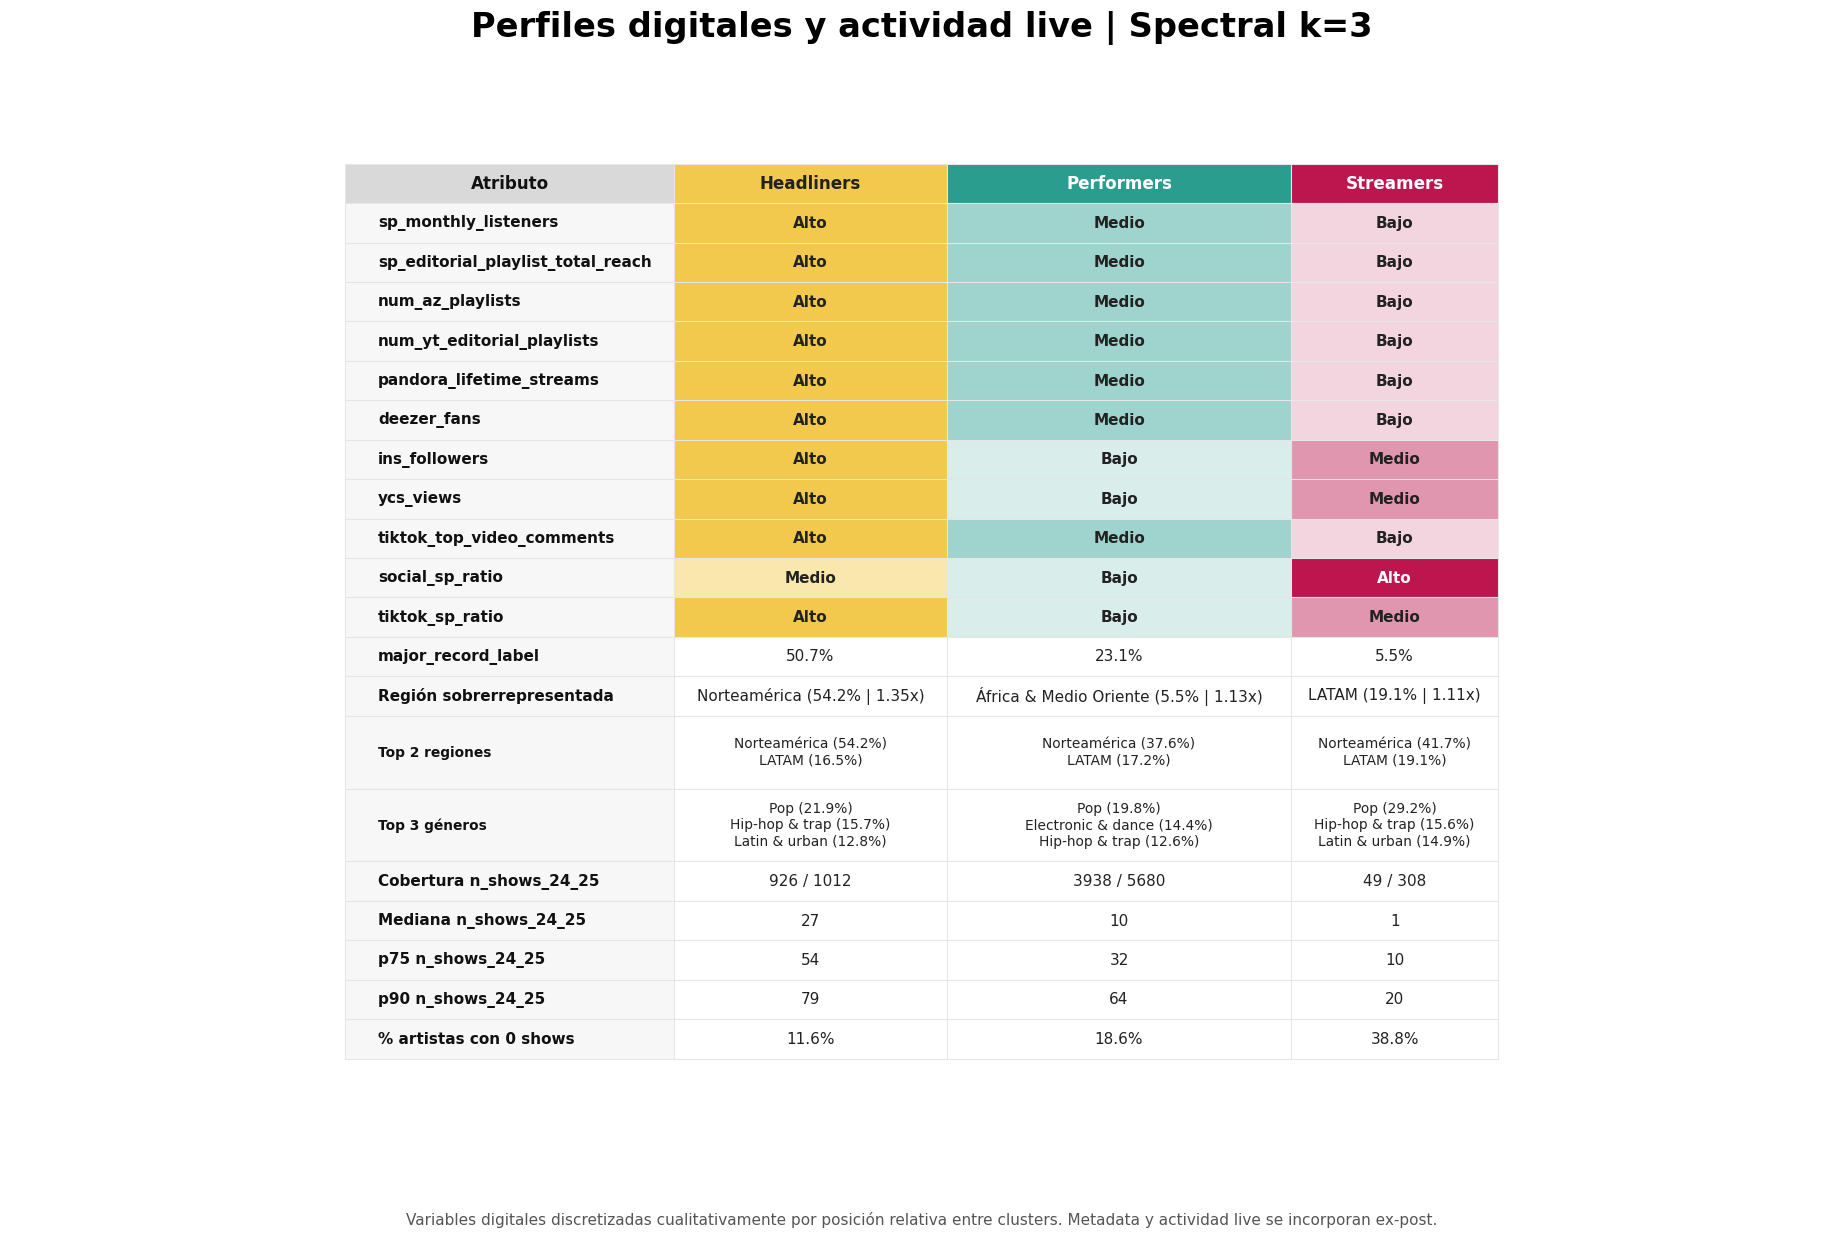

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\matriz_perfiles_spectral_k3_extendida.png


Atributo,Headliners,Performers,Streamers
sp_monthly_listeners,Alto,Medio,Bajo
sp_editorial_playlist_total_reach,Alto,Medio,Bajo
num_az_playlists,Alto,Medio,Bajo
num_yt_editorial_playlists,Alto,Medio,Bajo
pandora_lifetime_streams,Alto,Medio,Bajo
deezer_fans,Alto,Medio,Bajo
ins_followers,Alto,Bajo,Medio
ycs_views,Alto,Bajo,Medio
tiktok_top_video_comments,Alto,Medio,Bajo
social_sp_ratio,Medio,Bajo,Alto


In [77]:
# ============================================================
# Vista estilizada y exportación PNG de matriz extendida Spectral k=3
# Colores de intensidad según cluster y nivel
# ============================================================

import matplotlib.colors as mcolors

# ------------------------------------------------------------
# Preparación de tabla para visualización
# ------------------------------------------------------------

matriz_perfiles_sp3_vista = matriz_perfiles_sp3_es.copy()

if "dimension" in matriz_perfiles_sp3_vista.columns:
    matriz_perfiles_sp3_vista = matriz_perfiles_sp3_vista.drop(columns=["dimension"])

columnas_clusters = [
    "Headliners",
    "Performers",
    "Streamers"
]

cluster_colors = {
    "Headliners": "#F2C94C",
    "Performers": "#2A9D8F",
    "Streamers": "#BD164F"
}

columnas_faltantes_vista = [
    col for col in ["Atributo"] + columnas_clusters
    if col not in matriz_perfiles_sp3_vista.columns
]

print("Columnas faltantes en matriz_perfiles_sp3_vista:", columnas_faltantes_vista)

if len(columnas_faltantes_vista) > 0:
    raise ValueError("Faltan columnas necesarias para estilizar la matriz.")

# ------------------------------------------------------------
# Función auxiliar para aclarar color
# ------------------------------------------------------------

def aclarar_color(hex_color, amount=0.5):
    rgb = np.array(mcolors.to_rgb(hex_color))
    blanco = np.array([1, 1, 1])
    nuevo_rgb = rgb + (blanco - rgb) * amount
    return mcolors.to_hex(nuevo_rgb)

cluster_color_levels = {
    cluster: {
        "Alto": cluster_colors[cluster],
        "Medio": aclarar_color(cluster_colors[cluster], 0.55),
        "Bajo": aclarar_color(cluster_colors[cluster], 0.82)
    }
    for cluster in columnas_clusters
}

# ------------------------------------------------------------
# Estilo HTML en notebook
# ------------------------------------------------------------

def estilo_por_columna_y_nivel(valor, nombre_columna):
    
    if valor not in ["Alto", "Medio", "Bajo"]:
        return ""
    
    color_fondo = cluster_color_levels[nombre_columna][valor]
    
    if valor == "Alto":
        color_texto = "white" if nombre_columna != "Headliners" else "#222222"
    else:
        color_texto = "#222222"
    
    return (
        f"background-color: {color_fondo}; "
        f"color: {color_texto}; "
        f"font-weight: bold;"
    )

styled_matriz_perfiles_sp3_es = (
    matriz_perfiles_sp3_vista
    .style
    .hide(axis="index")
)

for col in columnas_clusters:
    styled_matriz_perfiles_sp3_es = styled_matriz_perfiles_sp3_es.map(
        lambda v, nombre_columna=col: estilo_por_columna_y_nivel(v, nombre_columna),
        subset=[col]
    )

estilos_encabezados_clusters = []

for idx_columna, nombre_columna in enumerate(matriz_perfiles_sp3_vista.columns):
    
    if nombre_columna in cluster_colors:
        
        color_fondo = cluster_colors[nombre_columna]
        color_texto = "#222222" if nombre_columna == "Headliners" else "white"
        
        estilos_encabezados_clusters.append({
            "selector": f"th.col{idx_columna}",
            "props": [
                ("background-color", color_fondo),
                ("color", color_texto),
                ("font-weight", "bold"),
                ("text-align", "center")
            ]
        })

styled_matriz_perfiles_sp3_es = (
    styled_matriz_perfiles_sp3_es
    .set_properties(subset=["Atributo"], **{
        "font-weight": "bold",
        "text-align": "left"
    })
    .set_properties(subset=columnas_clusters, **{
        "text-align": "center",
        "white-space": "pre-line"
    })
    .set_table_styles(
        [
            {"selector": "th", "props": [
                ("font-size", "12pt"),
                ("text-align", "center"),
                ("font-weight", "bold")
            ]},
            {"selector": "td", "props": [
                ("font-size", "11pt"),
                ("padding", "6px 8px"),
                ("border-bottom", "1px solid #eeeeee"),
                ("vertical-align", "middle")
            ]},
            {"selector": "table", "props": [
                ("border-collapse", "collapse"),
                ("width", "100%")
            ]}
        ] + estilos_encabezados_clusters
    )
)

# ============================================================
# Exportación PNG
# ============================================================

matriz_exportar_sp3 = matriz_perfiles_sp3_vista.copy()

archivo_matriz_perfiles_sp3 = (
    directorio_salidas_proyecto /
    "matriz_perfiles_spectral_k3_extendida.png"
)

fig = plt.figure(figsize=(18, 12))

ax = fig.add_axes([0.04, 0.12, 0.92, 0.78])
ax.axis("off")

tabla_matriz_sp3 = ax.table(
    cellText=matriz_exportar_sp3.values,
    colLabels=matriz_exportar_sp3.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

tabla_matriz_sp3.auto_set_font_size(False)
tabla_matriz_sp3.set_fontsize(10)
tabla_matriz_sp3.scale(1, 2.15)

color_header_atributo = "#D9D9D9"
color_borde = "#E6E6E6"
color_texto = "#222222"

for (fila, columna), celda in tabla_matriz_sp3.get_celld().items():
    
    celda.set_edgecolor(color_borde)
    celda.set_linewidth(0.7)
    
    if fila == 0:
        
        nombre_columna = matriz_exportar_sp3.columns[columna]
        
        if nombre_columna in cluster_colors:
            celda.set_facecolor(cluster_colors[nombre_columna])
            color_texto_header = "#222222" if nombre_columna == "Headliners" else "white"
            celda.get_text().set_color(color_texto_header)
        else:
            celda.set_facecolor(color_header_atributo)
            celda.get_text().set_color("#111111")
        
        celda.get_text().set_weight("bold")
        celda.get_text().set_fontsize(11)
    
    else:
        
        texto_celda = celda.get_text().get_text()
        nombre_columna = matriz_exportar_sp3.columns[columna]
        
        if columna == 0:
            celda.set_facecolor("#F7F7F7")
            celda.get_text().set_weight("bold")
            celda.get_text().set_ha("left")
            celda.get_text().set_color("#111111")
        
        elif nombre_columna in columnas_clusters and texto_celda in ["Alto", "Medio", "Bajo"]:
            
            color_fondo = cluster_color_levels[nombre_columna][texto_celda]
            celda.set_facecolor(color_fondo)
            
            if texto_celda == "Alto":
                color_texto_celda = "white" if nombre_columna != "Headliners" else "#222222"
            else:
                color_texto_celda = "#222222"
            
            celda.get_text().set_color(color_texto_celda)
            celda.get_text().set_weight("bold")
        
        else:
            celda.set_facecolor("white")
            celda.get_text().set_color(color_texto)

        atributo_fila = matriz_exportar_sp3.iloc[fila - 1, 0]
        
        if atributo_fila in ["Top 2 regiones", "Top 3 géneros"]:
            celda.set_height(celda.get_height() * 1.85)
            celda.get_text().set_fontsize(9)

for columna in range(len(matriz_exportar_sp3.columns)):
    tabla_matriz_sp3.auto_set_column_width(col=columna)

fig.suptitle(
    "Perfiles digitales y actividad live | Spectral k=3",
    fontsize=22,
    fontweight="bold",
    y=0.965
)

fig.text(
    0.5,
    0.045,
    "Variables digitales discretizadas cualitativamente por posición relativa entre clusters. Metadata y actividad live se incorporan ex-post.",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.savefig(
    archivo_matriz_perfiles_sp3,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25
)

plt.show()

print("Archivo guardado en:", archivo_matriz_perfiles_sp3)

styled_matriz_perfiles_sp3_es

Columnas faltantes en matriz_perfiles_sp3_vista: []


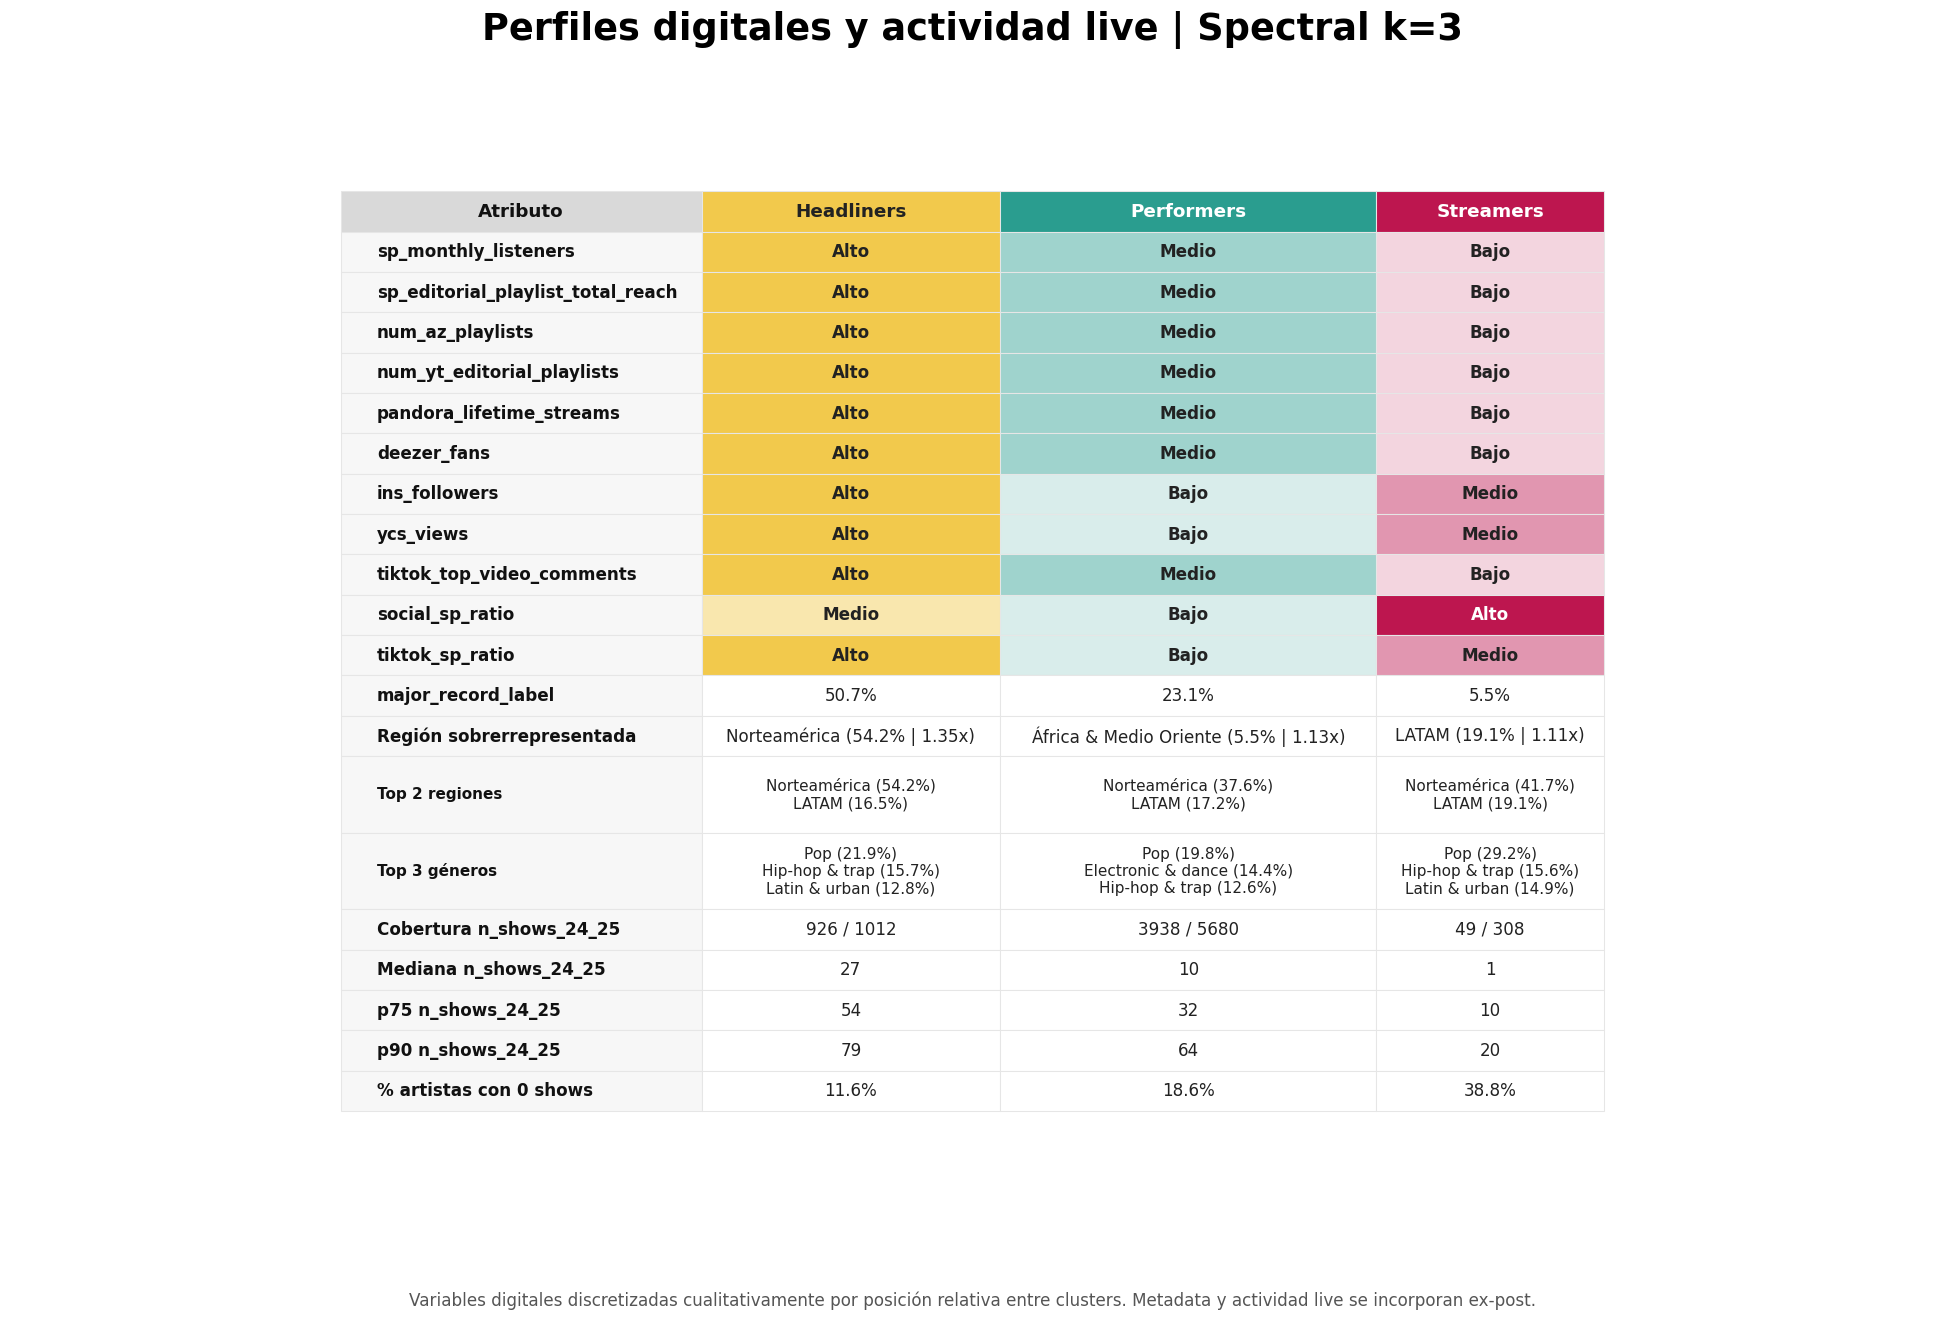

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\matriz_perfiles_spectral_k3_extendida.png


Atributo,Headliners,Performers,Streamers
sp_monthly_listeners,Alto,Medio,Bajo
sp_editorial_playlist_total_reach,Alto,Medio,Bajo
num_az_playlists,Alto,Medio,Bajo
num_yt_editorial_playlists,Alto,Medio,Bajo
pandora_lifetime_streams,Alto,Medio,Bajo
deezer_fans,Alto,Medio,Bajo
ins_followers,Alto,Bajo,Medio
ycs_views,Alto,Bajo,Medio
tiktok_top_video_comments,Alto,Medio,Bajo
social_sp_ratio,Medio,Bajo,Alto


In [78]:
# ============================================================
# Vista estilizada y exportación PNG de matriz extendida Spectral k=3
# Colores de intensidad según cluster y nivel
# ============================================================

import matplotlib.colors as mcolors

# ------------------------------------------------------------
# Preparación de tabla para visualización
# ------------------------------------------------------------

matriz_perfiles_sp3_vista = matriz_perfiles_sp3_es.copy()

if "dimension" in matriz_perfiles_sp3_vista.columns:
    matriz_perfiles_sp3_vista = matriz_perfiles_sp3_vista.drop(columns=["dimension"])

columnas_clusters = [
    "Headliners",
    "Performers",
    "Streamers"
]

cluster_colors = {
    "Headliners": "#F2C94C",
    "Performers": "#2A9D8F",
    "Streamers": "#BD164F"
}

columnas_faltantes_vista = [
    col for col in ["Atributo"] + columnas_clusters
    if col not in matriz_perfiles_sp3_vista.columns
]

print("Columnas faltantes en matriz_perfiles_sp3_vista:", columnas_faltantes_vista)

if len(columnas_faltantes_vista) > 0:
    raise ValueError("Faltan columnas necesarias para estilizar la matriz.")

# ------------------------------------------------------------
# Función auxiliar para aclarar color
# ------------------------------------------------------------

def aclarar_color(hex_color, amount=0.5):
    rgb = np.array(mcolors.to_rgb(hex_color))
    blanco = np.array([1, 1, 1])
    nuevo_rgb = rgb + (blanco - rgb) * amount
    return mcolors.to_hex(nuevo_rgb)

cluster_color_levels = {
    cluster: {
        "Alto": cluster_colors[cluster],
        "Medio": aclarar_color(cluster_colors[cluster], 0.55),
        "Bajo": aclarar_color(cluster_colors[cluster], 0.82)
    }
    for cluster in columnas_clusters
}

# ------------------------------------------------------------
# Estilo HTML en notebook
# ------------------------------------------------------------

def estilo_por_columna_y_nivel(valor, nombre_columna):
    
    if valor not in ["Alto", "Medio", "Bajo"]:
        return ""
    
    color_fondo = cluster_color_levels[nombre_columna][valor]
    
    if valor == "Alto":
        color_texto = "white" if nombre_columna != "Headliners" else "#222222"
    else:
        color_texto = "#222222"
    
    return (
        f"background-color: {color_fondo}; "
        f"color: {color_texto}; "
        f"font-weight: bold;"
    )

styled_matriz_perfiles_sp3_es = (
    matriz_perfiles_sp3_vista
    .style
    .hide(axis="index")
)

for col in columnas_clusters:
    styled_matriz_perfiles_sp3_es = styled_matriz_perfiles_sp3_es.map(
        lambda v, nombre_columna=col: estilo_por_columna_y_nivel(v, nombre_columna),
        subset=[col]
    )

estilos_encabezados_clusters = []

for idx_columna, nombre_columna in enumerate(matriz_perfiles_sp3_vista.columns):
    
    if nombre_columna in cluster_colors:
        
        color_fondo = cluster_colors[nombre_columna]
        color_texto = "#222222" if nombre_columna == "Headliners" else "white"
        
        estilos_encabezados_clusters.append({
            "selector": f"th.col{idx_columna}",
            "props": [
                ("background-color", color_fondo),
                ("color", color_texto),
                ("font-weight", "bold"),
                ("text-align", "center")
            ]
        })

styled_matriz_perfiles_sp3_es = (
    styled_matriz_perfiles_sp3_es
    .set_properties(subset=["Atributo"], **{
        "font-weight": "bold",
        "text-align": "left"
    })
    .set_properties(subset=columnas_clusters, **{
        "text-align": "center",
        "white-space": "pre-line"
    })
    .set_table_styles(
        [
            {"selector": "th", "props": [
                ("font-size", "13pt"),
                ("text-align", "center"),
                ("font-weight", "bold")
            ]},
            {"selector": "td", "props": [
                ("font-size", "12pt"),
                ("padding", "7px 9px"),
                ("border-bottom", "1px solid #eeeeee"),
                ("vertical-align", "middle")
            ]},
            {"selector": "table", "props": [
                ("border-collapse", "collapse"),
                ("width", "100%")
            ]}
        ] + estilos_encabezados_clusters
    )
)

# ============================================================
# Exportación PNG
# ============================================================

matriz_exportar_sp3 = matriz_perfiles_sp3_vista.copy()

archivo_matriz_perfiles_sp3 = (
    directorio_salidas_proyecto /
    "matriz_perfiles_spectral_k3_extendida.png"
)

fig = plt.figure(figsize=(19, 12.8))

ax = fig.add_axes([0.04, 0.13, 0.92, 0.76])
ax.axis("off")

tabla_matriz_sp3 = ax.table(
    cellText=matriz_exportar_sp3.values,
    colLabels=matriz_exportar_sp3.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

tabla_matriz_sp3.auto_set_font_size(False)
tabla_matriz_sp3.set_fontsize(11)
tabla_matriz_sp3.scale(1, 2.20)

color_header_atributo = "#D9D9D9"
color_borde = "#E6E6E6"
color_texto = "#222222"

for (fila, columna), celda in tabla_matriz_sp3.get_celld().items():
    
    celda.set_edgecolor(color_borde)
    celda.set_linewidth(0.7)
    
    if fila == 0:
        
        nombre_columna = matriz_exportar_sp3.columns[columna]
        
        if nombre_columna in cluster_colors:
            celda.set_facecolor(cluster_colors[nombre_columna])
            color_texto_header = "#222222" if nombre_columna == "Headliners" else "white"
            celda.get_text().set_color(color_texto_header)
        else:
            celda.set_facecolor(color_header_atributo)
            celda.get_text().set_color("#111111")
        
        celda.get_text().set_weight("bold")
        celda.get_text().set_fontsize(12)
    
    else:
        
        texto_celda = celda.get_text().get_text()
        nombre_columna = matriz_exportar_sp3.columns[columna]
        
        if columna == 0:
            celda.set_facecolor("#F7F7F7")
            celda.get_text().set_weight("bold")
            celda.get_text().set_ha("left")
            celda.get_text().set_color("#111111")
            celda.get_text().set_fontsize(11)
        
        elif nombre_columna in columnas_clusters and texto_celda in ["Alto", "Medio", "Bajo"]:
            
            color_fondo = cluster_color_levels[nombre_columna][texto_celda]
            celda.set_facecolor(color_fondo)
            
            if texto_celda == "Alto":
                color_texto_celda = "white" if nombre_columna != "Headliners" else "#222222"
            else:
                color_texto_celda = "#222222"
            
            celda.get_text().set_color(color_texto_celda)
            celda.get_text().set_weight("bold")
            celda.get_text().set_fontsize(11)
        
        else:
            celda.set_facecolor("white")
            celda.get_text().set_color(color_texto)
            celda.get_text().set_fontsize(11)

        atributo_fila = matriz_exportar_sp3.iloc[fila - 1, 0]
        
        if atributo_fila in ["Top 2 regiones", "Top 3 géneros"]:
            celda.set_height(celda.get_height() * 1.90)
            celda.get_text().set_fontsize(10)

for columna in range(len(matriz_exportar_sp3.columns)):
    tabla_matriz_sp3.auto_set_column_width(col=columna)

fig.suptitle(
    "Perfiles digitales y actividad live | Spectral k=3",
    fontsize=24,
    fontweight="bold",
    y=0.965
)

fig.text(
    0.5,
    0.045,
    "Variables digitales discretizadas cualitativamente por posición relativa entre clusters. Metadata y actividad live se incorporan ex-post.",
    ha="center",
    fontsize=11,
    color="#555555"
)

plt.savefig(
    archivo_matriz_perfiles_sp3,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.25
)

plt.show()

print("Archivo guardado en:", archivo_matriz_perfiles_sp3)

styled_matriz_perfiles_sp3_es

# spectral k=3 burbujas

NameError: name 'resumen_tamano' is not defined

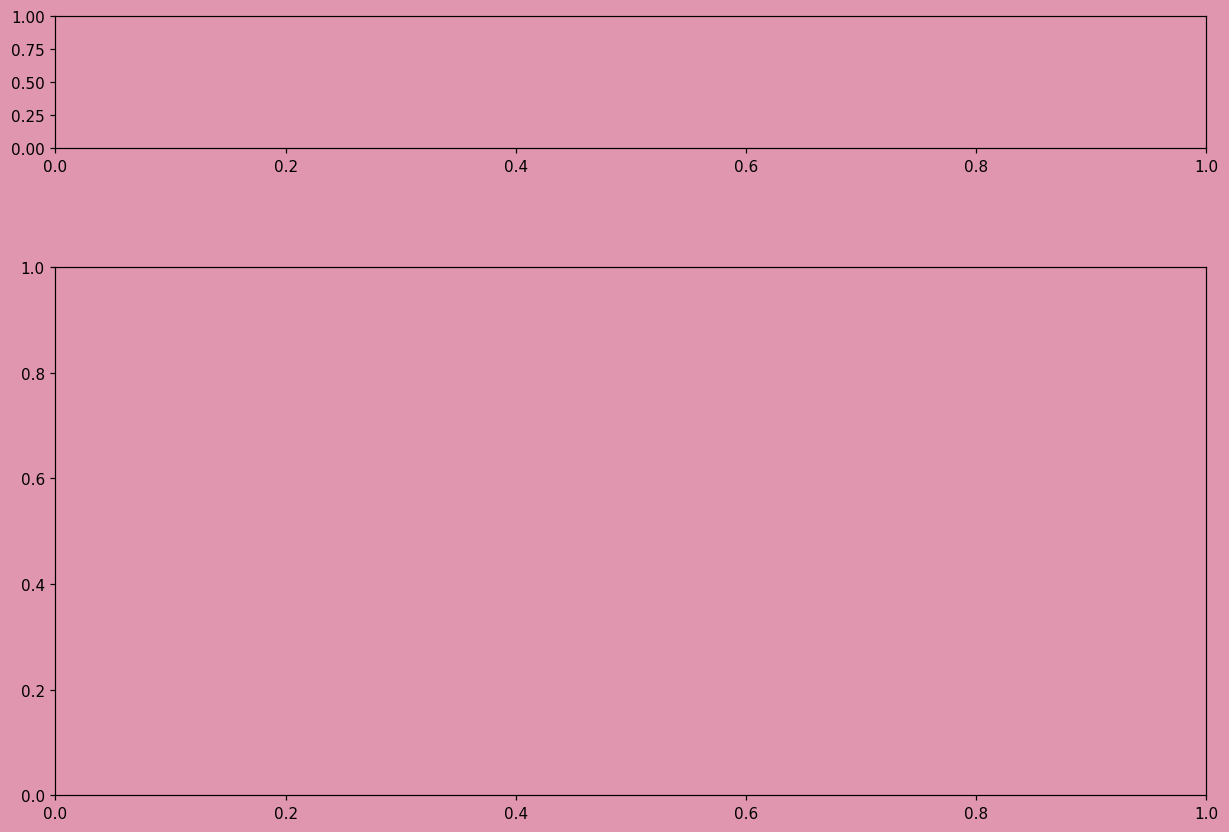

In [79]:
# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig = plt.figure(
    figsize=(13.5, 9.2),
    facecolor=color_fondo
)

gs = fig.add_gridspec(
    nrows=2,
    ncols=1,
    height_ratios=[1.05, 4.2],
    hspace=0.36
)

ax_comp = fig.add_subplot(gs[0, 0])
ax_mat = fig.add_subplot(gs[1, 0])

ax_comp.set_facecolor(color_fondo)
ax_mat.set_facecolor(color_fondo)

# ------------------------------------------------------------
# Panel superior: composición
# ------------------------------------------------------------

inicio = 0

for _, fila in resumen_tamano.iterrows():
    
    cluster_id = fila["cluster"]
    pct = fila["pct"]
    
    ax_comp.barh(
        y=0,
        width=pct,
        left=inicio,
        height=0.48,
        color=cluster_colors[cluster_id],
        edgecolor="white",
        linewidth=0.8
    )
    
    if pct >= 8:
        ax_comp.text(
            inicio + pct / 2,
            0,
            f"{fila['n']:,}\n{formato_pct(pct)}".replace(",", "."),
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            color="white"
        )
    else:
        ax_comp.text(
            inicio + pct + 1.2,
            0,
            f"{fila['n']:,} | {formato_pct(pct)}".replace(",", "."),
            ha="left",
            va="center",
            fontsize=12,
            fontweight="bold",
            color=color_texto
        )
    
    inicio += pct

ax_comp.set_xlim(0, 100)
ax_comp.set_ylim(-0.65, 0.65)

ax_comp.set_yticks([])
ax_comp.set_xticks([0, 25, 50, 75, 100])
ax_comp.set_xticklabels(
    ["0", "25", "50", "75", "100%"],
    fontsize=12,
    color=color_texto
)

ax_comp.tick_params(
    axis="x",
    length=5,
    width=1,
    colors=color_texto
)

ax_comp.spines["top"].set_visible(False)
ax_comp.spines["right"].set_visible(False)
ax_comp.spines["left"].set_visible(False)
ax_comp.spines["bottom"].set_color(color_texto)
ax_comp.spines["bottom"].set_linewidth(1.1)

ax_comp.grid(
    axis="x",
    color=color_grilla,
    linestyle=(0, (1, 3)),
    linewidth=0.9,
    alpha=0.95
)

ax_comp.set_axisbelow(True)

ax_comp.text(
    0,
    0.53,
    "Composición de la solución",
    ha="left",
    va="bottom",
    fontsize=15,
    fontweight="bold",
    color=color_texto
)

# ------------------------------------------------------------
# Panel inferior: matriz visual
# ------------------------------------------------------------

filas_digitales = list(dimensiones_digitales.keys())
filas_expost = [
    "Major label",
    "0 shows",
    "Mediana shows",
    "p90 shows"
]

filas = filas_digitales + filas_expost
y_positions = np.arange(len(filas))[::-1]

# Columnas desplazadas hacia la derecha para evitar pisar etiquetas
x_cluster = {
    0: 0.45,
    1: 1.65,
    2: 2.85
}

ax_mat.set_xlim(-1.25, 3.25)
ax_mat.set_ylim(-0.85, len(filas) - 0.10)

# Líneas guía horizontales
for y in y_positions:
    ax_mat.hlines(
        y,
        xmin=-0.04,
        xmax=3.08,
        color=color_grilla,
        linestyle=(0, (1, 3)),
        linewidth=0.9,
        alpha=0.70,
        zorder=0
    )

# Separador conceptual
separador_y = y_positions[len(filas_digitales) - 1] - 0.5

ax_mat.hlines(
    separador_y,
    xmin=-1.22,
    xmax=3.10,
    color=color_texto,
    linewidth=1.0,
    alpha=0.80,
    zorder=1
)

# Encabezados de columnas
for cluster_id in orden_clusters:
    
    ax_mat.text(
        x_cluster[cluster_id],
        len(filas) - 0.05,
        cluster_names[cluster_id],
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold",
        color=color_texto
    )

# Etiquetas de grupos
ax_mat.text(
    -1.21,
    y_positions[0] + 0.58,
    "Perfil digital activo",
    ha="left",
    va="center",
    fontsize=13,
    fontweight="bold",
    color=color_gris_texto
)

ax_mat.text(
    -1.21,
    y_positions[len(filas_digitales)] + 0.58,
    "Lectura ex-post",
    ha="left",
    va="center",
    fontsize=13,
    fontweight="bold",
    color=color_gris_texto,
    bbox=dict(
        facecolor=color_fondo,
        edgecolor="none",
        pad=1.5
    ),
    zorder=4
)

# Etiquetas de filas, alineadas a la derecha para que no pisen burbujas
for fila, y in zip(filas, y_positions):
    
    ax_mat.text(
        -0.18,
        y,
        fila,
        ha="right",
        va="center",
        fontsize=13,
        fontweight="bold" if fila in filas_digitales else "normal",
        color=color_texto,
        bbox=dict(
            facecolor=color_fondo,
            edgecolor="none",
            pad=1.2
        ),
        zorder=4
    )

# Celdas digitales
for i, dimension in enumerate(filas_digitales):
    
    y = y_positions[i]
    
    for cluster_id in orden_clusters:
        
        x = x_cluster[cluster_id]
        score = perfil_digital[dimension]["score"][cluster_id]
        nivel = perfil_digital[dimension]["nivel"][cluster_id]
        
        size = 440 + 1050 * score
        
        ax_mat.scatter(
            x,
            y,
            s=size,
            color=cluster_colors[cluster_id],
            alpha=0.20 + 0.58 * score,
            edgecolors="none",
            zorder=2
        )
        
        ax_mat.text(
            x,
            y,
            nivel,
            ha="center",
            va="center",
            fontsize=11.5,
            fontweight="bold",
            color=color_texto,
            zorder=3
        )

# Celdas ex-post
for j, fila in enumerate(filas_expost):
    
    y = y_positions[len(filas_digitales) + j]
    
    for cluster_id in orden_clusters:
        
        x = x_cluster[cluster_id]
        
        ax_mat.scatter(
            x,
            y,
            s=680,
            color=cluster_colors[cluster_id],
            alpha=0.17,
            edgecolors="none",
            zorder=2
        )
        
        ax_mat.text(
            x,
            y,
            perfil_expost[cluster_id][fila],
            ha="center",
            va="center",
            fontsize=12.5,
            fontweight="bold",
            color=color_texto,
            zorder=3
        )

# Limpieza de ejes
ax_mat.set_xticks([])
ax_mat.set_yticks([])

for spine in ["top", "right", "left", "bottom"]:
    ax_mat.spines[spine].set_visible(False)

# ------------------------------------------------------------
# Leyenda superior centrada con círculos
# ------------------------------------------------------------

legend_elements = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=cluster_colors[cluster_id],
        markeredgecolor="none",
        markersize=12,
        label=cluster_names[cluster_id]
    )
    for cluster_id in orden_clusters
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    frameon=False,
    fontsize=18,
    handletextpad=0.6,
    columnspacing=1.9,
    ncol=3,
    labelcolor=color_texto
)

# ------------------------------------------------------------
# Títulos apagados para mantener criterio visual del informe
# ------------------------------------------------------------

# fig.suptitle(
#     "Síntesis de perfiles digitales y actividad en vivo ex-post",
#     fontsize=20,
#     fontweight="bold",
#     color=color_texto,
#     y=1.02
# )

plt.tight_layout(rect=[0, 0, 1, 0.91])

# ------------------------------------------------------------
# Guardado
# ------------------------------------------------------------

archivo_sintesis_clusters_sp3 = (
    directorio_salidas_proyecto /
    "sintesis_clusters_spectral_k3_new.png"
)

fig.savefig(
    archivo_sintesis_clusters_sp3,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Archivo guardado en:", archivo_sintesis_clusters_sp3)

# spectral k = 3 dot plot final


Color de texto asignado por perfil:
  Headliners: fondo #FFFD79 -> texto #222222
  Performers: fondo #C7ACF7 -> texto #222222
  Streamers: fondo #45AFFA -> texto white


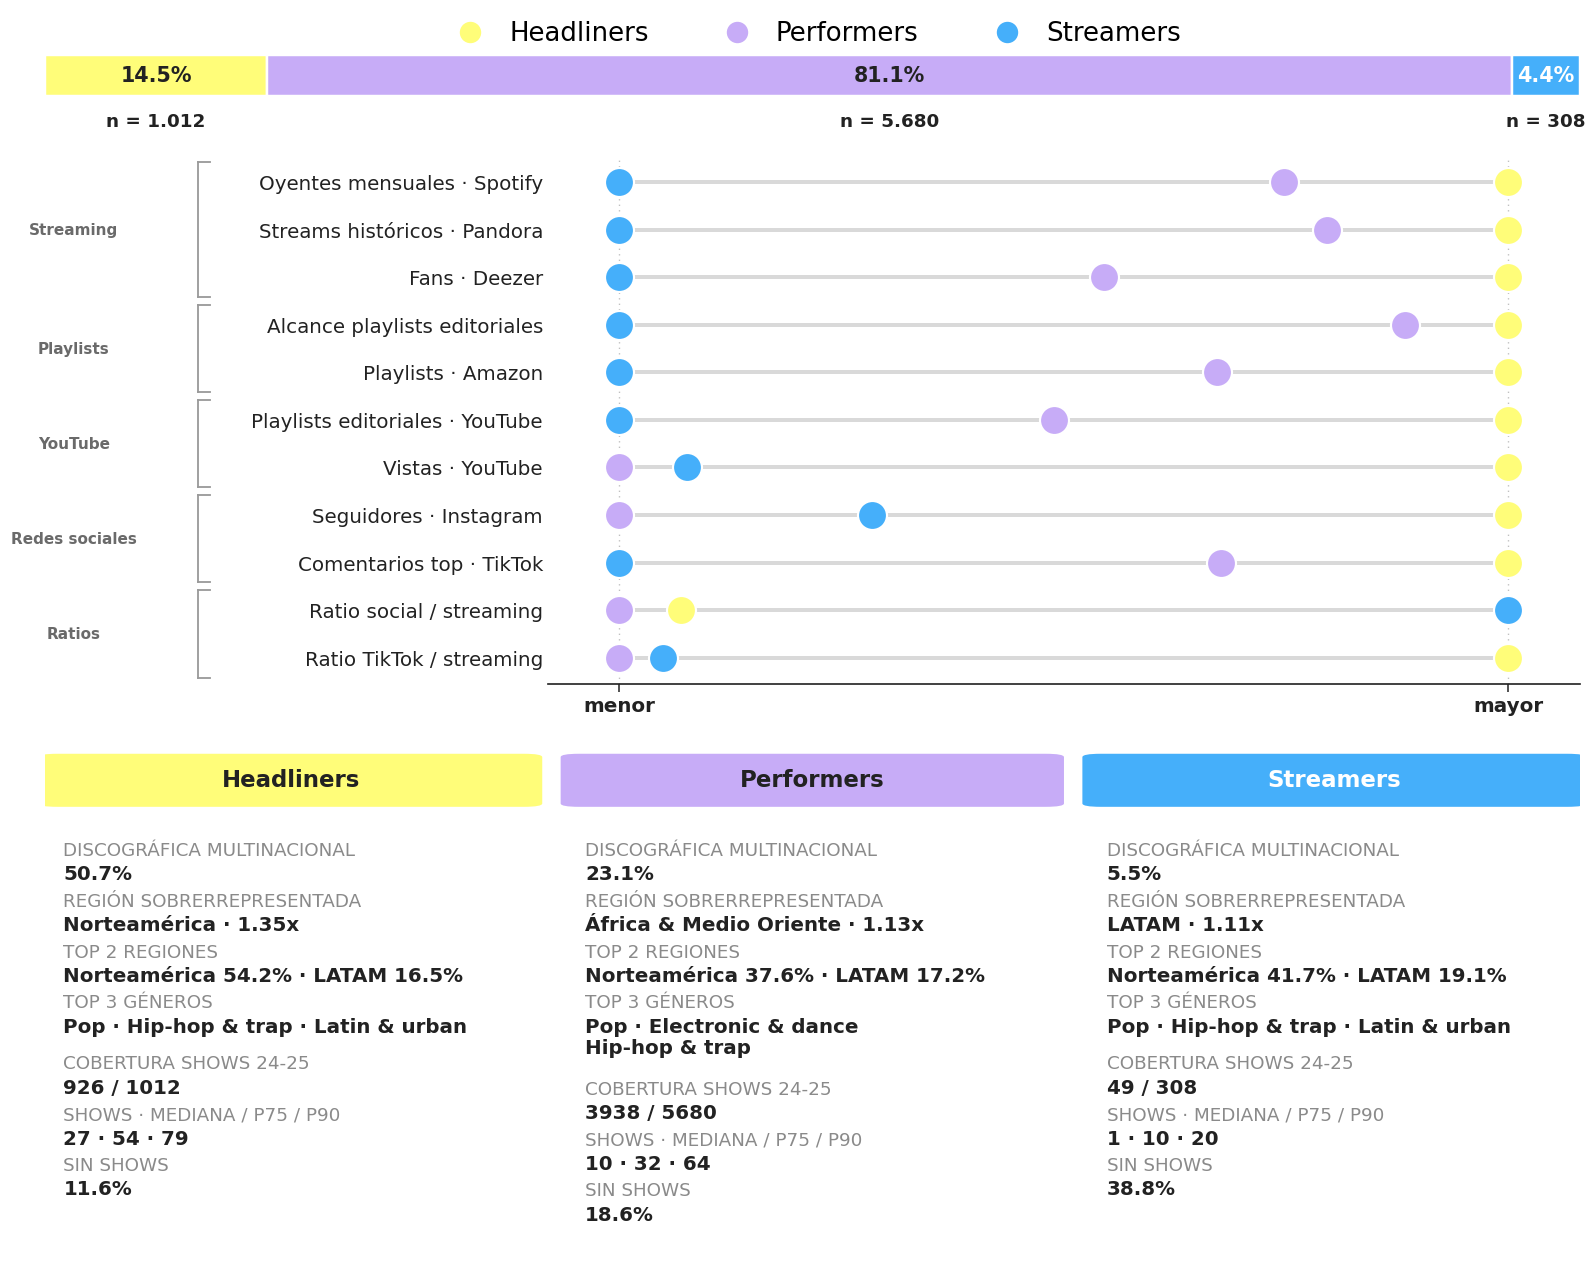

Archivo guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\perfiles_spectral_k3_dotplot.png


In [80]:
# ============================================================
# Perfiles digitales y actividad live | Spectral k=3
# Rediseno en tres bloques alineados al mismo ancho de contenido:
#   1) Barra de composicion de la solucion (% dentro del bin, n debajo)
#   2) Dot plot conectado de dimensiones digitales, agrupadas
#      por dimension con corchetes
#   3) Fichas de identidad y actividad live ex-post por cluster
# Leyenda horizontal en una sola linea, encabezando el grafico.
# ------------------------------------------------------------
# Consume objetos ya generados en el notebook:
#   - medianas_digitales_por_cluster  (dict de Series por perfil)
#   - matriz_perfiles_sp3_es          (metadata y live ex-post)
#   - predictores_digitales_spectral  (variables activas)
#   - directorio_salidas_proyecto
# ------------------------------------------------------------
# Mover estos imports a la celda central de imports del notebook
# ============================================================

import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Rectangle


# ------------------------------------------------------------
# Wrapper que parte textos largos en el separador " · " sin
# dejar lineas colgadas terminadas en el separador
# ------------------------------------------------------------

def wrap_por_separador(texto, budget, sep=" · "):
    tokens = texto.split(sep)
    lineas, actual = [], ""
    for tok in tokens:
        candidato = tok if actual == "" else actual + sep + tok
        if len(candidato) <= budget or actual == "":
            actual = candidato
        else:
            lineas.append(actual)
            actual = tok
    if actual:
        lineas.append(actual)
    return "\n".join(lineas)


def fmt_miles(valor):
    return f"{int(valor):,}".replace(",", ".")


# ------------------------------------------------------------
# Identidad de clusters
# ------------------------------------------------------------

cluster_names = {
    0: "Headliners",
    1: "Performers",
    2: "Streamers"
}

cluster_colors = {
    0: "#FFFD79",
    1: "#C7ACF7",
    2: "#45AFFA"
}

# Mapeo de nombres viejos (con los que se construyo matriz_perfiles_sp3_es
# en una celda anterior) a los nombres nuevos de esta iteracion. Ajustar
# aca si cambian los nombres nuevamente, sin tocar la celda de origen.
mapeo_nombres_viejo_a_nuevo = {
    "Headliners": "Headliners",
    "Performers": "Performers",
    "Streamers": "Streamers",
}

# Sanity check: confirmar que las columnas viejas esperadas existen
# antes de renombrar, para detectar temprano un nombre mal escrito.
columnas_no_encontradas = [
    nombre_viejo for nombre_viejo in mapeo_nombres_viejo_a_nuevo
    if nombre_viejo not in matriz_perfiles_sp3_es.columns
]
if columnas_no_encontradas:
    print("Atencion, columnas no encontradas en matriz_perfiles_sp3_es:", columnas_no_encontradas)
    print("Columnas disponibles:", list(matriz_perfiles_sp3_es.columns))

matriz_perfiles_sp3_es = matriz_perfiles_sp3_es.rename(columns=mapeo_nombres_viejo_a_nuevo)

# medianas_digitales_por_cluster tambien puede tener el nombre viejo
# como parte del index de cada Serie. Se renombra por consistencia si aplica.
for variable, serie in medianas_digitales_por_cluster.items():
    medianas_digitales_por_cluster[variable] = serie.rename(index=mapeo_nombres_viejo_a_nuevo)

orden_perfiles = ["Headliners", "Performers", "Streamers"]
color_por_perfil = {cluster_names[k]: cluster_colors[k] for k in cluster_names}

# ------------------------------------------------------------
# Grupos de dimensiones digitales.
# Definen a la vez el orden vertical (de arriba hacia abajo) y
# los corchetes. Editar aca para mover una variable de grupo.
# ------------------------------------------------------------

grupos_dimensiones = {
    "Streaming": [
        "sp_monthly_listeners",
        "pandora_lifetime_streams",
        "deezer_fans",
    ],
    "Playlists": [
        "sp_editorial_playlist_total_reach",
        "num_az_playlists",
    ],
    "YouTube": [
        "num_yt_editorial_playlists",
        "ycs_views",
    ],
    "Redes sociales": [
        "ins_followers",
        "tiktok_top_video_comments",
    ],
    "Ratios": [
        "social_sp_ratio",
        "tiktok_sp_ratio",
    ],
}

etiquetas_dimensiones = {
    "sp_monthly_listeners": "Oyentes mensuales · Spotify",
    "pandora_lifetime_streams": "Streams históricos · Pandora",
    "deezer_fans": "Fans · Deezer",
    "sp_editorial_playlist_total_reach": "Alcance playlists editoriales",
    "num_az_playlists": "Playlists · Amazon",
    "num_yt_editorial_playlists": "Playlists editoriales · YouTube",
    "ycs_views": "Vistas · YouTube",
    "ins_followers": "Seguidores · Instagram",
    "tiktok_top_video_comments": "Comentarios top · TikTok",
    "social_sp_ratio": "Ratio social / streaming",
    "tiktok_sp_ratio": "Ratio TikTok / streaming",
}

orden_dimensiones = [
    variable
    for grupo in grupos_dimensiones.values()
    for variable in grupo
    if variable in predictores_digitales_spectral
]

# ------------------------------------------------------------
# Helper para leer valores de la matriz ex-post
# ------------------------------------------------------------

def valor_matriz(atributo, perfil):
    fila = matriz_perfiles_sp3_es.loc[
        matriz_perfiles_sp3_es["Atributo"] == atributo, perfil
    ]
    return fila.iloc[0] if len(fila) > 0 else ""

# ------------------------------------------------------------
# Normalizacion de textos de metadata para las fichas
# ------------------------------------------------------------

def region_compacta(perfil):
    texto = valor_matriz("Región sobrerrepresentada", perfil)
    nombre = texto.split(" (")[0].strip()
    lift = ""
    if "|" in texto:
        lift = texto.split("|")[-1].replace(")", "").strip()
    return f"{nombre} · {lift}" if lift else nombre

def top_regiones_compacto(perfil):
    texto = valor_matriz("Top 2 regiones", perfil)
    partes = []
    for linea in texto.split("\n"):
        linea = linea.strip()
        if not linea:
            continue
        nombre = linea.split(" (")[0].strip()
        pct = linea.split("(")[-1].replace(")", "").strip() if "(" in linea else ""
        partes.append(f"{nombre} {pct}".strip())
    return " · ".join(partes)

def generos_compactos(perfil):
    texto = valor_matriz("Top 3 géneros", perfil)
    nombres = [linea.split(" (")[0].strip() for linea in texto.split("\n") if linea.strip()]
    return " · ".join(nombres)

def cobertura_compacta(perfil):
    return " ".join(valor_matriz("Cobertura n_shows_24_25", perfil).split())

def shows_distribucion(perfil):
    mediana = valor_matriz("Mediana n_shows_24_25", perfil)
    p75 = valor_matriz("p75 n_shows_24_25", perfil)
    p90 = valor_matriz("p90 n_shows_24_25", perfil)
    return f"{mediana} · {p75} · {p90}"

# ------------------------------------------------------------
# n por cluster (denominador de la cobertura) y fichas
# ------------------------------------------------------------

n_por_perfil = {}
for perfil in orden_perfiles:
    cobertura_txt = valor_matriz("Cobertura n_shows_24_25", perfil)
    n_por_perfil[perfil] = int(cobertura_txt.split("/")[1].strip())

n_total = sum(n_por_perfil.values())

fichas_datos = {}
for perfil in orden_perfiles:
    fichas_datos[perfil] = {
        "major": valor_matriz("major_record_label", perfil),
        "region_lift": region_compacta(perfil),
        "top_regiones": top_regiones_compacto(perfil),
        "generos": generos_compactos(perfil),
        "cobertura": cobertura_compacta(perfil),
        "shows_dist": shows_distribucion(perfil),
        "sin_shows": valor_matriz("% artistas con 0 shows", perfil),
    }

# ============================================================
# Figura
# ============================================================

TEXTO, GRILLA, GRIS_NEUTRO = "#222222", "#BDBDBD", "#D9D9D9"
GRIS_CORCHETE = "#9A9A9A"

plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Color de texto legible segun luminancia del color de fondo.
# Evita hardcodear "blanco" u "negro" por perfil: si se cambia
# una paleta a futuro (por ejemplo, un amarillo claro), el
# contraste se recalcula solo.
# ------------------------------------------------------------

def color_texto_legible(color_hex, umbral_luminancia=0.6):
    color_hex = color_hex.lstrip("#")
    r, g, b = (int(color_hex[i:i + 2], 16) / 255 for i in (0, 2, 4))
    luminancia = 0.299 * r + 0.587 * g + 0.114 * b
    return TEXTO if luminancia > umbral_luminancia else "white"

color_texto_por_perfil = {
    perfil: color_texto_legible(color_por_perfil[perfil])
    for perfil in orden_perfiles
}

# Sanity check: confirmar visualmente la asignacion antes de graficar
print("Color de texto asignado por perfil:")
for perfil in orden_perfiles:
    print(f"  {perfil}: fondo {color_por_perfil[perfil]} -> texto {color_texto_por_perfil[perfil]}")

# ------------------------------------------------------------
# Geometria explicita (fraccion de figura).
# La barra de composicion y las fichas usan el ANCHO COMPLETO
# (IZQ_FULL a DER_CONTENIDO). El dot plot mantiene margen
# izquierdo (IZQ_DOT) para las etiquetas de fila y los corchetes.
# ------------------------------------------------------------

IZQ_FULL = 0.035          # margen minimo a la izquierda
IZQ_DOT = 0.34            # margen del dot plot para etiquetas + corchetes
DER_CONTENIDO = 0.965

ANCHO_FULL = DER_CONTENIDO - IZQ_FULL
ANCHO_DOT = DER_CONTENIDO - IZQ_DOT
CENTRO_FULL = (IZQ_FULL + DER_CONTENIDO) / 2

fig = plt.figure(figsize=(15, 12), facecolor="#FFFFFF")

# [izquierda, abajo, ancho, alto] de cada bloque
rect_comp   = [IZQ_FULL, 0.875, ANCHO_FULL, 0.060]
rect_dot    = [IZQ_DOT,  0.455, ANCHO_DOT,  0.400]
rect_fichas = [IZQ_FULL, 0.020, ANCHO_FULL, 0.385]

# ------------------------------------------------------------
# Leyenda horizontal en una sola linea, encabezando el grafico
# ------------------------------------------------------------

handles_leyenda = [
    Line2D([0], [0], marker="o", linestyle="none", markersize=14,
           markerfacecolor=color_por_perfil[p], markeredgecolor="none", label=p)
    for p in orden_perfiles
]
fig.legend(
    handles=handles_leyenda,
    loc="upper center", bbox_to_anchor=(CENTRO_FULL, 0.975),
    ncol=3, frameon=False, fontsize=17, handletextpad=0.5, columnspacing=2.4
)

# ------------------------------------------------------------
# Bloque 1: barra de composicion (% dentro del bin, n debajo)
# ------------------------------------------------------------

ax_comp = fig.add_axes(rect_comp)
ax_comp.set_xlim(0, 1)
ax_comp.set_ylim(0, 1)
ax_comp.axis("off")

altura_barra = 0.52
y_barra = 0.42
x_acumulado = 0.0

for perfil in orden_perfiles:

    proporcion = n_por_perfil[perfil] / n_total
    color = color_por_perfil[perfil]
    centro = x_acumulado + proporcion / 2

    ax_comp.add_patch(Rectangle(
        (x_acumulado, y_barra), proporcion, altura_barra,
        facecolor=color, edgecolor="white", linewidth=1.6
    ))
    ax_comp.text(
        centro, y_barra + altura_barra / 2, f"{proporcion * 100:.1f}%",
        ha="center", va="center", fontsize=13.5, fontweight="bold",
        color=color_texto_por_perfil[perfil], clip_on=False
    )
    ax_comp.text(
        centro, y_barra - 0.20, f"n = {fmt_miles(n_por_perfil[perfil])}",
        ha="center", va="top", fontsize=12, fontweight="bold",
        color=TEXTO, clip_on=False
    )
    x_acumulado += proporcion

# ------------------------------------------------------------
# Bloque 2: dot plot conectado, escala relativa por variable
# ------------------------------------------------------------

ax = fig.add_axes(rect_dot)
ax.set_facecolor("#FFFFFF")

posiciones_y = np.arange(len(orden_dimensiones))[::-1]
y_por_variable = {variable: posiciones_y[i] for i, variable in enumerate(orden_dimensiones)}

TAMANIO_CIRCULO = 360  # agrandado para mayor presencia

for variable in orden_dimensiones:

    serie = medianas_digitales_por_cluster[variable].reindex(orden_perfiles).astype(float)
    minimo, maximo = serie.min(), serie.max()
    rango = maximo - minimo if maximo > minimo else 1.0
    relativos = (serie - minimo) / rango

    y = y_por_variable[variable]

    ax.plot(
        [relativos.min(), relativos.max()], [y, y],
        color=GRIS_NEUTRO, linewidth=2.6, solid_capstyle="round", zorder=1
    )
    for perfil in orden_perfiles:
        ax.scatter(
            relativos[perfil], y,
            s=TAMANIO_CIRCULO, color=color_por_perfil[perfil],
            edgecolor="white", linewidth=1.4, zorder=3
        )

ax.set_yticks(posiciones_y)
ax.set_yticklabels(
    [etiquetas_dimensiones[v] for v in orden_dimensiones],
    fontsize=13, color=TEXTO
)
ax.set_xlim(-0.08, 1.08)
ax.set_xticks([0, 1])
ax.set_xticklabels(["menor", "mayor"], fontsize=13, fontweight="bold", color=TEXTO)
# Interlineado compacto: menos margen vertical alrededor de las filas
ax.set_ylim(-0.55, len(orden_dimensiones) - 0.45)

ax.grid(axis="x", linestyle=(0, (1, 3)), linewidth=0.9, color=GRILLA, alpha=0.95)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(TEXTO)
ax.spines["bottom"].set_linewidth(1.1)
ax.tick_params(axis="x", length=5, width=1, color=TEXTO)
ax.tick_params(axis="y", length=0)

# ------------------------------------------------------------
# Corchetes de agrupamiento por dimension, a la izquierda
# Ajustar x_corchete si se solapa con las etiquetas del eje Y
# ------------------------------------------------------------

trans_corchete = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)

# x en fraccion de ejes. Ajustar si pisan las etiquetas del eje Y.
x_corchete = -0.34
largo_punta = 0.012
x_etiqueta_grupo = -0.46   # rotulo horizontal en la banda izquierda

for grupo, variables_grupo in grupos_dimensiones.items():

    ys_grupo = [y_por_variable[v] for v in variables_grupo if v in y_por_variable]
    if not ys_grupo:
        continue

    y_inferior = min(ys_grupo) - 0.42
    y_superior = max(ys_grupo) + 0.42

    ax.plot([x_corchete, x_corchete], [y_inferior, y_superior],
            transform=trans_corchete, color=GRIS_CORCHETE, linewidth=1.2, clip_on=False)
    ax.plot([x_corchete, x_corchete + largo_punta], [y_superior, y_superior],
            transform=trans_corchete, color=GRIS_CORCHETE, linewidth=1.2, clip_on=False)
    ax.plot([x_corchete, x_corchete + largo_punta], [y_inferior, y_inferior],
            transform=trans_corchete, color=GRIS_CORCHETE, linewidth=1.2, clip_on=False)

    ax.text(
        x_etiqueta_grupo, (min(ys_grupo) + max(ys_grupo)) / 2, grupo,
        transform=trans_corchete, rotation=0, ha="center", va="center",
        fontsize=10, fontweight="bold", color="#6A6A6A", clip_on=False
    )

# Titulo comentado por defecto (activar si se pide)
# fig.suptitle("Perfiles digitales y actividad live | Spectral k=3",
#              fontsize=22, fontweight="bold", y=0.995)

# ------------------------------------------------------------
# Bloque 3: fichas por cluster, ancho completo del contenido
# Tres columnas de 0 a 1, alineadas con la barra de composicion
# ------------------------------------------------------------

ax_fichas = fig.add_axes(rect_fichas)
ax_fichas.set_xlim(0, 1)
ax_fichas.set_ylim(0, 1)
ax_fichas.axis("off")

gap_entre_fichas = 0.02
ancho_ficha = (1 - 2 * gap_entre_fichas) / 3
pad_texto = 0.012

# Campos: (etiqueta, clave, ancho_wrap, abre_bloque_live)
# Budgets amplios: con las fichas anchas casi todo entra en 1 linea
campos_ficha = [
    ("Discográfica multinacional", "major", 40, False),
    ("Región sobrerrepresentada", "region_lift", 40, False),
    ("Top 2 regiones", "top_regiones", 40, False),
    ("Top 3 géneros", "generos", 40, False),
    ("Cobertura shows 24-25", "cobertura", 40, True),
    ("Shows · mediana / p75 / p90", "shows_dist", 40, False),
    ("Sin shows", "sin_shows", 40, False),
]

# Constantes de espaciado vertical. Subir gap_base si quedan apretados.
gap_base = 0.10
gap_extra = 0.05
y_inicio_campos = 0.82

for idx, perfil in enumerate(orden_perfiles):

    x0 = idx * (ancho_ficha + gap_entre_fichas)
    color = color_por_perfil[perfil]

    ax_fichas.add_patch(FancyBboxPatch(
        (x0, 0.89), ancho_ficha, 0.10,
        boxstyle="round,pad=0.004,rounding_size=0.012",
        facecolor=color, edgecolor="none", mutation_aspect=0.55
    ))
    ax_fichas.text(
        x0 + ancho_ficha / 2, 0.94, perfil,
        ha="center", va="center", color=color_texto_por_perfil[perfil],
        fontsize=15, fontweight="bold"
    )

    datos = fichas_datos[perfil]
    y_campo = y_inicio_campos

    for etiqueta, clave, ancho_wrap, abre_bloque_live in campos_ficha:

        if abre_bloque_live:
            # y_divisor = y_campo + 0.028
            # ax_fichas.plot(
            #     [x0 + pad_texto, x0 + ancho_ficha - pad_texto], [y_divisor, y_divisor],
            #     color="#E2E2E2", linewidth=1.0
            # )
            y_campo -= 0.020

        ax_fichas.text(
            x0 + pad_texto, y_campo, etiqueta.upper(),
            ha="left", va="top", color="#8A8A8A", fontsize=12
        )
        valor_envuelto = wrap_por_separador(str(datos[clave]), ancho_wrap)
        n_lineas = valor_envuelto.count("\n") + 1
        ax_fichas.text(
            x0 + pad_texto, y_campo - 0.046, valor_envuelto,
            ha="left", va="top", color=TEXTO,
            fontsize=13, fontweight="bold", linespacing=1.12
        )
        y_campo -= (gap_base + gap_extra * (n_lineas - 1))

# ============================================================
# Guardado unico en PNG
# ============================================================

archivo_perfiles_sp3 = (
    directorio_salidas_proyecto /
    "perfiles_spectral_k3_dotplot.png"
)

fig.savefig(
    archivo_perfiles_sp3,
    dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor()
)

plt.show()

print("Archivo guardado en:", archivo_perfiles_sp3)

# Anexo B.2: composición de los perfiles por género musical y territorio

Celda autocontenida (lee `dataset_7000_53.csv`): recalcula la solución Spectral k = 3 con el mismo preprocesamiento de este notebook (imputación, log1p, ratios y escalado), ordena los clusters por mediana de shows (Headliners, Performers, Streamers) y muestra el porcentaje de cada género y territorio dentro de cada perfil frente a la muestra total. Guarda `graficos/anexo_b2_composicion_perfiles_genero_territorio.png`.

In [ ]:
# ============================================================
# Anexo B.2 | Composición de los perfiles digitales (Spectral k = 3)
# por género musical y territorio
# Base: 7.000 artistas. Se recalcula la solución Spectral k = 3 con el
# mismo preprocesamiento del notebook de clustering, para que la celda
# sea autocontenida. Los clusters se ordenan por mediana de shows:
# Headliners, Performers y Streamers.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import SpectralClustering

directorio_salidas = Path("graficos")
directorio_salidas.mkdir(exist_ok=True)

color_texto = "#222222"
color_secundario = "#5F6368"
plt.rcParams["font.family"] = "DejaVu Sans"
mapa_grises = LinearSegmentedColormap.from_list("grises", ["#FFFFFF", "#3A3A3A"])

# ------------------------------------------------------------
# Spectral k = 3 (mismo preprocesamiento que CT_SC_clustering_varios)
# ------------------------------------------------------------
df = pd.read_csv("dataset_7000_53.csv")

variables_base = ["sp_monthly_listeners", "sp_editorial_playlist_total_reach", "num_az_playlists",
                  "num_yt_editorial_playlists", "pandora_lifetime_streams", "deezer_fans",
                  "ins_followers", "ycs_views", "tiktok_top_video_comments"]
imputar_cero = ["sp_editorial_playlist_total_reach", "num_az_playlists", "num_yt_editorial_playlists",
                "pandora_lifetime_streams", "deezer_fans", "tiktok_top_video_comments"]
imputar_mediana = ["sp_monthly_listeners", "ins_followers", "ycs_views"]

imputado = df[variables_base].copy()
imputado[imputar_cero] = imputado[imputar_cero].fillna(0)
imputado[imputar_mediana] = imputado[imputar_mediana].fillna(imputado[imputar_mediana].median())
logs = imputado.apply(np.log1p)
logs["log_ins_sp_ratio"] = logs["ins_followers"] - logs["sp_monthly_listeners"]
logs["log_tiktok_sp_ratio"] = logs["tiktok_top_video_comments"] - logs["sp_monthly_listeners"]
X_sc = StandardScaler().fit_transform(logs)

etiquetas = SpectralClustering(n_clusters=3, affinity="nearest_neighbors", n_neighbors=30,
                               assign_labels="kmeans", n_init=10, random_state=42,
                               n_jobs=-1).fit_predict(X_sc)
orden = df.groupby(etiquetas)["n_shows_24_25"].median().sort_values(ascending=False).index
nombres = dict(zip(orden, ["Headliners", "Performers", "Streamers"]))
df["perfil"] = pd.Series(etiquetas).map(nombres)
print(df["perfil"].value_counts())

# ------------------------------------------------------------
# Composición porcentual dentro de cada perfil
# ------------------------------------------------------------
etiquetas_territorio = {
    "North America": "Norteamérica", "LATAM": "LATAM", "Europe_sinGB": "Europa (sin Gran Bretaña)",
    "Great Britain": "Gran Bretaña", "Asia & Oceania": "Asia y Oceanía", "Africa & ME": "África y Medio Oriente",
}
df["territorio"] = df["country_short"].map(etiquetas_territorio)
df["genero"] = df["genre_short"].str.strip()
columnas = ["Headliners", "Performers", "Streamers", "Muestra total"]


def miles(n):
    """Entero con punto como separador de miles."""
    return f"{int(round(n)):,}".replace(",", ".")


def composicion(variable):
    base = df.dropna(subset=[variable])
    tabla = pd.crosstab(base[variable], base["perfil"], normalize="columns") * 100
    tabla["Muestra total"] = base[variable].value_counts(normalize=True) * 100
    return tabla[columnas].sort_values("Muestra total", ascending=False)


paneles = [("genero", "Género musical"), ("territorio", "Territorio")]
tablas = {variable: composicion(variable) for variable, _ in paneles}
for t in tablas.values():
    display(t.round(1))

tamanios = df["perfil"].value_counts()
encabezados = [f"{c}\n(n = {miles(tamanios[c])})" for c in columnas[:3]] + [f"Muestra total\n(n = {miles(len(df))})"]
tope = max(t.to_numpy().max() for t in tablas.values())

alturas = [len(tablas[v]) for v, _ in paneles]
fig, axes = plt.subplots(2, 1, figsize=(9, 0.42 * sum(alturas) + 2.2),
                         gridspec_kw={"height_ratios": alturas, "hspace": 0.18})

for ax, (variable, titulo) in zip(axes, paneles):
    t = tablas[variable]
    valores = t.to_numpy()
    ax.imshow(valores, cmap=mapa_grises, vmin=0, vmax=tope, aspect="auto")
    for i in range(valores.shape[0]):
        for j in range(valores.shape[1]):
            v = valores[i, j]
            ax.text(j, i, f"{v:.1f}".replace(".", ",") + " %", ha="center", va="center", fontsize=9.5,
                    color="white" if v > tope * 0.5 else color_texto,
                    fontweight="bold" if j < 3 else "normal")
    # Separación visual entre perfiles y muestra total
    ax.axvline(2.5, color="white", linewidth=6)
    ax.set_yticks(range(len(t)))
    ax.set_yticklabels(t.index, fontsize=10, color=color_texto)
    ax.set_xticks(range(len(columnas)))
    ax.set_xticklabels(encabezados if variable == "genero" else [], fontsize=10, color=color_texto)
    ax.xaxis.tick_top()
    ax.set_ylabel(titulo, fontsize=11, fontweight="bold", color=color_texto, labelpad=10)
    ax.tick_params(length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)

ruta = directorio_salidas / "anexo_b2_composicion_perfiles_genero_territorio.png"
fig.savefig(ruta, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Guardado en: {ruta}")